# Agentic AI Radar — Stage 1: Agentic Web discourse and knowledge graph

**Project:** Agentic AI Radar — Tracking the Rise of Autonomous AI Agents · **Track:** Agentic Web · **Stage:** 1 — data cleaning, NLP analysis and knowledge-graph construction · **Student:** Leon Bytyqi (individual submission)

**Research objective.** This notebook examines how autonomous, tool-using and multi-agent AI systems are represented in the assigned AI Media Dataset. Media mentions are evidence about reporting, not proof of deployment, adoption or real-world relationships.

## Research questions
1. How does the volume and relative share of Agentic Web coverage change from September 2024 through August 2026?
2. Which publishers, organizations and named AI technologies are prominent in the selected coverage?
3. What interpretable lexical themes occur in the selected articles, and how does their share of coverage change over time?
4. Which entities are reported together (article-level co-mentions), and which evidence-linked directed relation *candidates* can be extracted — kept separate from verified facts — in a provenance-preserving graph?

**Methods at a glance.** Inspect the live KaggleHub dataset schema; parse and clean the source text without discarding its raw form; remove exact duplicate text; select articles with an auditable phrase/tag rule; describe coverage; fit TF–IDF/NMF topics on a lemmatized, acronym-normalized view and test their stability; combine spaCy named-entity recognition with an explicit domain alias lexicon and conservative name normalization; build sentence-level `MENTIONED_WITH` co-occurrence edges and, separately, typed directed relation candidates; analyse graph structure and its threshold sensitivity; validate artifacts and provide transparent review worksheets.

**Scope and limitations.** The assignment is the professor's official brief, `CLT_AI_Trend_Project.pdf` (Stage 1, pp. 2–3; contribution and AI-disclosure rules, p. 5). Dataset version 2 describes a September 2024–September 2026 collection, while the assignment scope ends in August 2026. This notebook analyzes dates September 2024–August 2026 inclusive. Keyword selection is a reproducible proxy, not ground truth. NLP errors, publisher selection, duplicate syndication, uneven monthly coverage and the dataset's own tags can bias findings. Co-mentions are not relations, and no directed relation candidate is a verified fact. No human labelling has yet been performed on any worksheet in this notebook, so no precision/recall is reported. Stage 2 and Stage 3 are deliberately out of scope.

**Expected contribution.** A reproducible corpus and article-provenance-aware, conservative exploration of the Agentic Web, with reusable tables and graphs suitable for later research. Data-dependent statements in this notebook are produced by executed cells and, where they interpret results, are checked by code assertions.

## Individual contribution statement

Stage 1 of Agentic AI Radar — Tracking the Rise of Autonomous AI Agents was completed by Leon Bytyqi as the sole student contributor.

Leon Bytyqi directed and oversaw Stage 1, including selecting the Agentic Web research track, defining the analytical objectives, making project and methodological decisions, reviewing the outputs, interpreting the findings, and preparing the submission.

AI tools drafted the code and supported implementation, debugging, and documentation. AI involvement is disclosed separately below.

Individual submission is permitted and has been confirmed by the student.

## AI-use disclosure (professor requirement, brief p. 5)

GitHub Copilot and AI language models drafted the code for Stage 1 of this project. Leon Bytyqi directed the project, specified the analytical objectives, oversaw implementation, and was responsible for reviewing the generated results, interpreting the findings, and documenting methodological limitations. AI tools were also used for debugging and documentation.

This disclosure states roles and responsibilities. It does not claim that Leon Bytyqi manually wrote the AI-drafted code, and it does not claim that any human review or validation beyond the executed checks in this notebook has taken place. The human-review worksheets in `outputs/evaluations/` are unlabelled.

**Additional AI use in the analysis (not code drafting).** For the structured-extraction pilot in section 7.1, text from the public dataset (50 articles) was sent to OpenAI's `gpt-4o-mini` model through the LangExtract library to extract entities and relations. Its outputs are unreviewed candidates and are labelled as such. The API key is kept in a git-ignored `.env` file and is not part of the notebook or any output.

## 1. Reproducibility, acquisition and source audit

The latest dataset is obtained using the required KaggleHub identifier. The loader enumerates available files and inspects the actual CSV headers before mapping fields. `Unnamed: 0` is treated as an identifier only if it exists and is unique; otherwise a deterministic content-based ID is used. The dataset describes an MIT licence; article-level copyright and redistribution terms should still be checked before sharing full-text exports.

In [1]:
from __future__ import annotations

import ast
import hashlib
import html
import json
import platform
import re
import sys
import unicodedata
from collections import Counter, defaultdict
from datetime import datetime, timezone
from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import scipy
import sklearn
import spacy
from IPython.display import display
from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, CountVectorizer, TfidfTransformer, TfidfVectorizer
from sklearn.metrics import adjusted_rand_score
from sklearn.metrics.pairwise import cosine_similarity
from scipy.optimize import linear_sum_assignment
from scipy.sparse import csr_matrix
from scipy.stats import spearmanr

SEED = 20261011
DATASET_REF = "jannalipenkova/ai-media-dataset"
DATE_START = pd.Timestamp("2024-09-01")
DATE_END_EXCLUSIVE = pd.Timestamp("2026-09-01")
SUBSET_RULE_VERSION = "agentic-web-lexicon-v2"
ROOT = next((parent for parent in (Path.cwd(), *Path.cwd().parents) if (parent / "requirements-stage1.txt").exists()), Path.cwd())
PROCESSED_DIR = ROOT / "data" / "processed"
TABLE_DIR = ROOT / "outputs" / "tables"
FIGURE_DIR = ROOT / "outputs" / "figures"
GRAPH_DIR = ROOT / "outputs" / "graph"
EVALUATION_DIR = ROOT / "outputs" / "evaluations"
for directory in (PROCESSED_DIR, TABLE_DIR, FIGURE_DIR, GRAPH_DIR, EVALUATION_DIR):
    directory.mkdir(parents=True, exist_ok=True)

print({"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
       "scikit_learn": sklearn.__version__, "scipy": scipy.__version__, "networkx": nx.__version__,
       "spacy": spacy.__version__, "seed": SEED})


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.3.3 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/Users/kushtrimbytyqi/Library/Python/3.11/lib/python/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/Users/kushtrimbytyqi/Library/Python/3.11/lib/python/site-packages/traitlets/config/application.py", line 1080, in launch_instance
    app.start()
  File "/Users/kushtrimbytyqi/Library/Python/3.11/lib/python/site-packages/ipykernel/kernelapp.py", line 768, in start

{'python': '3.11.9', 'pandas': '3.0.5', 'numpy': '2.3.3', 'scikit_learn': '1.7.2', 'scipy': '1.16.2', 'networkx': '3.5', 'spacy': '3.8.16', 'seed': 20261011}


In [2]:
dataset_path = Path(kagglehub.dataset_download(DATASET_REF))
KAGGLE_VERSION = dataset_path.name if dataset_path.parent.name == "versions" else "unknown"
dataset_files = sorted(path for path in dataset_path.rglob("*") if path.is_file())
if not dataset_files:
    raise FileNotFoundError(f"KaggleHub returned no files for {DATASET_REF}: {dataset_path}")
file_inventory = pd.DataFrame([
    {"path": str(path.relative_to(dataset_path)), "bytes": path.stat().st_size,
     "suffix": path.suffix.lower()} for path in dataset_files
])
display(file_inventory)
csv_files = [path for path in dataset_files if path.suffix.lower() == ".csv"]
if len(csv_files) != 1:
    raise ValueError(f"Expected one CSV dataset file after inspection; found {len(csv_files)}: {csv_files}")
source_file = csv_files[0]
header = pd.read_csv(source_file, nrows=0, encoding="utf-8", encoding_errors="replace")
source_columns = list(header.columns)
print("Dataset path:", source_file)
print("Observed schema:", source_columns)
print("Source file bytes:", source_file.stat().st_size)

,path,bytes,suffix
0,ai_media_dataset_20260911.csv,529709045,.csv


Dataset path: /Users/kushtrimbytyqi/.cache/kagglehub/datasets/jannalipenkova/ai-media-dataset/versions/2/ai_media_dataset_20260911.csv
Observed schema: ['Unnamed: 0', 'title', 'date', 'content', 'domain', 'url', 'tags']
Source file bytes: 529709045


In [3]:
def normalized_column_name(name: object) -> str:
    """Normalize a source column label for evidence-based field mapping."""
    return re.sub(r"[^a-z0-9]+", "", str(name).casefold())


def find_column(columns: list[str], candidates: tuple[str, ...], required: bool = False) -> str | None:
    """Find an observed source column by a small set of documented aliases."""
    lookup = {normalized_column_name(column): column for column in columns}
    for candidate in candidates:
        if normalized_column_name(candidate) in lookup:
            return lookup[normalized_column_name(candidate)]
    if required:
        raise ValueError(f"Required field not found. Tried {candidates}; observed columns: {columns}")
    return None


column_map = {
    "title": find_column(source_columns, ("title",)),
    "date": find_column(source_columns, ("date", "published_at", "publication_date"), required=True),
    "content": find_column(source_columns, ("content", "text", "article_text", "body"), required=True),
    "source": find_column(source_columns, ("domain", "source", "publisher")),
    "url": find_column(source_columns, ("url", "link")),
    "tags": find_column(source_columns, ("tags", "tag")),
    "source_id": find_column(source_columns, ("article_id", "id", "unnamed: 0")),
}
print("Observed-to-canonical mapping:", column_map)
raw_df = pd.read_csv(source_file, dtype="string", encoding="utf-8", encoding_errors="replace", low_memory=False)
if raw_df.empty:
    raise ValueError(f"Dataset CSV contains no records: {source_file}")
source_id_is_unique = bool(
    column_map["source_id"] is not None
    and raw_df[column_map["source_id"]].notna().all()
    and raw_df[column_map["source_id"]].astype(str).is_unique
)
article_id_basis = column_map["source_id"] if source_id_is_unique else "sha256(url,title,text_clean)"
print("Article-ID basis:", article_id_basis)
audit = pd.DataFrame({
    "column": raw_df.columns,
    "dtype": raw_df.dtypes.astype(str).values,
    "missing_count": raw_df.isna().sum().values,
    "missing_percent": (raw_df.isna().mean().values * 100).round(3),
})
print("Raw shape:", raw_df.shape)
display(audit)
print("Raw exact-row duplicate count:", int(raw_df.duplicated().sum()))

Observed-to-canonical mapping: {'title': 'title', 'date': 'date', 'content': 'content', 'source': 'domain', 'url': 'url', 'tags': 'tags', 'source_id': 'Unnamed: 0'}


Article-ID basis: Unnamed: 0
Raw shape: (47751, 7)


,column,dtype,missing_count,missing_percent
0,Unnamed: 0,string,0,0.0
1,title,string,0,0.0
2,date,string,0,0.0
3,content,string,0,0.0
4,domain,string,0,0.0
5,url,string,0,0.0
6,tags,string,0,0.0


Raw exact-row duplicate count: 0


## 2. Cleaning and canonical article records

The source `content` field is a serialized list of paragraphs in the observed version. Parsing uses `ast.literal_eval` rather than executing source text. Text is preserved in `text_raw`; `text_clean` applies Unicode NFC normalization, HTML entity/tag cleanup, URL removal and whitespace normalization without lowercasing or removing names. Only exact duplicate cleaned article texts are removed (first source occurrence retained); near-duplicates are not automatically removed because syndication variants can be analytically meaningful. Invalid dates and unusable text are counted and excluded, not silently coerced into observations.

In [4]:
def parse_text_field(value: object) -> tuple[str, str, bool]:
    """Return preserved readable source text, cleaned text, and parse-fallback status."""
    if pd.isna(value):
        return "", "", False
    raw_value = str(value)
    try:
        parsed = ast.literal_eval(raw_value)
    except (ValueError, SyntaxError):
        parsed = raw_value
        parse_fallback = True
    else:
        parse_fallback = False
    if isinstance(parsed, (list, tuple)):
        raw_text = "\n".join(str(part) for part in parsed if part is not None)
    elif isinstance(parsed, str):
        raw_text = parsed
    else:
        raw_text = str(parsed)
    clean = unicodedata.normalize("NFC", html.unescape(raw_text))
    clean = re.sub(r"(?is)<(script|style).*?>.*?</\1>", " ", clean)
    clean = re.sub(r"(?s)<[^>]+>", " ", clean)
    clean = re.sub(r"https?://\S+|www\.\S+", " ", clean)
    clean = re.sub(r"\s+", " ", clean).strip()
    return raw_text, clean, parse_fallback


def stable_article_id(source_id: object, url: object, title: object, text: str) -> str:
    """Use a unique observed source ID, or derive a deterministic fallback hash."""
    if source_id is not None and not pd.isna(source_id) and str(source_id).strip():
        return str(source_id).strip()
    material = "\x1f".join(str(value or "") for value in (url, title, text))
    return hashlib.sha256(material.encode("utf-8", errors="replace")).hexdigest()


def parse_tags(value: object) -> list[str]:
    """Parse a serialized tag list without evaluating executable code."""
    if pd.isna(value):
        return []
    try:
        parsed = ast.literal_eval(str(value))
    except (ValueError, SyntaxError):
        return [part.strip() for part in re.split(r"[,;|]", str(value)) if part.strip()]
    if isinstance(parsed, (list, tuple, set)):
        return [str(item).strip() for item in parsed if str(item).strip()]
    return [str(parsed).strip()] if str(parsed).strip() else []


records = []
parse_fallback_count = 0
missing_text_count = 0
for row in raw_df.to_dict(orient="records"):
    source_content = row[column_map["content"]]
    text_raw, text_clean, parse_fallback = parse_text_field(source_content)
    parse_fallback_count += int(parse_fallback)
    missing_text_count += int(not text_clean)
    title = "" if column_map["title"] is None or pd.isna(row[column_map["title"]]) else str(row[column_map["title"]]).strip()
    raw_date = row[column_map["date"]]
    parsed_date = pd.to_datetime(raw_date, errors="coerce", utc=True)
    source_id = row[column_map["source_id"]] if source_id_is_unique else None
    tags = [] if column_map["tags"] is None else parse_tags(row[column_map["tags"]])
    records.append({
        "article_id": stable_article_id(source_id, row.get(column_map["url"]) if column_map["url"] else None, title, text_clean),
        "title": title, "date": parsed_date, "source": None if column_map["source"] is None else row[column_map["source"]],
        "url": None if column_map["url"] is None else row[column_map["url"]], "tags": tags,
        "text_raw": text_raw, "text_clean": text_clean,
    })
articles_all = pd.DataFrame.from_records(records)
invalid_date_count = int(articles_all["date"].isna().sum())
outside_window_count = int((articles_all["date"].notna() & ~articles_all["date"].between(DATE_START.tz_localize("UTC"), (DATE_END_EXCLUSIVE - pd.Timedelta(nanoseconds=1)).tz_localize("UTC"))).sum())
articles = articles_all.loc[
    articles_all["date"].notna()
    & articles_all["date"].between(DATE_START.tz_localize("UTC"), (DATE_END_EXCLUSIVE - pd.Timedelta(nanoseconds=1)).tz_localize("UTC"))
    & articles_all["text_clean"].ne("")
].copy()
articles["date"] = articles["date"].dt.tz_convert(None)
articles["_text_hash"] = articles["text_clean"].map(lambda text: hashlib.sha256(text.encode("utf-8")).hexdigest())
duplicate_text_count = int(articles["_text_hash"].duplicated().sum())
duplicate_url_count = int(articles["url"].dropna().duplicated().sum())
articles = articles.drop_duplicates("_text_hash", keep="first").drop(columns="_text_hash").reset_index(drop=True)
if articles["article_id"].duplicated().any():
    raise ValueError("Canonical article_id is not unique after cleaning; inspect source identifier mapping.")
cleaning_counts = pd.DataFrame([
    {"step": "source rows", "records": len(raw_df)},
    {"step": "invalid publication date", "records": invalid_date_count},
    {"step": "outside Sep 2024–Aug 2026 window", "records": outside_window_count},
    {"step": "missing or unusable text", "records": missing_text_count},
    {"step": "content parse fallback", "records": parse_fallback_count},
    {"step": "exact duplicate cleaned text removed", "records": duplicate_text_count},
    {"step": "duplicate URL occurrences (reported; not independently dropped)", "records": duplicate_url_count},
    {"step": "final cleaned articles", "records": len(articles)},
])
display(cleaning_counts)
print("Date coverage:", articles["date"].min(), "through", articles["date"].max())
display(articles[["article_id", "title", "date", "source", "text_raw", "text_clean"]].head(3).assign(
    text_raw=lambda frame: frame["text_raw"].str.slice(0, 260),
    text_clean=lambda frame: frame["text_clean"].str.slice(0, 260),
))

,step,records
0,source rows,47751
1,invalid publication date,0
2,outside Sep 2024–Aug 2026 window,243
3,missing or unusable text,0
4,content parse fallback,0
5,exact duplicate cleaned text removed,65
6,duplicate URL occurrences (reported; not indep...,0
7,final cleaned articles,47443


Date coverage: 2024-09-11 00:00:00 through 2026-08-31 00:00:00


,article_id,title,date,source,text_raw,text_clean
0,72316,Top 10 AI Companies in UK & Europe,2024-09-11,aimagazine,With the field of AI accelerating all the time...,With the field of AI accelerating all the time...
1,139940,“ Winner ” Takes Political Comedy Seriously,2024-09-11,newyorker,"This was in 2017, and she believed that the pu...","This was in 2017, and she believed that the pu..."
2,55797,Optimizing Sustainable Construction with Smart...,2024-09-11,azobuild,A new study is shedding light on the latest in...,A new study is shedding light on the latest in...


## 3. Agentic Web selection and audit

The rule uses a curated list of Agentic Web phrases rather than the bare word “agent”: an article qualifies when its title or body contains at least one phrase match. A fixed-seed audit of the one- and two-hit stratum is included because requiring several body matches can exclude clearly relevant reports that discuss an agent technology briefly. Agent-related dataset tags are retained as metadata but do not independently qualify an article. This lexical screen can still admit incidental references and miss articles that use different terminology; the stratified audit worksheet supports human review of selected, low-evidence, tag-only, and no-signal records.

In [5]:
AGENTIC_PHRASE = re.compile(
    r"\bagentic\b|\b(?:ai|artificial intelligence|llm|large language model)\s+(?:software\s+)?agents?\b|"
    r"\b(?:autonomous|tool[- ](?:using|enabled)|multi[- ]agent|llm[- ]based)\s+agents?\b|"
    r"\bagent\s+(?:framework|workflow|orchestrat|platform)|"
    r"\b(?:agentic\s+(?:workflow|system|framework|web)|multi[- ]agent\s+(?:system|framework|workflow)|"
    r"agent[- ]based\s+(?:ai|artificial intelligence))",
    flags=re.IGNORECASE,
)
AGENT_TAG = re.compile(r"agent", flags=re.IGNORECASE)


def select_agentic_web(row: pd.Series) -> tuple[bool, str, int, int, bool]:
    """Apply the frozen, auditable lexical/tag rule and return its evidence."""
    title_hits = len(AGENTIC_PHRASE.findall(str(row["title"])))
    body_hits = len(AGENTIC_PHRASE.findall(str(row["text_clean"])))
    agent_tag = any(AGENT_TAG.search(tag) for tag in row["tags"])
    selected = bool(title_hits or body_hits >= 1)
    reason = "title_phrase" if title_hits else "body_phrase" if body_hits >= 1 else "not_selected"
    return selected, reason, title_hits, body_hits, agent_tag


selection = articles.apply(select_agentic_web, axis=1, result_type="expand")
selection.columns = ["is_agentic_web", "selection_reason", "title_phrase_hits", "body_phrase_hits", "agent_related_tag"]
articles = pd.concat([articles, selection], axis=1)
articles["subset_rule_version"] = SUBSET_RULE_VERSION
agentic = articles.loc[articles["is_agentic_web"]].copy().reset_index(drop=True)
if agentic.empty:
    raise ValueError("Agentic Web rule selected no articles; inspect field mapping and corpus before proceeding.")
print(f"Selected {len(agentic):,} / {len(articles):,} articles ({len(agentic) / len(articles):.1%})")
display(agentic[["article_id", "title", "source", "selection_reason", "title_phrase_hits", "body_phrase_hits", "agent_related_tag"]].head(12))
display(articles["selection_reason"].value_counts().rename_axis("selection_reason").to_frame("article_count"))

Selected 11,867 / 47,443 articles (25.0%)


,article_id,title,source,selection_reason,title_phrase_hits,body_phrase_hits,agent_related_tag
0,119308,Gen-AI driven transformation,rolandberger,body_phrase,0,1,False
1,88316,AIs generate more novel and exciting research ...,newatlas,body_phrase,0,1,False
2,85501,"NVIDIA and Oracle to Accelerate AI, Data Proce...",blogs.nvidia,body_phrase,0,1,False
3,172308,How Does Generative AI Work? An In-Depth Explo...,netguru,body_phrase,0,1,False
4,160441,API Mocking: Top Benefits & Best Practices for...,gravitee,body_phrase,0,2,True
5,165163,Salesforce’ s AgentForce: The AI assistants th...,venturebeat,body_phrase,0,4,True
6,59883,FTC cracks down on subscription traps,customerexperiencedive,body_phrase,0,2,False
7,171827,Writing Effective Tools for Agents: Complete M...,modelcontextprotocol,body_phrase,0,6,False
8,147076,Small AI Chip Makers Eye Gains in Inference Wo...,thenewstack,body_phrase,0,2,False
9,140185,"Oracle Puts AI, Automation Between Its Cloud A...",nextplatform,body_phrase,0,1,False


,article_count
selection_reason,
not_selected,35576
body_phrase,9806
title_phrase,2061


In [6]:
rng = np.random.default_rng(SEED)
audit_strata = {
    "selected_title_phrase": agentic.loc[agentic["title_phrase_hits"].gt(0)],
    "selected_1_2_body_phrases": agentic.loc[agentic["title_phrase_hits"].eq(0) & agentic["body_phrase_hits"].between(1, 2)],
    "selected_3plus_body_phrases": agentic.loc[agentic["title_phrase_hits"].eq(0) & agentic["body_phrase_hits"].ge(3)],
    "agent_tag_only_not_selected": articles.loc[~articles["is_agentic_web"] & articles["title_phrase_hits"].eq(0) & articles["body_phrase_hits"].eq(0) & articles["agent_related_tag"]],
    "no_phrase_or_tag_signal": articles.loc[~articles["is_agentic_web"] & articles["title_phrase_hits"].eq(0) & articles["body_phrase_hits"].eq(0) & ~articles["agent_related_tag"]],
}
audit_rows = []
for stratum, frame in audit_strata.items():
    if frame.empty:
        continue
    sample = frame.sample(n=min(8, len(frame)), random_state=SEED)
    for row in sample.itertuples(index=False):
        audit_rows.append({
            "article_id": row.article_id, "audit_stratum": stratum, "is_agentic_web_rule": row.is_agentic_web,
            "title": row.title, "source": row.source, "date": row.date,
            "selection_reason": row.selection_reason, "body_phrase_hits": row.body_phrase_hits,
            "review_text_excerpt": (str(row.title) + " — " + str(row.text_clean)[:500]),
            "manual_label": "", "reviewer_notes": "",
        })
selection_review = pd.DataFrame(audit_rows)
print("Fixed-seed stratified selection audit worksheet (up to 8 per stratum); empty manual_label and reviewer_notes are intentionally unscored until human review.")
with pd.option_context("display.max_colwidth", 340):
    display(selection_review[["article_id", "audit_stratum", "is_agentic_web_rule", "title", "review_text_excerpt"]])
print("Audit sample size by stratum:")
display(selection_review["audit_stratum"].value_counts())

Fixed-seed stratified selection audit worksheet (up to 8 per stratum); empty manual_label and reviewer_notes are intentionally unscored until human review.


,article_id,audit_stratum,is_agentic_web_rule,title,review_text_excerpt
0,87261,selected_title_phrase,True,Four ways agentic SOCs can strengthen cyber defense,"Four ways agentic SOCs can strengthen cyber defense — EY helps clients create long-term value for all stakeholders. Enabled by data and technology, our services and solutions provide trust through assurance and help clients transform, grow and operate. Discover how EY insights and services are helping to reframe the future of your ind..."
1,64967,selected_title_phrase,True,How to Architect Secure AI Agents Before They Architect Your Incident,"How to Architect Secure AI Agents Before They Architect Your Incident — Most teams deploying AI agents are making the same mistake. They treat them like chatbots. A chatbot answers a question and stops. An agent reads context, forms a plan, calls tools, changes systems, and then decides what to do next. Once a probabilistic system can..."
2,69623,selected_title_phrase,True,Manage BigQuery ML models in Gemini Enterprise Agent Platform,"Manage BigQuery ML models in Gemini Enterprise Agent Platform — You can register BigQuery ML models with the Vertex AI Model Registry, in order to manage them alongside your Gemini Enterprise Agent Platform models without needing to export them. When you register models with Model Registry, you can version, evaluate, and deploy the mo..."
3,50959,selected_title_phrase,True,The agentic commerce market map,"The agentic commerce market map — Using CB Insights predictive signals, we mapped the 90+ companies building the tech and tools behind autonomous buying — from orchestration platforms to agentic payments. Get the Book of Scouting Reports to access comprehensive CB Insights data on the companies building agentic commerce. AI is already..."
4,69851,selected_title_phrase,True,Tabular Workflows on Agent Platform,"Tabular Workflows on Agent Platform — Tabular Workflows is a set of integrated, fully managed, and scalable pipelines for end-to-end ML with tabular data. It leverages Google's technology for model development and provides you with customization options to fit your needs. Fully managed: you don't need to worry about updates, dependenc..."
5,87810,selected_title_phrase,True,Nvidia Solved the AI Agent Security Problem at GTC. The Payment Problem Is Still Ours.,"Nvidia Solved the AI Agent Security Problem at GTC. The Payment Problem Is Still Ours. — Nvidia launched NemoClaw at GTC 2026, giving enterprises a security and privacy layer for AI agent deployment. The question FintechWeekly raised in March — how agents pay through traditional financial infrastructure — remains unanswered. Nvidia la..."
6,40841,selected_title_phrase,True,Microsoft VP Of Copilot Security And AI Joins AWS To Lead Agentic AI Charge At ‘ Crucial Moment’,"Microsoft VP Of Copilot Security And AI Joins AWS To Lead Agentic AI Charge At ‘ Crucial Moment’ — ‘ I can’ t stress enough how critical AI and Automated Reasoning needs to come together to build reliable and trustworthy agents. This is the fundamental premise that drives our investment in Neurosymbolic AI, and I am excited to have Sh..."
7,113075,selected_title_phrase,True,How AI Agents Are Becoming The New Gateway To Banking,"How AI Agents Are Becoming The New Gateway To Banking — Artificial intelligence agents could soon become the primary interface between consumers and many financial products and services, pushing banks into the background in their customer relationships. Such an outcome is no longer hypothetical; in a recent six-month period, AI-driven..."
8,176928,selected_1_2_body_phrases,True,Samsung Galaxy Unpacked recap: Z Fold 8 launch as it happened,"Samsung Galaxy Unpacked recap: Z Fold 8 launch as it happened — When you purchase through links on our site, we may earn an affiliate commission. Here’ s how it works. The second Samsung Galaxy Unpacked event of 2026 has been and gone ( and only five months on from the first), with London providing hosting duties for

Audit sample size by stratum:


audit_stratum
selected_title_phrase          8
selected_1_2_body_phrases      8
selected_3plus_body_phrases    8
agent_tag_only_not_selected    8
no_phrase_or_tag_signal        8
Name: count, dtype: int64

**Interpretation of selection output.** The selected set is a rule-defined analysis corpus, not a gold-standard Agentic Web classification. The stratified audit worksheet deliberately leaves labels blank rather than presenting unperformed human judgments as evaluation scores. Selection precision/recall require review and are reported as pending until those labels are supplied. Boundary samples are especially informative for estimating missed cases.

## 4. Exploratory data analysis

Monthly counts and monthly share answer different questions: counts describe the volume of selected reporting, while the share normalizes against all cleaned articles in each month, so growth of the dataset itself is not mistaken for growth of the topic. Publisher counts reflect dataset composition, not the media market as a whole. The dataset is date-filtered before aggregation so the extra September 2026 collection month does not enter the analysis. The sentiment/stance question posed by the brief is addressed explicitly in section 4.1.

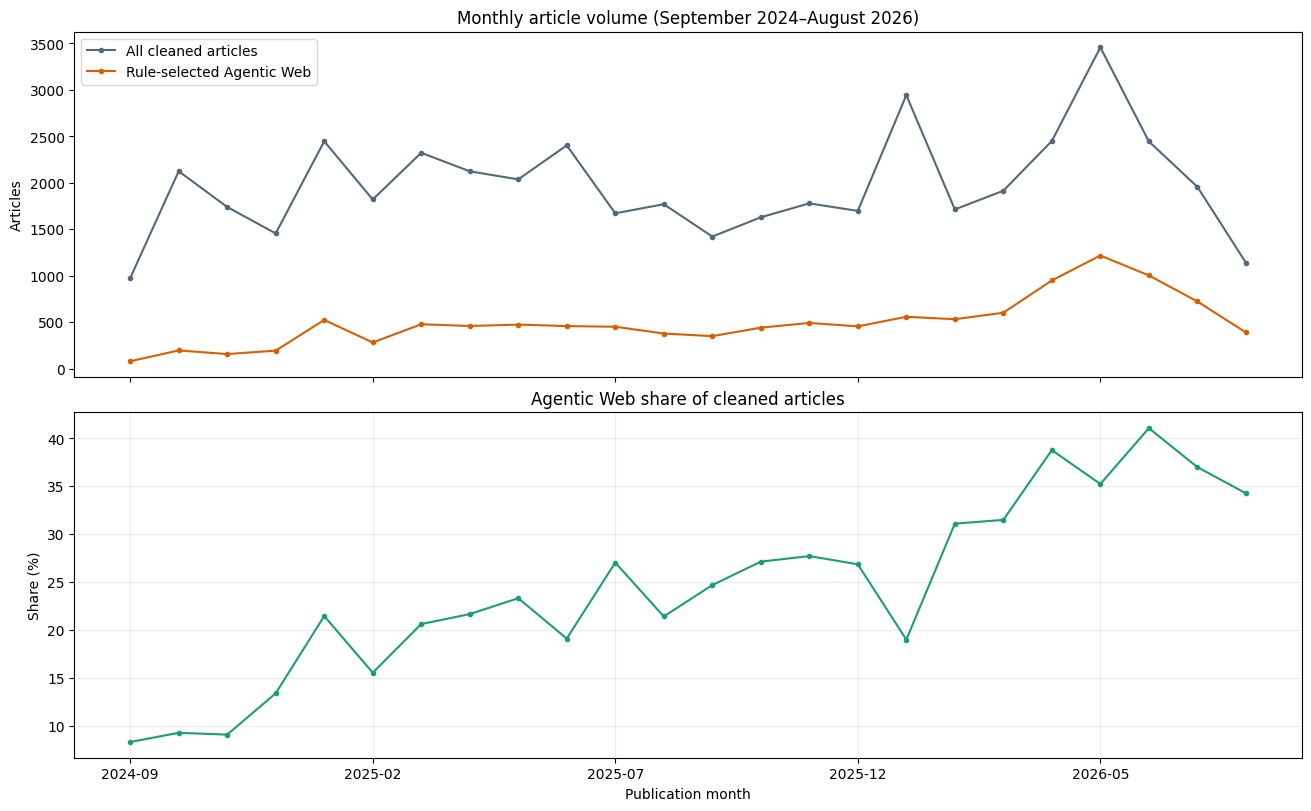

,all_articles,agentic_articles,agentic_share
count,24.000,24.000,24.000
mean,1976.792,494.458,0.244
std,549.538,265.596,0.093
min,975.000,81.000,0.083
25%,1691.500,372.000,0.191
50%,1868.000,459.500,0.240
75%,2343.000,539.500,0.312
max,3457.000,1218.000,0.411


Interpretation: use the lower-panel share to distinguish topic coverage from changes in overall corpus volume; the upper panel shows raw media-document volume.


In [7]:
articles["month"] = articles["date"].dt.to_period("M").astype(str)
agentic["month"] = agentic["date"].dt.to_period("M").astype(str)
monthly_total = articles.groupby("month").size().rename("all_articles")
monthly_agentic = agentic.groupby("month").size().rename("agentic_articles")
monthly = pd.concat([monthly_total, monthly_agentic], axis=1).fillna(0).astype(int)
monthly["agentic_share"] = monthly["agentic_articles"] / monthly["all_articles"].replace(0, np.nan)
monthly.to_csv(TABLE_DIR / "monthly_coverage.csv", index_label="month")
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True, constrained_layout=True)
monthly["all_articles"].plot(ax=axes[0], color="#536878", marker=".", label="All cleaned articles")
monthly["agentic_articles"].plot(ax=axes[0], color="#d95f02", marker=".", label="Rule-selected Agentic Web")
axes[0].set(title="Monthly article volume (September 2024–August 2026)", ylabel="Articles")
axes[0].legend()
monthly["agentic_share"].mul(100).plot(ax=axes[1], color="#1b9e77", marker=".")
axes[1].set(title="Agentic Web share of cleaned articles", ylabel="Share (%)", xlabel="Publication month")
axes[1].grid(alpha=.25)
fig.savefig(FIGURE_DIR / "monthly_coverage.png", dpi=160)
plt.show()
display(monthly.describe().round(3))
print("Interpretation: use the lower-panel share to distinguish topic coverage from changes in overall corpus volume; the upper panel shows raw media-document volume.")

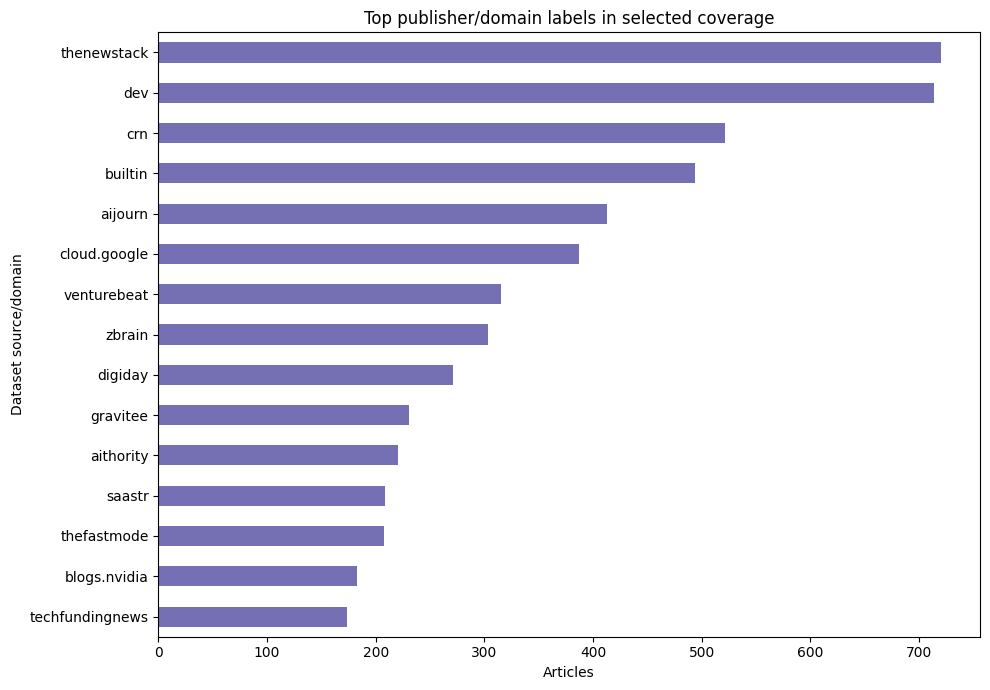

Selected article word-count quantiles:


,words
0.00,368.00
0.25,990.00
0.50,1274.00
0.75,1829.00
0.90,2882.00
0.99,7134.78
1.00,9613.00


Interpretation: publisher/domain concentration and text-length dispersion describe the corpus sample and should not be interpreted as representative shares of all news media.


In [8]:
source_counts = agentic["source"].fillna("[missing]").value_counts().head(15).sort_values()
fig, ax = plt.subplots(figsize=(10, 7))
source_counts.plot.barh(ax=ax, color="#7570b3")
ax.set(title="Top publisher/domain labels in selected coverage", xlabel="Articles", ylabel="Dataset source/domain")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "top_sources.png", dpi=160)
plt.show()
lengths = agentic["text_clean"].str.split().str.len()
print("Selected article word-count quantiles:")
display(lengths.quantile([0, .25, .5, .75, .9, .99, 1]).rename("words").to_frame())
print("Interpretation: publisher/domain concentration and text-length dispersion describe the corpus sample and should not be interpreted as representative shares of all news media.")

,term,count
7342,data,80943
987,agents,56450
712,agent,53834
15817,like,47850
18358,new,44613
17493,model,41038
28334,use,38213
17637,models,36662
14921,just,32698
26205,systems,32609


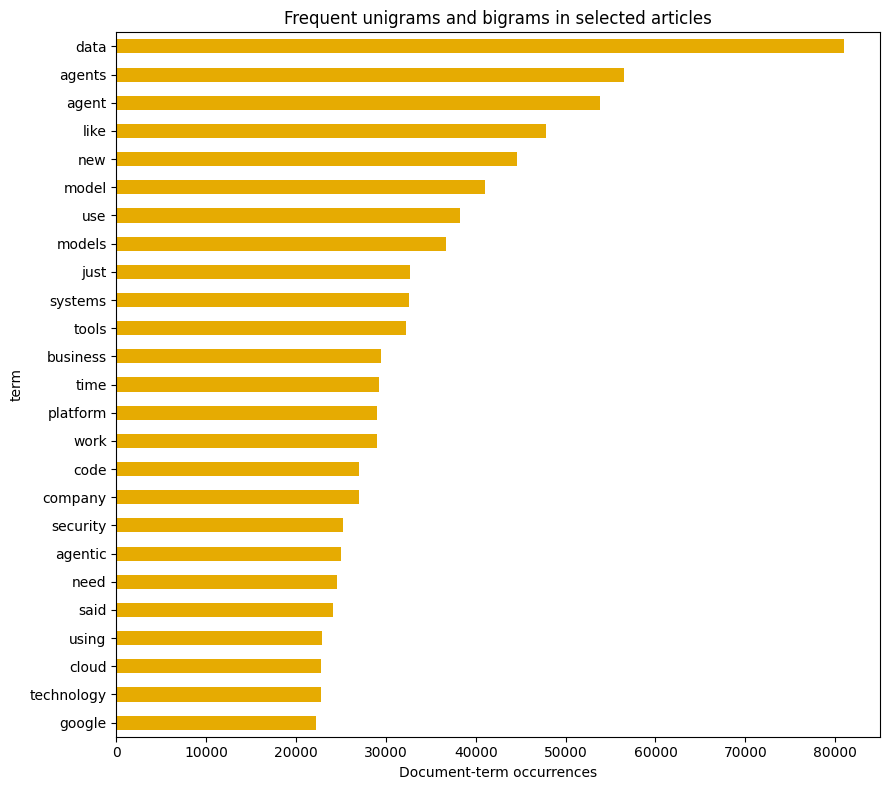

Interpretation: this is a stopword-filtered frequency baseline; common words and phrases are descriptive signals, not topics or entity counts.


In [9]:
eda_vectorizer = CountVectorizer(
    lowercase=True, strip_accents="unicode", stop_words="english", ngram_range=(1, 2),
    min_df=5, max_df=.85, max_features=30000, token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z0-9_-]+\b",
)
eda_matrix = eda_vectorizer.fit_transform(agentic["title"].fillna("") + " " + agentic["text_clean"])
term_totals = np.asarray(eda_matrix.sum(axis=0)).ravel()
top_terms = pd.DataFrame({"term": eda_vectorizer.get_feature_names_out(), "count": term_totals}).nlargest(25, "count")
display(top_terms)
top_terms.sort_values("count").plot.barh(x="term", y="count", legend=False, figsize=(9, 8), color="#e6ab02")
plt.title("Frequent unigrams and bigrams in selected articles")
plt.xlabel("Document-term occurrences")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "frequent_terms.png", dpi=160)
plt.show()
print("Interpretation: this is a stopword-filtered frequency baseline; common words and phrases are descriptive signals, not topics or entity counts.")

### 4.1 Sentiment and stance: scope decision

**What the brief asks (p. 3):** "Perform sentiment or stance analysis *where meaningful* for the selected topic." The requirement is explicitly conditional on meaningfulness for the Agentic Web track.

**Decision for this Stage 1 run: no sentiment or stance scores are produced.** The reasons are methodological, not a shortcut:
1. *Sentiment is not stance.* Stance is a position toward a target (for example, toward autonomous agents, a protocol, or an organisation's agent product). A document-level polarity score measures the tone of vocabulary. In technology news, negative vocabulary ("risk", "attack", "failure") often attaches to a security incident or a regulatory topic and positive vocabulary to a product announcement; neither reveals a stance toward autonomous agents, so a polarity score would be easy to over-read as "public opinion about agents".
2. *No validation resource exists.* The dataset has no sentiment or stance labels, and no hand-labelled sample is available to check any lexicon or model on this domain. An unvalidated score would be reported without any evidence that it measures what it claims to measure.
3. *It is not needed for the research questions.* The Stage 1 questions concern coverage over time, prominent entities, themes and entity relations; each is answered without polarity.
4. *Adding a model only to tick the box* would create a number that looks like a result but is not one.

**What would make it meaningful (future work, not done here):** a target-specific stance task — for example stance toward agent autonomy or toward a named protocol — on a defined sub-corpus (such as the interview/opinion-style topic found in section 5), with a written label scheme, a hand-labelled validation sample (with a second annotator if possible), and a comparison against a generic-polarity baseline to demonstrate that polarity alone is not stance.

**Status:** documented decision with justification. Leon Bytyqi has decided not to pursue sentiment/stance analysis in Stage 1; the brief makes it conditional ("where meaningful"), and the reasons above explain why it is not performed.

## 5. Topic modeling (TF–IDF + NMF)

**Method choice.** NMF on TF–IDF is an interpretable, CPU-feasible baseline for a corpus of this size (about 12k long articles). It gives additive, non-negative topic–term weights and per-document topic weights that can be inspected, exported and reused. LDA, Top2Vec or BERTopic would be alternatives, but this run deliberately adds no further model families: the professor's brief names them as examples (p. 3), and the question here is whether a *stable, interpretable* structure exists, not how many models can be fit.

**Text representation and preprocessing.**
1. *Boilerplate removal (topic view only).* Sentences repeated across at least 1% of selected articles (newsletter, navigation and subscription text) are removed. The preserved corpus and NER inputs are unchanged.
2. *Acronym and phrase canonicalization (topic view only).* Long forms and acronyms are mapped to one token (for example `Model Context Protocol` and `MCP` → `mcp`; `large language model(s)` and `LLMs` → `llm`; `Agent2Agent`/`A2A protocol` → `a2a`) so that one concept does not split across features. The mapping is an explicit, auditable list and only merges unambiguous pairs.
3. *Lemmatization (topic view only).* The brief asks for lemmatization "where appropriate" (p. 2). Running a tagger-based lemmatizer over about 12k long articles costs roughly 25 minutes per run, so lemmas are computed once for each of the 12,000 vocabulary terms (spaCy `en_core_web_sm` in a fixed one-word context) and count columns that share a lemma are merged *before* TF–IDF weighting. This is an approximation: context-free tagging can mis-lemmatize ambiguous words, so a short, explicit list of protected words (for example `data`, which spaCy would map to `datum`) is excluded. The complete term→lemma table is exported to `outputs/tables/topic_term_lemma_map.csv`. Lemmatization is *not* applied to NER inputs or stored text, where it would damage names.
4. *Stop words.* The scikit-learn English list plus contraction fragments (`ve`, `ll`, `re`, …) that otherwise appear as topic terms.

**Model selection.** Topic count is chosen from the predeclared grid (3, 4, 6) by inspecting terms, representative documents, prevalence, pairwise NPMI and — in the stability section below — how reproducible each solution is across resamples. NMF candidates are fit on a fixed-seed 2,500-document sample and projected onto all selected articles. NPMI and stability are diagnostics, not proof that a topic is meaningful. Topic assignments over time are summarized in `outputs/tables/topic_monthly_prevalence.csv` and `outputs/figures/topic_monthly_prevalence.png`.

In [10]:
SENTENCE_SPLITTER = re.compile(r"(?<=[.!?])\s+|[\r\n]+")
SENTENCE_NORMALIZER = re.compile(r"[a-z0-9]+")
sentence_document_frequency = Counter()
for document_text in agentic["text_clean"].fillna(""):
    sentence_keys = {" ".join(SENTENCE_NORMALIZER.findall(sentence.lower())) for sentence in SENTENCE_SPLITTER.split(document_text)}
    sentence_document_frequency.update(sentence for sentence in sentence_keys if len(sentence.split()) >= 6)
boilerplate_sentence_threshold = max(20, int(np.ceil(0.01 * len(agentic))))
boilerplate_sentences = {sentence for sentence, count in sentence_document_frequency.items() if count >= boilerplate_sentence_threshold}
topic_documents_surface = []
for title, body in zip(agentic["title"].fillna(""), agentic["text_clean"].fillna("")):
    kept_sentences = []
    for sentence in SENTENCE_SPLITTER.split(body):
        sentence_key = " ".join(SENTENCE_NORMALIZER.findall(sentence.lower()))
        if len(sentence_key.split()) >= 6 and sentence_key not in boilerplate_sentences:
            kept_sentences.append(sentence)
    topic_documents_surface.append(str(title) + " " + " ".join(kept_sentences))
print(f"Topic-only boilerplate filter removed {len(boilerplate_sentences):,} recurring sentence forms (document frequency >= {boilerplate_sentence_threshold:,}); source texts are unchanged.")

# Acronym/phrase canonicalization for the topic view only (explicit, unambiguous pairs).
TOPIC_PHRASE_CANONICAL = [
    (r"\bmodel context protocol\b", "mcp"),
    (r"\blarge language models?\b|\bllms\b", "llm"),
    (r"\bretrieval[- ]augmented generation\b", "rag"),
    (r"\bartificial general intelligence\b", "agi"),
    (r"\bartificial intelligence\b|\ba\.i\.", "ai"),
    (r"\bagent2agent(?: protocol)?\b|\ba2a protocol\b", "a2a"),
    (r"\bagent development kit\b", "adk"),
    (r"\bagentic ai\b", "agentic_ai"),
    (r"\bai agents?\b", "ai_agent"),
]
TOPIC_PHRASE_PATTERNS = [(re.compile(pattern, re.IGNORECASE), token) for pattern, token in TOPIC_PHRASE_CANONICAL]


def canonicalize_topic_text(text: str) -> str:
    """Replace long forms/acronym variants by one token; used only for the topic representation."""
    for pattern, token in TOPIC_PHRASE_PATTERNS:
        text = pattern.sub(token, text)
    return text


topic_documents = [canonicalize_topic_text(text) for text in topic_documents_surface]
TOPIC_EXTRA_STOPWORDS = {"ve", "ll", "re", "don", "didn", "doesn", "isn", "wasn", "aren", "couldn", "wouldn", "shouldn"}
topic_stop_words = sorted(ENGLISH_STOP_WORDS | TOPIC_EXTRA_STOPWORDS)
TOPIC_TOKEN_PATTERN = r"(?u)\b[a-zA-Z][a-zA-Z0-9_-]+\b"
topic_count_vectorizer = CountVectorizer(
    lowercase=True, strip_accents="unicode", stop_words=topic_stop_words, ngram_range=(1, 2),
    min_df=8, max_df=.90, max_features=12000, token_pattern=TOPIC_TOKEN_PATTERN,
)
topic_count_matrix = topic_count_vectorizer.fit_transform(topic_documents)
surface_terms = topic_count_vectorizer.get_feature_names_out()

# Vocabulary-level lemmatization: lemmatize each distinct word once, then merge columns sharing a lemma.
PROTECTED_FROM_LEMMATIZATION = {
    "data", "does", "id", "cves", "im", "dies", "better", "best", "worse", "worst", "axes", "lives", "born",
    "media", "analytics", "metadata", "news", "series", "status", "gas", "process", "business", "access", "class", "address",
}
lemma_nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])
term_words = sorted({word for term in surface_terms for word in term.split(" ") if word.isalpha() and word not in PROTECTED_FROM_LEMMATIZATION})
lemma_of_word = {word: doc[-1].lemma_.lower() for word, doc in zip(
    term_words, lemma_nlp.pipe((f"They saw the {word}" for word in term_words), batch_size=256))}
lemma_terms = [" ".join(word if (word in PROTECTED_FROM_LEMMATIZATION or not word.isalpha()) else lemma_of_word.get(word, word)
                         for word in term.split(" ")) for term in surface_terms]
lemma_index = {lemma: position for position, lemma in enumerate(dict.fromkeys(lemma_terms))}
merge_matrix = csr_matrix((np.ones(len(lemma_terms)), (np.arange(len(lemma_terms)), [lemma_index[lemma] for lemma in lemma_terms])),
                          shape=(len(lemma_terms), len(lemma_index)))
topic_matrix = TfidfTransformer(sublinear_tf=True).fit_transform((topic_count_matrix @ merge_matrix).tocsr())
feature_names = np.array(list(lemma_index))
topic_lemma_map = pd.DataFrame({"term": surface_terms, "lemma_term": lemma_terms,
                                "total_count": np.asarray(topic_count_matrix.sum(axis=0)).ravel().astype(int)})
topic_lemma_map["changed"] = topic_lemma_map["term"].ne(topic_lemma_map["lemma_term"])
topic_lemma_map.to_csv(TABLE_DIR / "topic_term_lemma_map.csv", index=False)
topic_representation_info = {
    "boilerplate_sentence_forms_removed": len(boilerplate_sentences),
    "phrase_canonical_rules": len(TOPIC_PHRASE_CANONICAL),
    "vocabulary_before_lemma_merge": int(len(surface_terms)),
    "vocabulary_after_lemma_merge": int(len(feature_names)),
    "terms_changed_by_lemmatization": int(topic_lemma_map["changed"].sum()),
    "protected_from_lemmatization": sorted(PROTECTED_FROM_LEMMATIZATION),
    "lemmatization_scope": "topic view only; vocabulary-level, one-word context; NER/stored text unchanged",
}
print(f"Topic vocabulary: {len(surface_terms):,} surface terms -> {len(feature_names):,} after lemma merging; {topic_representation_info['terms_changed_by_lemmatization']:,} terms changed.")
display(topic_lemma_map[topic_lemma_map["changed"]].nlargest(12, "total_count")[["term", "lemma_term", "total_count"]])
binary_matrix = topic_matrix.copy()
binary_matrix.data[:] = 1
document_frequency = np.asarray(binary_matrix.sum(axis=0)).ravel()
n_docs = binary_matrix.shape[0]
rng = np.random.default_rng(SEED)
topic_fit_indices = np.sort(rng.choice(n_docs, size=min(2500, n_docs), replace=False))
print(f"Fitting candidate NMF models on a fixed seed sample of {len(topic_fit_indices):,}/{n_docs:,} documents; final topic assignments cover the full selected corpus.")
term_prob = document_frequency / n_docs


def mean_npmi(term_indices: np.ndarray) -> float:
    """Compute mean NPMI over distinct topic-word pairs present in documents."""
    scores = []
    for position, left in enumerate(term_indices):
        for right in term_indices[position + 1:]:
            co_document_count = float((binary_matrix[:, left].T @ binary_matrix[:, right]).toarray()[0, 0])
            p_xy = co_document_count / n_docs
            if p_xy <= 0:
                scores.append(-1.0)
                continue
            if p_xy >= 1.0:
                scores.append(1.0)
                continue
            pmi = np.log(p_xy / (term_prob[left] * term_prob[right]))
            scores.append(float(pmi / -np.log(p_xy)))
    return float(np.mean(scores)) if scores else float("nan")


topic_candidates = {}
topic_diagnostics = []
for n_topics in (3, 4, 6):
    model = NMF(n_components=n_topics, init="nndsvda", random_state=SEED, max_iter=500, tol=2e-4)
    model.fit(topic_matrix[topic_fit_indices])
    weights = model.transform(topic_matrix)
    topic_word_indices = [np.argsort(component)[::-1][:12] for component in model.components_]
    coherence = float(np.mean([mean_npmi(indices) for indices in topic_word_indices]))
    topic_candidates[n_topics] = (model, weights, topic_word_indices, coherence)
    candidate_assignments = weights.argmax(axis=1)
    candidate_sizes = np.bincount(candidate_assignments, minlength=n_topics)
    print(f"Candidate K={n_topics}: iterations={model.n_iter_}, converged={model.n_iter_ < model.max_iter}, NPMI={coherence:.3f}, prevalence={candidate_sizes.tolist()}")
    for candidate_topic, indices in enumerate(topic_word_indices):
        representative = int(np.argmax(weights[:, candidate_topic]))
        print(f"  Topic {candidate_topic}: {', '.join(feature_names[indices[:8]])}; representative={agentic.iloc[representative]['article_id']} | {agentic.iloc[representative]['title'][:120]}")
    topic_diagnostics.append({"n_topics": n_topics, "iterations": int(model.n_iter_), "converged_within_limit": bool(model.n_iter_ < model.max_iter), "reconstruction_error": float(model.reconstruction_err_), "mean_top12_npmi": coherence})
topic_diagnostics = pd.DataFrame(topic_diagnostics)
display(topic_diagnostics)
print("NPMI is one diagnostic among several (terms, representative documents, prevalence, stability); no single score is treated as a gold measure of coherence.")

Topic-only boilerplate filter removed 105 recurring sentence forms (document frequency >= 119); source texts are unchanged.


Topic vocabulary: 12,000 surface terms -> 9,723 after lemma merging; 3,672 terms changed.


,term,lemma_term,total_count
363,agents,agent,34593
7095,models,model,33370
10581,systems,system,32464
10981,tools,tool,31908
9421,said,say,23932
11446,using,use,22792
2294,companies,company,19844
10689,teams,team,19474
2897,customers,customer,17698
9745,services,service,15861


Fitting candidate NMF models on a fixed seed sample of 2,500/11,867 documents; final topic assignments cover the full selected corpus.


Candidate K=3: iterations=171, converged=True, NPMI=0.140, prevalence=[3946, 4026, 3895]
  Topic 0: organization, business, data, customer, technology, system, solution, enterprise; representative=179609 | GenAI in Manufacturing: Scope, Integration, and Use Cases
  Topic 1: agent, code, mcp, developer, model, api, context, tool; representative=51566 | Architecting Agentic AI Applications: The Complete Engineering Guide
  Topic 2: say, company, year, people, going, just, think, really; representative=131031 | DKNG Q2 2025 Earnings Report on 8/6/2025


Candidate K=4: iterations=175, converged=True, NPMI=0.149, prevalence=[2883, 3091, 3039, 2854]
  Topic 0: organization, business, team, process, system, risk, data, efficiency; representative=179609 | GenAI in Manufacturing: Scope, Integration, and Use Cases
  Topic 1: agent, mcp, api, code, server, model, developer, tool; representative=164498 | Enterprise MCP Governance: How to Control, Audit, and Secure MCP Server Access at Scale
  Topic 2: thing, think, just, actually, say, want, people, really; representative=144091 | How it feels to be a software engineer when AI is changing our relationship with code
  Topic 3: company, billion, say, market, year, platform, million, customer; representative=39968 | The 10 Biggest News Stories Of 2024


Candidate K=6: iterations=145, converged=True, NPMI=0.194, prevalence=[2314, 2915, 2653, 2383, 1312, 290]
  Topic 0: organization, risk, efficiency, process, system, insight, business, data; representative=179599 | Generative AI in internal audit: Scope, integration, use cases, challenges and trends
  Topic 1: agent, mcp, api, code, server, developer, model, security; representative=164498 | Enterprise MCP Governance: How to Control, Audit, and Secure MCP Server Access at Scale
  Topic 2: thing, think, actually, just, say, really, people, want; representative=144091 | How it feels to be a software engineer when AI is changing our relationship with code
  Topic 3: company, billion, year, market, technology, say, investor, investment; representative=39968 | The 10 Biggest News Stories Of 2024
  Topic 4: brand, search, shopping, website, commerce, content, marketing, site; representative=156741 | How to Make a Furniture Website in 8 Steps
  Topic 5: gitlab, base salary, salary, salary ran

,n_topics,iterations,converged_within_limit,reconstruction_error,mean_top12_npmi
0,3,171,True,46.975317,0.139916
1,4,175,True,46.802880,0.148820
2,6,145,True,46.496684,0.193736


NPMI is one diagnostic among several (terms, representative documents, prevalence, stability); no single score is treated as a gold measure of coherence.


In [11]:
N_TOPICS = 3
nmf_model, topic_weights, topic_word_indices, selected_npmi = topic_candidates[N_TOPICS]
topic_assignment = topic_weights.argmax(axis=1)
topic_strength = topic_weights.max(axis=1)
topic_rows = []
for topic_id, indices in enumerate(topic_word_indices):
    top_words = feature_names[indices].tolist()
    members = np.flatnonzero(topic_assignment == topic_id)
    exemplars = sorted(members, key=lambda idx: topic_weights[idx, topic_id], reverse=True)[:3]
    for rank, idx in enumerate(indices, start=1):
        topic_rows.append({"topic_id": topic_id, "rank": rank, "term": feature_names[idx], "term_weight": float(nmf_model.components_[topic_id, idx])})
    print(f"Topic {topic_id} (n={len(members):,}; NPMI={mean_npmi(indices):.3f}): {', '.join(top_words)}")
    for idx in exemplars:
        print("  Representative:", agentic.iloc[idx]["article_id"], "|", agentic.iloc[idx]["title"][:180])
agentic["topic_id"] = topic_assignment
agentic["topic_weight"] = topic_strength
topic_prevalence = agentic.groupby("topic_id").agg(article_count=("article_id", "size"), mean_topic_weight=("topic_weight", "mean")).reset_index()
topic_prevalence["share"] = topic_prevalence["article_count"] / len(agentic)
display(topic_prevalence)
pd.DataFrame(topic_rows).to_csv(TABLE_DIR / "topic_terms.csv", index=False)
topic_prevalence.to_csv(TABLE_DIR / "topic_prevalence.csv", index=False)
agentic[["article_id", "topic_id", "topic_weight"]].to_csv(TABLE_DIR / "topic_assignments.csv", index=False)
print(f"K={N_TOPICS} is the working solution; the topic-count decision is made after the stability analysis below. Topic labels are interpretive and are assigned only in the interpretation section.")

Topic 0 (n=3,946; NPMI=0.112): organization, business, data, customer, technology, system, solution, enterprise, management, platform, operation, team
  Representative: 179609 | GenAI in Manufacturing: Scope, Integration, and Use Cases
  Representative: 179605 | GenAI for Procurement: Adoption, Use Cases, and Trends
  Representative: 180190 | GenAI in Sales: Scope, Adoption, Use Cases, ROI and Challenges


Topic 1 (n=4,026; NPMI=0.141): agent, code, mcp, developer, model, api, context, tool, prompt, run, use, file
  Representative: 51566 | Architecting Agentic AI Applications: The Complete Engineering Guide
  Representative: 44181 | AddyOsmani.com - How to write a good spec for AI agents
  Representative: 44182 | AddyOsmani.com


Topic 2 (n=3,895; NPMI=0.167): say, company, year, people, going, just, think, really, thing, want, like, new
  Representative: 131031 | DKNG Q2 2025 Earnings Report on 8/6/2025
  Representative: 101108 | Indexing the economy
  Representative: 2376 | Human-AI relationships are no longer just science fiction


,topic_id,article_count,mean_topic_weight,share
0,0,3946,0.081338,0.332519
1,1,4026,0.099864,0.339260
2,2,3895,0.090628,0.328221


K=3 is the working solution; the topic-count decision is made after the stability analysis below. Topic labels are interpretive and are assigned only in the interpretation section.


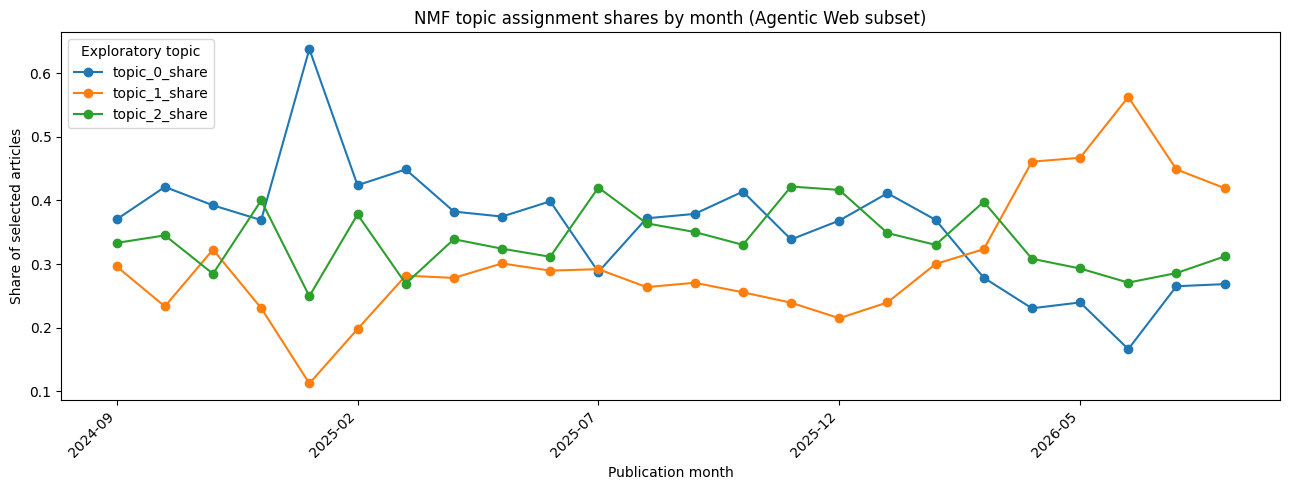

Interpretation: each monthly series is a share of the selected subset assigned to that exploratory topic; it is not a validated topic prevalence or adoption measure.


In [12]:
topic_monthly_counts = (agentic.assign(month=agentic["date"].dt.to_period("M").astype(str))
                        .groupby(["month", "topic_id"]).size().unstack(fill_value=0)
                        .reindex(columns=range(N_TOPICS), fill_value=0).sort_index())
topic_monthly_share = topic_monthly_counts.div(topic_monthly_counts.sum(axis=1), axis=0)
topic_monthly_share.columns = [f"topic_{int(topic_id)}_share" for topic_id in topic_monthly_share.columns]
topic_monthly_share.to_csv(TABLE_DIR / "topic_monthly_prevalence.csv", index_label="month")
ax = topic_monthly_share.plot(figsize=(13, 5), marker="o")
ax.set(title="NMF topic assignment shares by month (Agentic Web subset)", xlabel="Publication month", ylabel="Share of selected articles")
ax.legend(title="Exploratory topic")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "topic_monthly_prevalence.png", dpi=160)
plt.show()
print("Interpretation: each monthly series is a share of the selected subset assigned to that exploratory topic; it is not a validated topic prevalence or adoption measure.")

,n_topics,replicates,mean_matched_cosine,worst_topic_cosine_min,mean_top12_jaccard,mean_assignment_ari,sd_assignment_ari,converged_replicates,mean_top12_npmi
0,3,10,0.984,0.971,0.699,0.833,0.059,10,0.140
1,4,10,0.967,0.753,0.692,0.751,0.119,10,0.149
2,6,10,0.914,0.082,0.576,0.729,0.108,10,0.194


Representation sensitivity (K=3): assignment ARI between surface-form view and lemma/acronym view = 0.846
  Surface-form topic 0: data, business, organizations, systems, solutions, technology, management, operations, customer, insights
  Surface-form topic 1: agent, code, model, context, api, mcp, agents, tool, developers, tools
  Surface-form topic 2: said, people, company, going, think, just, really, year, companies, lot


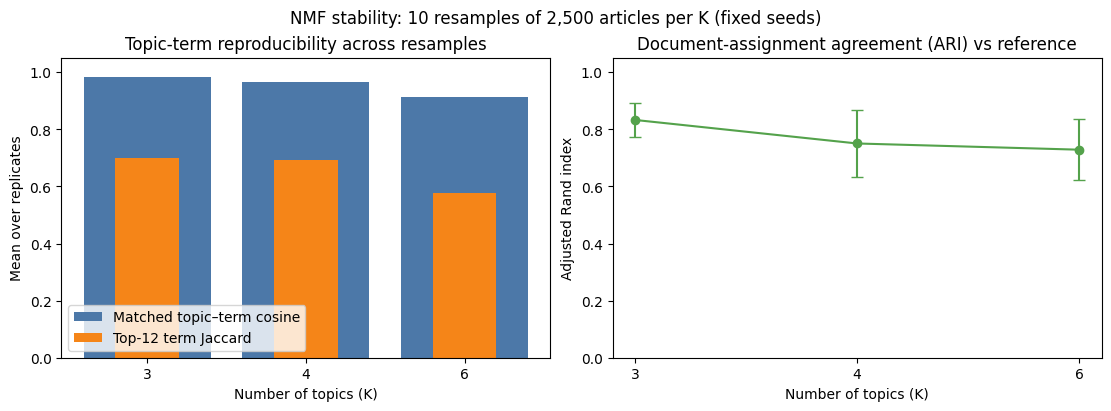

Interpretation: matched cosine and ARI measure sample-to-sample reproducibility, not correctness. High stability for a K does not prove the topics are meaningful, and lower stability at larger K can reflect splitting of broad themes.


In [13]:
STABILITY_REPLICATES = 10
STABILITY_SAMPLE_SIZE = len(topic_fit_indices)
STABILITY_GRID = (3, 4, 6)
stability_rows = []
for k in STABILITY_GRID:
    reference_model, reference_weights, reference_indices, _ = topic_candidates[k]
    reference_assignment = reference_weights.argmax(axis=1)
    for replicate in range(STABILITY_REPLICATES):
        replicate_seed = SEED + 1000 * k + replicate + 1
        replicate_rng = np.random.default_rng(replicate_seed)
        sample_indices = np.sort(replicate_rng.choice(n_docs, size=STABILITY_SAMPLE_SIZE, replace=False))
        replicate_model = NMF(n_components=k, init="nndsvda", random_state=replicate_seed, max_iter=1000, tol=2e-4)
        replicate_model.fit(topic_matrix[sample_indices])
        similarity = cosine_similarity(reference_model.components_, replicate_model.components_)
        reference_rows, replicate_cols = linear_sum_assignment(-similarity)
        matched_cosine = similarity[reference_rows, replicate_cols]
        replicate_top = [np.argsort(component)[::-1][:12] for component in replicate_model.components_]
        top_term_jaccard = [len(set(reference_indices[r]) & set(replicate_top[c])) / len(set(reference_indices[r]) | set(replicate_top[c]))
                            for r, c in zip(reference_rows, replicate_cols)]
        replicate_assignment = replicate_model.transform(topic_matrix).argmax(axis=1)
        stability_rows.append({
            "n_topics": k, "replicate": replicate, "seed": replicate_seed, "sample_size": STABILITY_SAMPLE_SIZE,
            "mean_matched_topic_cosine": float(matched_cosine.mean()), "min_matched_topic_cosine": float(matched_cosine.min()),
            "mean_top12_term_jaccard": float(np.mean(top_term_jaccard)),
            "assignment_ari_vs_reference": float(adjusted_rand_score(reference_assignment, replicate_assignment)),
            "converged": bool(replicate_model.n_iter_ < replicate_model.max_iter),
        })
topic_stability = pd.DataFrame(stability_rows)
topic_stability_summary = (topic_stability.groupby("n_topics")
    .agg(replicates=("replicate", "size"),
         mean_matched_cosine=("mean_matched_topic_cosine", "mean"), worst_topic_cosine_min=("min_matched_topic_cosine", "min"),
         mean_top12_jaccard=("mean_top12_term_jaccard", "mean"),
         mean_assignment_ari=("assignment_ari_vs_reference", "mean"), sd_assignment_ari=("assignment_ari_vs_reference", "std"),
         converged_replicates=("converged", "sum"))
    .join(topic_diagnostics.set_index("n_topics")["mean_top12_npmi"]).reset_index())
topic_stability.to_csv(TABLE_DIR / "topic_stability_replicates.csv", index=False)
topic_stability_summary.to_csv(TABLE_DIR / "topic_stability_summary.csv", index=False)
display(topic_stability_summary.round(3))

# Representation sensitivity: same model/sample/seed on the plain surface-form TF-IDF view (no lemma merge, no acronym canonicalization).
surface_vectorizer = TfidfVectorizer(
    lowercase=True, strip_accents="unicode", stop_words="english", ngram_range=(1, 2),
    min_df=8, max_df=.90, max_features=12000, sublinear_tf=True, token_pattern=TOPIC_TOKEN_PATTERN)
surface_matrix = surface_vectorizer.fit_transform(topic_documents_surface)
surface_model = NMF(n_components=N_TOPICS, init="nndsvda", random_state=SEED, max_iter=500, tol=2e-4).fit(surface_matrix[topic_fit_indices])
surface_assignment = surface_model.transform(surface_matrix).argmax(axis=1)
representation_ari = float(adjusted_rand_score(surface_assignment, topic_assignment))
surface_feature_names = surface_vectorizer.get_feature_names_out()
print(f"Representation sensitivity (K={N_TOPICS}): assignment ARI between surface-form view and lemma/acronym view = {representation_ari:.3f}")
for surface_topic, component in enumerate(surface_model.components_):
    print(f"  Surface-form topic {surface_topic}: {', '.join(surface_feature_names[np.argsort(component)[::-1][:10]])}")

summary_for_plot = topic_stability_summary.set_index("n_topics")
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
axes[0].bar(summary_for_plot.index.astype(str), summary_for_plot["mean_matched_cosine"], color="#4c78a8", label="Matched topic–term cosine")
axes[0].bar(summary_for_plot.index.astype(str), summary_for_plot["mean_top12_jaccard"], color="#f58518", width=.4, label="Top-12 term Jaccard")
axes[0].set(title="Topic-term reproducibility across resamples", xlabel="Number of topics (K)", ylabel="Mean over replicates", ylim=(0, 1.05))
axes[0].legend(loc="lower left")
axes[1].errorbar(summary_for_plot.index.astype(str), summary_for_plot["mean_assignment_ari"], yerr=summary_for_plot["sd_assignment_ari"], fmt="o-", color="#54a24b", capsize=4)
axes[1].set(title="Document-assignment agreement (ARI) vs reference", xlabel="Number of topics (K)", ylabel="Adjusted Rand index", ylim=(0, 1.05))
fig.suptitle(f"NMF stability: {STABILITY_REPLICATES} resamples of {STABILITY_SAMPLE_SIZE:,} articles per K (fixed seeds)")
fig.savefig(FIGURE_DIR / "topic_stability.png", dpi=160)
plt.show()
print("Interpretation: matched cosine and ARI measure sample-to-sample reproducibility, not correctness. High stability for a K does not prove the topics are meaningful, and lower stability at larger K can reflect splitting of broad themes.")

Denominators: 'selected' = rule-selected Agentic Web articles in the month; 'all' = all cleaned articles in the month. Months with fewer than 100 selected articles are flagged: ['2024-09']


Bulk-ingest publisher-months (>= 100 articles and >= 20% of the month's selected articles): 2 cells covering 431 articles


,source,month,articles,month_selected_articles,share_of_month_selected
711,dev,2026-04,198,950,0.208421
2295,zbrain,2025-01,233,525,0.443810


,topic_id,window,articles,distinct_sources,top_source,top_source_share
0,0,first_6_months,702,87,zbrain,0.355
1,0,last_6_months,1143,111,builtin,0.211
2,1,first_6_months,281,58,gravitee,0.160
3,1,last_6_months,2256,105,dev,0.280
4,2,first_6_months,456,86,crn,0.094
5,2,last_6_months,1491,134,digiday,0.072


,topic_id,spearman_rho_month_vs_share_of_selected,n_months,share_of_selected_first_6_months,share_of_all_first_6_months,share_of_selected_last_6_months,share_of_all_last_6_months,change_share_of_selected_pp,change_share_of_all_pp,share_of_selected_first_6_months_excl_bulk,share_of_selected_last_6_months_excl_bulk,change_share_of_selected_excl_bulk_pp
0,0,-0.7078,24,0.4878,0.0665,0.2337,0.0855,-25.4096,1.9070,0.3922,0.2417,-15.0518
1,1,0.5574,24,0.1953,0.0266,0.4613,0.1688,26.6075,14.2199,0.2297,0.4454,21.5754
2,2,-0.0983,24,0.3169,0.0432,0.3049,0.1116,-1.1979,6.8395,0.3781,0.3129,-6.5236


First window = 2024-09..2025-02; last window = 2026-03..2026-08. Windows pool articles (sum of counts / sum of denominators). Spearman rho is descriptive over 24 autocorrelated monthly points and is not a significance test.


,topic_id,window,rank,date,source,title
0,0,overall,1,2024-11-06,zbrain,"GenAI in Manufacturing: Scope, Integration, an..."
1,0,overall,2,2024-10-16,zbrain,"GenAI for Procurement: Adoption, Use Cases, an..."
2,0,overall,3,2025-03-24,zbrain,"GenAI in Sales: Scope, Adoption, Use Cases, RO..."
3,0,first_6_months,1,2024-11-06,zbrain,"GenAI in Manufacturing: Scope, Integration, an..."
4,0,first_6_months,2,2024-10-16,zbrain,"GenAI for Procurement: Adoption, Use Cases, an..."
5,0,last_6_months,1,2026-08-03,aithority,Living AI: The Rise Of Self-Evolving Tech That...
6,0,last_6_months,2,2026-07-20,aithority,AI and The Future of Work: Artificial Intellig...
7,1,overall,1,2026-06-10,dev,Architecting Agentic AI Applications: The Comp...
8,1,overall,2,2026-01-13,addyosmani,AddyOsmani.com - How to write a good spec for ...
9,1,overall,3,2026-01-31,addyosmani,AddyOsmani.com


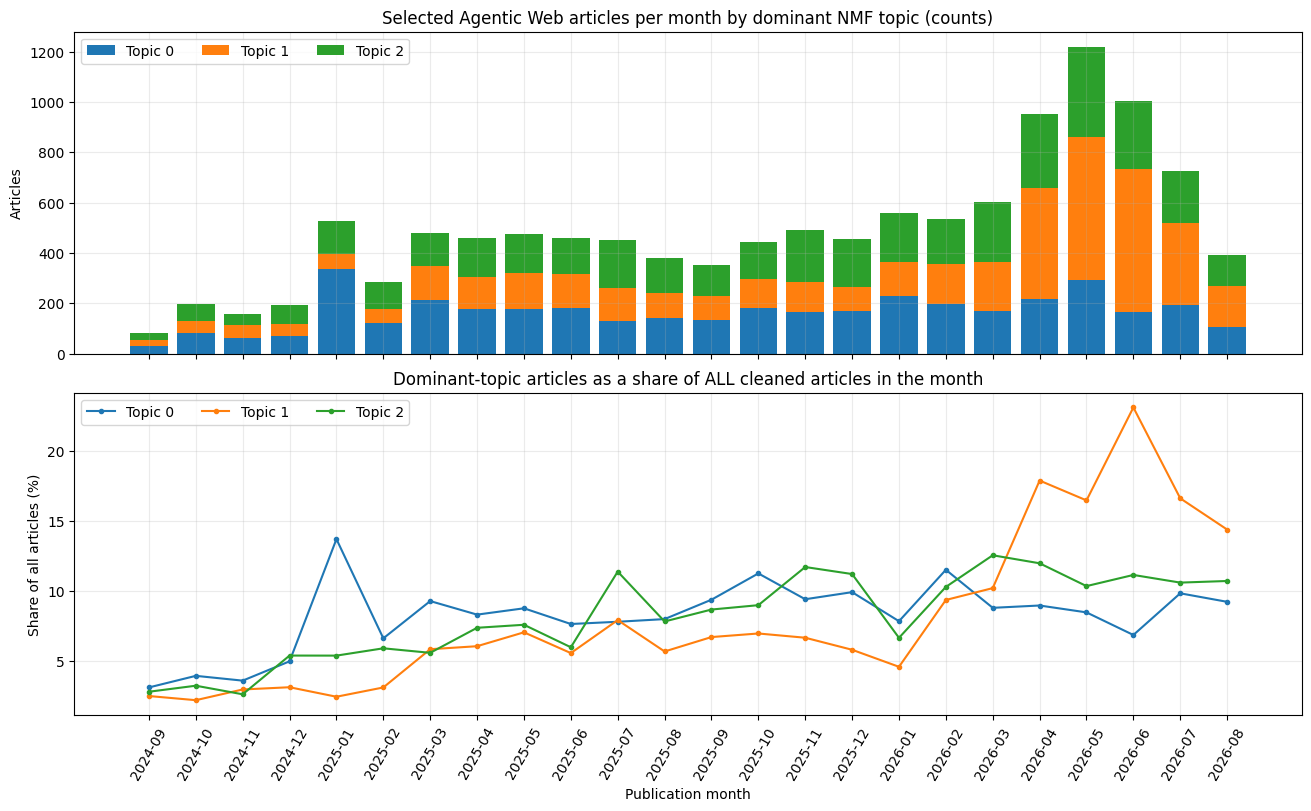

Interpretation guide: the upper panel is raw volume, the lower panel normalizes by the whole corpus so that overall dataset growth is not mistaken for topic growth. Both describe published coverage in this dataset, not technology adoption.


In [14]:
LOW_DENOMINATOR_THRESHOLD = 100
months = list(topic_monthly_counts.index)
topic_ids = list(topic_monthly_counts.columns)
month_table = topic_monthly_counts.rename(columns=lambda topic: f"topic_{topic}_articles").join(monthly[["agentic_articles", "all_articles"]])
assert (month_table[[f"topic_{topic}_articles" for topic in topic_ids]].sum(axis=1) == month_table["agentic_articles"]).all()
for topic in topic_ids:
    month_table[f"topic_{topic}_share_of_selected"] = month_table[f"topic_{topic}_articles"] / month_table["agentic_articles"]
    month_table[f"topic_{topic}_share_of_all"] = month_table[f"topic_{topic}_articles"] / month_table["all_articles"]
month_table["low_denominator_flag"] = month_table["agentic_articles"] < LOW_DENOMINATOR_THRESHOLD
month_table.to_csv(TABLE_DIR / "topic_monthly_counts.csv", index_label="month")
print(f"Denominators: 'selected' = rule-selected Agentic Web articles in the month; 'all' = all cleaned articles in the month. Months with fewer than {LOW_DENOMINATOR_THRESHOLD} selected articles are flagged: {month_table.index[month_table['low_denominator_flag']].tolist()}")

WINDOW_MONTHS = 6
first_window, last_window = months[:WINDOW_MONTHS], months[-WINDOW_MONTHS:]
month_position = np.arange(len(months))
trend_rows = []
for topic in topic_ids:
    share_selected = month_table[f"topic_{topic}_share_of_selected"]
    rho, _ = spearmanr(month_position, share_selected)
    row = {"topic_id": topic, "spearman_rho_month_vs_share_of_selected": float(rho), "n_months": len(months)}
    for label, window in (("first_6_months", first_window), ("last_6_months", last_window)):
        counts = month_table.loc[window, f"topic_{topic}_articles"].sum()
        row[f"share_of_selected_{label}"] = float(counts / month_table.loc[window, "agentic_articles"].sum())
        row[f"share_of_all_{label}"] = float(counts / month_table.loc[window, "all_articles"].sum())
    row["change_share_of_selected_pp"] = 100 * (row["share_of_selected_last_6_months"] - row["share_of_selected_first_6_months"])
    row["change_share_of_all_pp"] = 100 * (row["share_of_all_last_6_months"] - row["share_of_all_first_6_months"])
    trend_rows.append(row)
topic_temporal_trends = pd.DataFrame(trend_rows)

# Publisher-concentration robustness: a (publisher, month) cell is treated as a bulk-ingest cell when one publisher supplies
# at least BULK_MIN_ARTICLES articles AND at least BULK_MIN_MONTH_SHARE of that month's selected articles (predeclared rule).
BULK_MIN_ARTICLES, BULK_MIN_MONTH_SHARE = 100, 0.20
source_month = agentic.groupby(["source", "month"]).size().rename("articles").reset_index()
source_month["month_selected_articles"] = source_month["month"].map(monthly["agentic_articles"])
source_month["share_of_month_selected"] = source_month["articles"] / source_month["month_selected_articles"]
bulk_cells = source_month[source_month["articles"].ge(BULK_MIN_ARTICLES) & source_month["share_of_month_selected"].ge(BULK_MIN_MONTH_SHARE)]
bulk_cells.to_csv(TABLE_DIR / "bulk_ingest_publisher_months.csv", index=False)
bulk_keys = set(zip(bulk_cells["source"], bulk_cells["month"]))
retained_mask = np.array([(source, month) not in bulk_keys for source, month in zip(agentic["source"], agentic["month"])])
retained_articles = agentic[retained_mask]
print(f"Bulk-ingest publisher-months (>= {BULK_MIN_ARTICLES} articles and >= {BULK_MIN_MONTH_SHARE:.0%} of the month's selected articles): {len(bulk_cells)} cells covering {int((~retained_mask).sum()):,} articles")
display(bulk_cells)
for column, window in (("first_6_months", first_window), ("last_6_months", last_window)):
    window_articles = retained_articles[retained_articles["month"].isin(window)]
    topic_temporal_trends[f"share_of_selected_{column}_excl_bulk"] = [float(window_articles["topic_id"].eq(topic).mean()) for topic in topic_ids]
topic_temporal_trends["change_share_of_selected_excl_bulk_pp"] = 100 * (
    topic_temporal_trends["share_of_selected_last_6_months_excl_bulk"] - topic_temporal_trends["share_of_selected_first_6_months_excl_bulk"])
topic_temporal_trends.to_csv(TABLE_DIR / "topic_temporal_trends.csv", index=False)

concentration_rows = []
for topic in topic_ids:
    for label, window in (("first_6_months", first_window), ("last_6_months", last_window)):
        window_members = agentic[agentic["topic_id"].eq(topic) & agentic["month"].isin(window)]
        source_shares = window_members["source"].value_counts(normalize=True)
        concentration_rows.append({"topic_id": topic, "window": label, "articles": len(window_members), "distinct_sources": int(window_members["source"].nunique()),
                                   "top_source": source_shares.index[0], "top_source_share": float(source_shares.iloc[0])})
topic_source_concentration = pd.DataFrame(concentration_rows)
topic_source_concentration.to_csv(TABLE_DIR / "topic_source_concentration.csv", index=False)
display(topic_source_concentration.round(3))
display(topic_temporal_trends.round(4))
print(f"First window = {first_window[0]}..{first_window[-1]}; last window = {last_window[0]}..{last_window[-1]}. Windows pool articles (sum of counts / sum of denominators). Spearman rho is descriptive over {len(months)} autocorrelated monthly points and is not a significance test.")

representative_rows = []
for topic in topic_ids:
    members = agentic[agentic["topic_id"].eq(topic)]
    selections = [("overall", members.nlargest(3, "topic_weight"))]
    for label, window in (("first_6_months", first_window), ("last_6_months", last_window)):
        selections.append((label, members[members["month"].isin(window)].nlargest(2, "topic_weight")))
    for window_label, selected_members in selections:
        for rank, article in enumerate(selected_members.itertuples(index=False), start=1):
            representative_rows.append({"topic_id": topic, "window": window_label, "rank": rank, "article_id": article.article_id,
                                        "date": article.date.strftime("%Y-%m-%d"), "source": article.source,
                                        "topic_weight": float(article.topic_weight), "title": article.title, "url": article.url})
topic_representative_articles = pd.DataFrame(representative_rows)
topic_representative_articles.to_csv(TABLE_DIR / "topic_representative_articles.csv", index=False)
display(topic_representative_articles.assign(title=topic_representative_articles["title"].str.slice(0, 95))[["topic_id", "window", "rank", "date", "source", "title"]])

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True, constrained_layout=True)
bottom = np.zeros(len(months))
for topic in topic_ids:
    values = month_table[f"topic_{topic}_articles"].to_numpy()
    axes[0].bar(months, values, bottom=bottom, label=f"Topic {topic}")
    bottom += values
axes[0].set(title="Selected Agentic Web articles per month by dominant NMF topic (counts)", ylabel="Articles")
axes[0].legend(ncol=len(topic_ids))
for topic in topic_ids:
    axes[1].plot(months, month_table[f"topic_{topic}_share_of_all"] * 100, marker=".", label=f"Topic {topic}")
axes[1].set(title="Dominant-topic articles as a share of ALL cleaned articles in the month", ylabel="Share of all articles (%)", xlabel="Publication month")
axes[1].legend(ncol=len(topic_ids))
for axis in axes:
    axis.tick_params(axis="x", rotation=60)
    axis.grid(alpha=.25)
fig.savefig(FIGURE_DIR / "topic_monthly_counts_and_shares.png", dpi=160)
plt.show()
print("Interpretation guide: the upper panel is raw volume, the lower panel normalizes by the whole corpus so that overall dataset growth is not mistaken for topic growth. Both describe published coverage in this dataset, not technology adoption.")

### 5.1 Topic-count decision and what the stability analysis shows

Three diagnostics disagree, which is why none is used alone. **NPMI rises with K** (K=3: 0.140, K=4: 0.149, K=6: 0.194), but **reproducibility falls**: across 10 fixed-seed resamples of 2,500 articles, K=3 has the highest document-assignment agreement with the reference fit (mean ARI 0.83) and every K=3 topic is recovered with matched cosine ≥ 0.97; K=4 loses stability in one topic (worst matched cosine ≈ 0.75); K=6 contains a topic that is essentially *not* recovered across samples (worst matched cosine ≈ 0.08). The extra topics at higher K also look like narrow content patterns rather than themes — at K=6 a job-advertisement template (GitLab salary/equity vocabulary) and an e-commerce/SEO cluster appear — and K=4 splits company/market/investment news out of the K=3 "commentary" topic. **K=3 is therefore retained** (it was also the earlier choice; the stability evidence supports it, it does not prove the topics are "true"). Converged-fit counts and all replicate metrics are in `outputs/tables/topic_stability_summary.csv` and `topic_stability_replicates.csv`.

**Representation check.** Fitting the same K=3 model on the plain surface-form view (no lemma merging or acronym canonicalization) gives document assignments that agree with the lemma/acronym view at ARI ≈ 0.85, and topics with the same three themes. Lemmatization mainly removes duplicate features (`agent`/`agents`, `tool`/`tools`, `said`/`says`) rather than changing the structure, which supports using it for interpretability. Lemmas are computed only for the topic view, so names and stored text are unchanged.

### 5.2 What the three topics represent (exploratory labels)

Labels below are the notebook author's interpretation of top terms and representative articles; they are not validated categories.

| Topic | Label (interpretive) | Top terms | Representative articles (from `topic_representative_articles.csv`) |
|---|---|---|---|
| 0 | Enterprise adoption, operations and solutions | organization, business, data, customer, technology, system, solution, enterprise, management, platform | *GenAI in Manufacturing: Scope, Integration, and Use Cases*; *GenAI for Procurement: Adoption, Use Cases, and Trends* (vendor-style explainer pages) |
| 1 | Agent engineering, tools and protocols | agent, code, mcp, developer, model, api, context, tool, prompt, run | *Architecting Agentic AI Applications: The Complete Engineering Guide*; *How to write a good spec for AI agents* |
| 2 | Quoted commentary and company/market news | say, company, year, people, going, think, really, thing, want, new | *DKNG Q2 2025 Earnings Report on 8/6/2025*; *Indexing the economy*; *Human-AI relationships are no longer just science fiction* |

Topic 2 is lexically generic — reported speech and company-news vocabulary rather than a technology — and should be read as a *discourse type*. Assignments are hard (largest weight) while documents are mixtures (mean winning weight is about 0.08–0.10), so topic membership is soft and boundaries are overlapping, especially between topics 0 and 2.

### 5.3 How topic shares change over time (executed results)

Denominators matter and both are shown: the *share of selected articles* (what fraction of rule-selected Agentic Web articles in a window are assigned to the topic) and the *share of all cleaned articles* (normalizes for overall dataset growth). Windows pool the first six (2024-09 to 2025-02) and last six months (2026-03 to 2026-08) of the study period; 2024-09 has only 81 selected articles and is flagged as a low-denominator month.

- **Topic 1 (agent engineering, tools, protocols) rises strongly**: from about 19.5% to 46.1% of selected articles (+26.6 percentage points) and from about 2.7% to 16.9% of *all* cleaned articles (+14.2 pp). It has the largest increase on both denominators.
- **Topic 0 (enterprise/solutions) falls as a share of selected articles** (about 48.8% → 23.4%, −25.4 pp) **but does not fall as a share of all articles** (about 6.7% → 8.6%, +1.9 pp). Its *relative* decline therefore reflects dilution by faster growth in other topics, not less enterprise coverage in absolute terms.
- **Topic 2 (commentary/company news)** is roughly flat as a share of selected articles (about 31.7% → 30.5%, −1.2 pp) while rising as a share of all articles (+6.8 pp), i.e. it grew with the overall Agentic Web coverage.

**Publisher concentration changes the magnitude.** One publisher (`zbrain`) supplied 233 of the 525 selected articles in 2025-01 (44%) and about a third (35.5%) of topic 0 in the first window; one publisher-month in 2026-04 (`dev`) also meets the predeclared bulk rule (≥ 100 articles and ≥ 20% of the month's selected articles). Excluding those two publisher-months, the directions hold but the effects shrink: topic 0 −15.1 pp, topic 1 +21.6 pp, and topic 2 −6.5 pp (`topic_temporal_trends.csv`, `bulk_ingest_publisher_months.csv`, `topic_source_concentration.csv`).

### 5.4 Interpretation, and what the dataset cannot establish

*Observation:* in this corpus, the share of rule-selected articles about developer-facing agent engineering (MCP, code, APIs, tools) grew sharply across the study period, while general enterprise-use content grew less than the rest.

*Interpretation (hypothesis, not a finding):* media coverage of the Agentic Web appears to shift from general business-use framing toward engineering and protocol detail. This is consistent with a maturing tool ecosystem but does not demonstrate it.

*What the dataset cannot establish:* adoption, deployment, market size or importance of any technology (coverage is not use); causes of the shifts; whether the pattern holds outside this publisher set. The dataset is a collection of selected outlets whose composition changes over time (the bulk-ingest result above shows that single publishers can move a topic's share), the first window contains few selected articles, NMF topics are exploratory, and the article-selection rule has not been validated by human review.

In [15]:
trend = topic_temporal_trends.set_index("topic_id")
stability = topic_stability_summary.set_index("n_topics")
selected_topic_titles = set(topic_representative_articles["title"])
topic_claim_checks = {
    "topic 1 rises and topic 0 falls as share of selected articles, with and without bulk-ingest cells": bool(
        trend.loc[1, "change_share_of_selected_pp"] > 0 and trend.loc[1, "change_share_of_selected_excl_bulk_pp"] > 0
        and trend.loc[0, "change_share_of_selected_pp"] < 0 and trend.loc[0, "change_share_of_selected_excl_bulk_pp"] < 0),
    "topic 0 does not fall as a share of ALL articles (dilution, not decline)": bool(trend.loc[0, "change_share_of_all_pp"] > 0),
    "topic 1 has the largest increase in share of all articles": bool(trend["change_share_of_all_pp"].idxmax() == 1),
    "quoted percentage-point changes match the table": bool(
        np.isclose(trend.loc[1, "change_share_of_selected_pp"], 26.6, atol=.1) and np.isclose(trend.loc[0, "change_share_of_selected_pp"], -25.4, atol=.1)
        and np.isclose(trend.loc[2, "change_share_of_selected_pp"], -1.2, atol=.1) and np.isclose(trend.loc[1, "change_share_of_all_pp"], 14.2, atol=.1)
        and np.isclose(trend.loc[0, "change_share_of_all_pp"], 1.9, atol=.1) and np.isclose(trend.loc[2, "change_share_of_all_pp"], 6.8, atol=.1)
        and np.isclose(trend.loc[0, "change_share_of_selected_excl_bulk_pp"], -15.1, atol=.1)
        and np.isclose(trend.loc[1, "change_share_of_selected_excl_bulk_pp"], 21.6, atol=.1)
        and np.isclose(trend.loc[2, "change_share_of_selected_excl_bulk_pp"], -6.5, atol=.1)),
    "low-denominator month is 2024-09 only": month_table.index[month_table["low_denominator_flag"]].tolist() == ["2024-09"],
    "bulk-ingest cells are zbrain 2025-01 and dev 2026-04": set(zip(bulk_cells["source"], bulk_cells["month"])) == {("zbrain", "2025-01"), ("dev", "2026-04")},
    "K=3 has the highest assignment ARI; NPMI rises with K": bool(
        stability["mean_assignment_ari"].idxmax() == 3 and stability["mean_top12_npmi"].is_monotonic_increasing),
    "K=6 has a topic that is not recovered across resamples (min matched cosine < 0.5); K=3 recovers all (>= 0.95)": bool(
        stability.loc[6, "worst_topic_cosine_min"] < 0.5 and stability.loc[3, "worst_topic_cosine_min"] >= 0.95),
    "representation sensitivity ARI between 0.8 and 0.9": bool(0.8 <= representation_ari <= 0.9),
    "quoted representative titles are in the exported table": all(any(title.startswith(prefix) for title in selected_topic_titles) for prefix in (
        "GenAI in Manufacturing", "Architecting Agentic AI Applications", "DKNG Q2 2025", "Indexing the economy")),
}
display(pd.Series(topic_claim_checks, name="holds").to_frame())
if not all(topic_claim_checks.values()):
    raise AssertionError("A topic/temporal statement in the interpretation text no longer matches the executed results; revise the text.")
print("All topic/temporal interpretation statements verified against the executed results.")

,holds
"topic 1 rises and topic 0 falls as share of selected articles, with and without bulk-ingest cells",True
"topic 0 does not fall as a share of ALL articles (dilution, not decline)",True
topic 1 has the largest increase in share of all articles,True
quoted percentage-point changes match the table,True
low-denominator month is 2024-09 only,True
bulk-ingest cells are zbrain 2025-01 and dev 2026-04,True
K=3 has the highest assignment ARI; NPMI rises with K,True
K=6 has a topic that is not recovered across resamples (min matched cosine < 0.5); K=3 recovers all (>= 0.95),True
representation sensitivity ARI between 0.8 and 0.9,True
quoted representative titles are in the exported table,True


All topic/temporal interpretation statements verified against the executed results.


## 6. Named-entity recognition and conservative normalization

**Approach.** The brief asks for pretrained NER (p. 3). The lightweight English spaCy model (`en_core_web_sm`) supplies ORG, PERSON and PRODUCT candidate spans, and an explicit domain alias lexicon adds Agentic Web frameworks, protocols, products, models and technologies that the generic model mislabels or misses. The lexicon does not label every capitalized token. To keep the selected subset executable on CPU, NER runs on each title and the first 2,500 characters of its article; this lead-focused truncation can miss later mentions, and the number of truncated articles is printed below.

**Demonstrated problems in the first version and the corrections made.** Inspection of the exported entity table showed: (1) spaCy spans carrying a leading *the*, a possessive, quotes or a trademark sign, which created separate IDs for one name (for example *the Red Hat®*, *CX Dive's*, *Adobe’*); (2) one name split across ORGANIZATION, PERSON and PRODUCT IDs (for example *Accenture* as both organization and person); (3) garbled or non-English spans passing as entities; (4) acronyms with no canonical handling (`A2A`, `ADK`, `RAG`, `LLM`) and `AGI` mislabeled as an organization; and (5) lexicon entries that merged distinct products or units — *GitHub Copilot* into *Copilot*, *AWS* into *Amazon*, *DeepMind* into *Google*, and *Claude Code* hidden inside *Claude*.

**Rules now applied (each counted and exemplified in `outputs/tables/entity_normalization_report.csv`).**
- Trim *the*, possessives, quotes/brackets and trailing punctuation or ®/™ from spaCy spans; offsets are adjusted so every span still equals the source text.
- Drop spans with non-Latin script, no letters, or mojibake markers (the English model is unreliable there).
- If a cleaned spaCy name is already a lexicon alias, the lexicon match is authoritative; spelling variants of lexicon entities are linked to them.
- Give one normalized spaCy name one entity type by majority vote (ties: ORGANIZATION > PRODUCT > PERSON) and its most frequent spelling.
- Match short all-capital acronyms case-sensitively; keep distinct products and business units distinct (parent–subsidiary links are not modelled).

**Known trade-offs and remaining weaknesses (measured, not hypothetical).** Majority voting makes one name consistent but cannot make it *correct*: spaCy's small model labels many technologies as PERSON or ORGANIZATION (for example *Docker*, *Kafka* and *Stripe* are frequently typed PERSON, and *Blackwell*, an NVIDIA GPU architecture, resolves to PERSON because that label wins 73 of 93 votes), so entity *types* of spaCy-only entities are unreliable and the typed relation gates in section 7 inherit that noise. The rule can also merge genuinely different same-name entities (a person and a company with the same name). The most frequent spaCy "organizations" included generic technology and role acronyms (*GPU*, *UI*, *ML*, *ERP*, *CTO*, *SEO*, *CLI*, *CI*, *SQL*); a documented stop list now removes these generic terms (the list is in the code and in the report). Several frequent entities come almost entirely from one publisher (for example a publisher's own name, boilerplate such as a copyright line, or a vendor's own blog theme); they are **flagged, not removed**, in `outputs/tables/entity_publisher_concentration.csv` (≥ 90% of ≥ 30 articles from one publisher) because a vendor's coverage of itself is still coverage. Bare `Copilot` stays ambiguous between Microsoft and GitHub products. A lexicon span nested inside a longer spaCy span (for example `Google` inside `Google Cloud`) is kept as a separate mention. spaCy-only IDs are surface-form identities, not disambiguated knowledge-base links (no NIL linking). No NER precision/recall is claimed: the entity review worksheet is unlabelled.

In [16]:
DOMAIN_ALIASES = {
    "OpenAI": ("OpenAI", "ORGANIZATION", ["OpenAI"]),
    "Anthropic": ("Anthropic", "ORGANIZATION", ["Anthropic"]),
    "Google": ("Google", "ORGANIZATION", ["Google"]),
    "Google DeepMind": ("Google DeepMind", "ORGANIZATION", ["Google DeepMind", "DeepMind"]),
    "Microsoft": ("Microsoft", "ORGANIZATION", ["Microsoft"]),
    "Meta": ("Meta", "ORGANIZATION", ["Meta"]),
    "Meta AI": ("Meta AI", "AI_PRODUCT", ["Meta AI"]),
    "NVIDIA": ("NVIDIA", "ORGANIZATION", ["NVIDIA", "Nvidia"]),
    "Amazon": ("Amazon", "ORGANIZATION", ["Amazon"]),
    "Amazon Web Services": ("Amazon Web Services", "ORGANIZATION", ["Amazon Web Services", "AWS"]),
    "Salesforce": ("Salesforce", "ORGANIZATION", ["Salesforce"]),
    "Apple": ("Apple", "ORGANIZATION", ["Apple"]),
    "IBM": ("IBM", "ORGANIZATION", ["IBM"]),
    "Oracle": ("Oracle", "ORGANIZATION", ["Oracle"]),
    "Hugging Face": ("Hugging Face", "ORGANIZATION", ["Hugging Face"]),
    "Mistral AI": ("Mistral AI", "ORGANIZATION", ["Mistral AI", "Mistral"]),
    "LangChain": ("LangChain", "FRAMEWORK", ["LangChain"]),
    "LangGraph": ("LangGraph", "FRAMEWORK", ["LangGraph"]),
    "LlamaIndex": ("LlamaIndex", "FRAMEWORK", ["LlamaIndex"]),
    "CrewAI": ("CrewAI", "FRAMEWORK", ["CrewAI", "Crew AI"]),
    "Microsoft AutoGen": ("Microsoft AutoGen", "FRAMEWORK", ["AutoGen", "Autogen"]),
    "Semantic Kernel": ("Semantic Kernel", "FRAMEWORK", ["Semantic Kernel"]),
    "Agent Development Kit": ("Agent Development Kit", "FRAMEWORK", ["Agent Development Kit", "Google ADK", "ADK"]),
    "Model Context Protocol": ("Model Context Protocol", "PROTOCOL", ["Model Context Protocol", "MCP"]),
    "Agent2Agent Protocol": ("Agent2Agent Protocol", "PROTOCOL", ["Agent2Agent", "A2A protocol", "A2A"]),
    "Agent Payments Protocol": ("Agent Payments Protocol", "PROTOCOL", ["Agent Payments Protocol", "AP2"]),
    "NLWeb": ("NLWeb", "PROTOCOL", ["NLWeb"]),
    "WebMCP": ("WebMCP", "PROTOCOL", ["WebMCP"]),
    "ChatGPT": ("ChatGPT", "AI_PRODUCT", ["ChatGPT"]),
    "Claude": ("Claude", "AI_MODEL", ["Claude"]),
    "Claude Code": ("Claude Code", "AI_PRODUCT", ["Claude Code"]),
    "Gemini": ("Gemini", "AI_MODEL", ["Gemini"]),
    "GPT-4": ("GPT-4", "AI_MODEL", ["GPT-4", "GPT 4"]),
    "Llama": ("Llama", "AI_MODEL", ["Llama 3", "Llama 4"]),
    "Copilot": ("Copilot", "AI_PRODUCT", ["Copilot"]),
    "GitHub Copilot": ("GitHub Copilot", "AI_PRODUCT", ["GitHub Copilot"]),
    "Microsoft Copilot": ("Microsoft Copilot", "AI_PRODUCT", ["Microsoft Copilot"]),
    "Agentforce": ("Agentforce", "AI_PRODUCT", ["Agentforce", "AgentForce"]),
    "Devin": ("Devin", "AI_PRODUCT", ["Devin"]),
    "Manus": ("Manus", "AI_PRODUCT", ["Manus AI"]),
    "AutoGPT": ("AutoGPT", "FRAMEWORK", ["AutoGPT"]),
    "Smolagents": ("Smolagents", "FRAMEWORK", ["smolagents"]),
    "OpenClaw": ("OpenClaw", "FRAMEWORK", ["OpenClaw", "Clawdbot"]),
    "API": ("API", "AI_TECHNOLOGY", ["API", "APIs"]),
    "AI agent": ("AI agent", "AI_TECHNOLOGY", ["AI agent", "AI agents"]),
    "agentic AI": ("agentic AI", "AI_TECHNOLOGY", ["agentic AI"]),
    "multi-agent system": ("multi-agent system", "AI_TECHNOLOGY", ["multi-agent system", "multiagent system"]),
    "tool use": ("tool use", "AI_TECHNOLOGY", ["tool use", "tool-using agent", "tool-using agents"]),
    "large language model": ("large language model", "AI_TECHNOLOGY", ["large language model", "large language models", "LLM", "LLMs"]),
    "retrieval-augmented generation": ("retrieval-augmented generation", "AI_TECHNOLOGY",
                                       ["retrieval-augmented generation", "retrieval augmented generation", "RAG"]),
    "artificial general intelligence": ("artificial general intelligence", "AI_TECHNOLOGY", ["artificial general intelligence", "AGI"]),
}

# Short all-capital acronyms are matched case-sensitively (so "rag", "api" or "ibm" in ordinary text are not entities);
# everything else is matched case-insensitively. Entities that are distinct products or business units are kept distinct
# (GitHub Copilot vs Microsoft Copilot vs bare "Copilot"; AWS vs Amazon; DeepMind vs Google; Claude Code vs Claude).
ALIAS_LOOKUP = {}
ALIAS_LOOKUP_EXACT = {}
for canonical, (label, entity_type, aliases) in DOMAIN_ALIASES.items():
    for alias in aliases:
        if alias == alias.upper() and any(char.isalpha() for char in alias) and len(alias) <= 5:
            ALIAS_LOOKUP_EXACT[alias] = (label, entity_type)
        else:
            ALIAS_LOOKUP[alias.casefold()] = (label, entity_type)


def build_alias_pattern(aliases, flags: int):
    return re.compile(r"(?<![\w])(?:" + "|".join(re.escape(alias) for alias in sorted(aliases, key=len, reverse=True)) + r")(?![\w])", flags)


ALIAS_PATTERN_CASE_INSENSITIVE = build_alias_pattern(ALIAS_LOOKUP, re.IGNORECASE)
ALIAS_PATTERN_EXACT = build_alias_pattern(ALIAS_LOOKUP_EXACT, 0)


def lookup_alias(name: str):
    """Return (canonical label, type) when `name` is exactly a lexicon alias, else None."""
    return ALIAS_LOOKUP_EXACT.get(name) or ALIAS_LOOKUP.get(name.casefold())


def find_alias_matches(text: str):
    """Longest-first, non-overlapping lexicon matches as (start, end, surface, canonical, entity_type)."""
    candidates = [(m.start(), m.end(), m.group(0)) for pattern in (ALIAS_PATTERN_CASE_INSENSITIVE, ALIAS_PATTERN_EXACT) for m in pattern.finditer(text)]
    selected, last_end = [], -1
    for start, end, surface in sorted(candidates, key=lambda item: (item[0], -(item[1] - item[0]))):
        if start < last_end:
            continue
        canonical, entity_type = lookup_alias(surface)
        selected.append((start, end, surface, canonical, entity_type))
        last_end = end
    return selected


def name_key(name: str) -> str:
    """Case-, space- and punctuation-insensitive key used to detect spelling variants of one name."""
    return re.sub(r"[^a-z0-9]", "", name.casefold())


# Spelling-variant linking (e.g. "Open AI" -> OpenAI) uses case-insensitive aliases and labels only; short acronyms are excluded
# because a variant such as "Rag" or "Api" is not evidence of the acronym.
LEXICON_KEY_MAP = {name_key(alias): value for alias, value in ALIAS_LOOKUP.items()}
LEXICON_KEY_MAP.update({name_key(label): (label, entity_type) for label, entity_type, _ in DOMAIN_ALIASES.values() if label not in ALIAS_LOOKUP_EXACT})

try:
    nlp = spacy.load("en_core_web_sm", disable=["tagger", "attribute_ruler", "lemmatizer", "parser"])
except OSError as exc:
    raise RuntimeError("Missing spaCy model en_core_web_sm. Install it with `python -m spacy download en_core_web_sm` before running Stage 1.") from exc
if "sentencizer" not in nlp.pipe_names:
    nlp.add_pipe("sentencizer", before="ner")
print("NER model:", nlp.meta.get("name"), nlp.meta.get("version"), "pipeline:", nlp.pipe_names)
print(f"Domain lexicon: {len(DOMAIN_ALIASES)} entities; {len(ALIAS_LOOKUP)} case-insensitive aliases and {len(ALIAS_LOOKUP_EXACT)} case-sensitive acronyms.")

NER model: core_web_sm 3.8.0 pipeline: ['tok2vec', 'sentencizer', 'ner']
Domain lexicon: 51 entities; 63 case-insensitive aliases and 12 case-sensitive acronyms.


In [17]:
entity_records = []
article_entities = defaultdict(list)
article_sentences = {}
ner_input_truncated_count = 0
ner_inputs = []
ner_article_ids = []
for row in agentic.itertuples(index=False):
    document = f"{row.title}\n{row.text_clean}"
    if len(document) > 2500:
        ner_input_truncated_count += 1
    ner_inputs.append(document[:2500])
    ner_article_ids.append(row.article_id)


def entity_id(canonical_name: str, entity_type: str) -> str:
    """Create a stable, readable type-prefixed entity identifier."""
    slug = re.sub(r"[^a-z0-9]+", "-", canonical_name.casefold()).strip("-")
    return f"{entity_type.casefold()}:{slug}"


# --- Conservative normalization of spaCy spans (every rule is counted and exemplified in the report below) ---
LEADING_TRIM = "`'\"“‘(["
TRAILING_TRIM = "`'\"”’)];:,®™"
THE_PREFIX = re.compile(r"^the\s+", re.IGNORECASE)
POSSESSIVE_SUFFIX = re.compile(r"(?:['’]s|['’])$", re.IGNORECASE)


def clean_span(text: str, start: int, end: int) -> tuple[int, int]:
    """Trim quotes/brackets, a leading 'the', a possessive and trailing punctuation or ®/™; return the adjusted offsets."""
    while start < end and (text[start] in LEADING_TRIM or text[start].isspace()):
        start += 1
    prefix = THE_PREFIX.match(text[start:end])
    if prefix:
        start += prefix.end()
    changed = True
    while changed and end > start:
        changed = False
        if text[end - 1] in TRAILING_TRIM or text[end - 1].isspace():
            end -= 1
            changed = True
            continue
        possessive = POSSESSIVE_SUFFIX.search(text[start:end])
        if possessive:
            end = start + possessive.start()
            changed = True
    return start, end


def is_valid_latin_name(name: str) -> bool:
    """Reject names without letters, with non-Latin scripts (the English NER model is unreliable there) or mojibake markers."""
    letters = [char for char in name if char.isalpha()]
    return (len(name) > 1 and bool(letters)
            and all("LATIN" in unicodedata.name(char, "") for char in letters)
            and not any(marker in name for marker in ("â", "Ã")))


normalization_counts = Counter()
normalization_examples = defaultdict(list)


def note(rule: str, example: str) -> None:
    normalization_counts[rule] += 1
    if len(normalization_examples[rule]) < 4 and example not in normalization_examples[rule]:
        normalization_examples[rule].append(example)


SPACY_METHOD = "spacy_en_core_web_sm"
LEXICON_VARIANT_METHOD = "spacy_variant_linked_to_lexicon"
for article_id, text, doc in zip(ner_article_ids, ner_inputs, nlp.pipe(ner_inputs, batch_size=32, n_process=1), strict=True):
    spans = {}
    for ent in doc.ents:
        if ent.label_ in {"ORG", "PERSON", "PRODUCT"} and len(ent.text.strip()) > 1:
            entity_type = {"ORG": "ORGANIZATION", "PERSON": "PERSON", "PRODUCT": "PRODUCT"}[ent.label_]
            normalization_counts["spacy_candidate_spans"] += 1
            start, end = clean_span(text, ent.start_char, ent.end_char)
            name = " ".join(text[start:end].split())
            if (start, end) != (ent.start_char, ent.end_char):
                note("trim_article_possessive_quote_or_trailing_punctuation", f"{ent.text!r} -> {name!r}")
            if not is_valid_latin_name(name):
                note("drop_non_latin_or_garbled_span", repr(ent.text))
                continue
            if lookup_alias(name):
                note("drop_span_already_covered_by_lexicon_match", repr(name))
                continue
            linked = LEXICON_KEY_MAP.get(name_key(name))
            if linked:
                note("link_spelling_variant_to_lexicon_entity", f"{name!r} -> {linked[0]!r}")
                spans[(start, end)] = (linked[0], linked[1], text[start:end], LEXICON_VARIANT_METHOD, None)
            else:
                spans[(start, end)] = (name, entity_type, text[start:end], SPACY_METHOD, None)
    for start, end, surface, canonical, entity_type in find_alias_matches(text):
        spans[(start, end)] = (canonical, entity_type, surface, "domain_alias_lexicon", None)
    mention_spans = []
    for (start, end), (canonical, entity_type, surface, method, confidence) in sorted(spans.items()):
        identifier = entity_id(canonical, entity_type)
        mention = {"article_id": article_id, "entity_id": identifier, "surface_form": surface,
                   "canonical_name": canonical, "entity_type": entity_type, "start_char": start,
                   "end_char": end, "extraction_method": method, "confidence": confidence}
        entity_records.append(mention)
        article_entities[article_id].append(mention)
        mention_spans.append((start, end, mention))
    sentences = []
    for sentence in doc.sents:
        sent_text = sentence.text.strip()
        if not sent_text:
            continue
        sent_start, sent_end = sentence.start_char, sentence.end_char
        sentence_entities = [mention for start, end, mention in mention_spans if start < sent_end and end > sent_start]
        sentences.append({"text": sent_text, "entities": sentence_entities})
    article_sentences[article_id] = sentences

# One normalized name must have one entity ID: resolve ORG/PERSON/PRODUCT conflicts for the same spaCy name by majority vote
# (ties: ORGANIZATION > PRODUCT > PERSON) and use its most frequent spelling. Mentions are mutated in place, so sentence
# and article views stay consistent. Lexicon entities keep their curated type. Same-name entities of genuinely different
# kinds (a person and a company called "Ada") would be merged by this rule; it is a documented trade-off.
TYPE_PRIORITY = {"ORGANIZATION": 0, "PRODUCT": 1, "PERSON": 2}
spacy_only_mentions = [mention for mention in entity_records if mention["extraction_method"] == SPACY_METHOD]
type_votes, spelling_votes = defaultdict(Counter), defaultdict(Counter)
for mention in spacy_only_mentions:
    type_votes[name_key(mention["canonical_name"])][mention["entity_type"]] += 1
    spelling_votes[name_key(mention["canonical_name"])][mention["canonical_name"]] += 1
spacy_ids_before = {mention["entity_id"] for mention in spacy_only_mentions}
conflict_examples = {}
for mention in spacy_only_mentions:
    key = name_key(mention["canonical_name"])
    resolved_type = min(type_votes[key].items(), key=lambda item: (-item[1], TYPE_PRIORITY[item[0]]))[0]
    resolved_name = min(spelling_votes[key].items(), key=lambda item: (-item[1], item[0]))[0]
    if resolved_type != mention["entity_type"]:
        note("resolve_entity_type_conflict_by_majority_vote", f"{mention['canonical_name']!r}: {dict(type_votes[key])} -> {resolved_type}")
        conflict_examples[key] = dict(type_votes[key])
    if resolved_name != mention["canonical_name"]:
        note("unify_spelling_variant_of_same_normalized_name", f"{mention['canonical_name']!r} -> {resolved_name!r}")
    mention.update(entity_type=resolved_type, canonical_name=resolved_name, entity_id=entity_id(resolved_name, resolved_type))
spacy_ids_after = {mention["entity_id"] for mention in spacy_only_mentions}

entities = pd.DataFrame.from_records(entity_records, columns=[
    "article_id", "entity_id", "surface_form", "canonical_name", "entity_type", "start_char", "end_char", "extraction_method", "confidence"
])
generic_ner_names = {"ai", "api", "artificial intelligence", "chair", "company", "companies", "computer vision",
                     "data", "data science", "deep learning", "gen ai", "gen-ai", "generative ai", "internet",
                     "large language model", "large language models", "language model", "language models",
                     "machine learning", "model", "models", "natural language processing", "organization",
                     "organizations", "people", "system", "systems", "technology", "tool", "tools"}
# Added after inspecting the most frequent spaCy-only "organizations": technology/business acronyms, job roles and page-furniture
# words that are not named entities (they are the generic categories spaCy mislabels). Named technologies such as Kubernetes or
# Python are kept (their *type* is unreliable, but they are real entities). Matching is on the case-folded canonical name.
generic_ner_names |= {"gpu", "cpu", "ui", "ux", "ml", "nlp", "erp", "crm", "cto", "cfo", "cio", "ceo", "vp", "vc", "seo", "geo",
                      "cli", "ci", "sql", "json", "html", "pdf", "ide", "sdk", "iot", "qa", "ip", "ipo", "arr", "eps", "gtm",
                      "cx", "soc", "rl", "iam", "genai", "ai/ml", "blog posts", "content", "finance", "healthcare", "search",
                      "success", "customer success", "digital", "cloud", "platform", "software", "studio", "gateway", "don",
                      "cloud console", "m & a"}
if not entities.empty:
    spacy_mentions = entities[entities["extraction_method"].eq(SPACY_METHOD)]
    repeated_ner_ids = set(spacy_mentions.groupby("entity_id")["article_id"].nunique().loc[lambda counts: counts >= 2].index)
    spacy_keep = (
        entities["extraction_method"].ne(SPACY_METHOD)
        | (entities["entity_id"].isin(repeated_ner_ids)
           & entities["canonical_name"].str.casefold().map(lambda name: name not in generic_ner_names)
           & entities["canonical_name"].str.split().str.len().le(5)
           & entities["canonical_name"].str.len().le(80)
           & entities["surface_form"].str.contains(r"[A-Z]", regex=True))
    )
    excluded_spacy_mentions = int((~spacy_keep & entities["extraction_method"].eq(SPACY_METHOD)).sum())
    entities = entities.loc[spacy_keep].reset_index(drop=True)
    accepted_spans = set(zip(entities["article_id"], entities["start_char"], entities["end_char"]))
    for article_id in list(article_entities):
        article_entities[article_id] = [mention for mention in article_entities[article_id]
                                         if (article_id, mention["start_char"], mention["end_char"]) in accepted_spans]
    for sentences in article_sentences.values():
        for sentence in sentences:
            sentence["entities"] = [mention for mention in sentence["entities"]
                                    if (mention["article_id"], mention["start_char"], mention["end_char"]) in accepted_spans]
else:
    excluded_spacy_mentions = 0
if not entities.empty and not entities["entity_id"].str.contains(":", regex=False).all():
    raise ValueError("Entity identifier schema validation failed.")
print(f"Extracted {len(entities):,} entity mentions across {entities['entity_id'].nunique():,} normalized IDs and {entities['article_id'].nunique() if not entities.empty else 0:,} articles.")
print(f"Filtered {excluded_spacy_mentions:,} spaCy mentions failing the conservative name/frequency heuristic; one-off spaCy candidates are excluded, while lexicon matches are retained.")
print(f"NER input was truncated to 2,500 characters for {ner_input_truncated_count:,} of {len(agentic):,} selected articles.")

RULE_DESCRIPTIONS = {
    "trim_article_possessive_quote_or_trailing_punctuation": "Trim leading 'the', possessive 's, quotes/brackets and trailing punctuation or (R)/TM from spaCy spans; offsets are adjusted to the trimmed name",
    "drop_non_latin_or_garbled_span": "Drop spaCy spans with non-Latin script, no letters, or mojibake markers (English-only NER model)",
    "drop_span_already_covered_by_lexicon_match": "Drop a spaCy span whose cleaned text is already a lexicon alias (the lexicon match is authoritative)",
    "link_spelling_variant_to_lexicon_entity": "Link a spaCy spelling variant (same case/space/punctuation-insensitive key) to the curated lexicon entity",
    "resolve_entity_type_conflict_by_majority_vote": "Give one normalized spaCy name one type (ORG/PERSON/PRODUCT majority vote; tie: ORG > PRODUCT > PERSON)",
    "unify_spelling_variant_of_same_normalized_name": "Use the most frequent spelling as canonical name for one normalized spaCy name",
}
entity_normalization_report = pd.DataFrame([
    {"rule": rule, "description": description, "mentions_affected": int(normalization_counts[rule]),
     "examples": " | ".join(normalization_examples[rule])}
    for rule, description in RULE_DESCRIPTIONS.items()
] + [
    {"rule": "spacy_ids_before_vs_after_type_resolution", "description": "Distinct spaCy-only entity IDs before/after type and spelling resolution",
     "mentions_affected": len(spacy_ids_before) - len(spacy_ids_after), "examples": f"{len(spacy_ids_before):,} -> {len(spacy_ids_after):,}"},
    {"rule": "drop_spacy_candidates_failing_frequency_or_generic_filter", "description": "One-off or generic spaCy candidates removed by the conservative filter (incl. the generic technology/role/page-furniture stop list)",
     "mentions_affected": int(excluded_spacy_mentions), "examples": "stop list: " + ", ".join(sorted(generic_ner_names - {"ai", "api", "artificial intelligence", "company", "companies", "data", "model", "models", "people", "system", "systems", "technology", "tool", "tools", "organization", "organizations"})[:14]) + ", ..."},
])
entity_normalization_report.to_csv(TABLE_DIR / "entity_normalization_report.csv", index=False)
display(entity_normalization_report[["rule", "mentions_affected", "examples"]])
display(entities.groupby(["entity_type", "extraction_method"]).size().rename("mentions").to_frame().sort_values("mentions", ascending=False).head(20))
display(entities[entities["extraction_method"].eq("domain_alias_lexicon")][["surface_form", "canonical_name", "entity_type"]].drop_duplicates().head(25))

Extracted 137,715 entity mentions across 8,183 normalized IDs and 11,397 articles.
Filtered 61,803 spaCy mentions failing the conservative name/frequency heuristic; one-off spaCy candidates are excluded, while lexicon matches are retained.
NER input was truncated to 2,500 characters for 11,867 of 11,867 selected articles.


,rule,mentions_affected,examples
0,trim_article_possessive_quote_or_trailing_punc...,6644,'the NVIDIA Blackwell' -> 'NVIDIA Blackwell' |...
1,drop_non_latin_or_garbled_span,507,'365' | 'Whatâ\x80\x99s' | 'Donald Trumpâ\x80\...
2,drop_span_already_covered_by_lexicon_match,21888,'Claude' | 'Anthropic' | 'LLM' | 'Oracle'
3,link_spelling_variant_to_lexicon_entity,259,'Llama' -> 'Llama' | 'Agentic-AI' -> 'agentic ...
4,resolve_entity_type_conflict_by_majority_vote,4957,"'Generative AI': {'ORGANIZATION': 13, 'PERSON'..."
5,unify_spelling_variant_of_same_normalized_name,1852,'Gen-AI' -> 'GenAI' | 'don' -> 'Don' | 'sec' -...
6,spacy_ids_before_vs_after_type_resolution,1943,"41,015 -> 39,072"
7,drop_spacy_candidates_failing_frequency_or_gen...,61803,"stop list: ai/ml, arr, blog posts, ceo, cfo, c..."


,,mentions
entity_type,extraction_method,
ORGANIZATION,spacy_en_core_web_sm,47804
AI_TECHNOLOGY,domain_alias_lexicon,26358
ORGANIZATION,domain_alias_lexicon,25001
PERSON,spacy_en_core_web_sm,20828
AI_MODEL,domain_alias_lexicon,5198
AI_PRODUCT,domain_alias_lexicon,4201
PROTOCOL,domain_alias_lexicon,4180
PRODUCT,spacy_en_core_web_sm,2604
FRAMEWORK,domain_alias_lexicon,1282


,surface_form,canonical_name,entity_type
8,large language models,large language model,AI_TECHNOLOGY
9,LLMs,large language model,AI_TECHNOLOGY
10,ChatGPT,ChatGPT,AI_PRODUCT
11,Claude,Claude,AI_MODEL
12,Large Language Model,large language model,AI_TECHNOLOGY
13,LLM,large language model,AI_TECHNOLOGY
17,Anthropic,Anthropic,ORGANIZATION
24,NVIDIA,NVIDIA,ORGANIZATION
25,Oracle,Oracle,ORGANIZATION
64,API,API,AI_TECHNOLOGY


## 7. Relation extraction: co-occurrence and evidence-backed claim candidates

The existing `MENTIONED_WITH` table is retained as an undirected co-occurrence baseline and is never treated as a factual predicate. Two entities are counted as co-mentioned in a sentence only if at least one pair of their mentions is disjoint: a short mention nested inside a longer one (for example `Google` inside `Google Cloud`) is a single mention, so it is not evidence that two entities are reported together (the first version counted these, which made such pairs appear among the most frequent co-mentions). The following cell applies conservative, directed lexical templates to adjacent typed entity mentions in the same sentence. Each candidate retains exact sentence and cue offsets, dataset source/article IDs, URL/domain, publication date, polarity/modality cues, and an explicit null event time where none was extracted. These are unreviewed candidates, not validated facts; uncertain and type-incompatible pairs are abstained from. A fixed-seed review worksheet is exported with blank labels.

In [18]:
relation_records = []
seen_article_pairs = set()
overlapping_pairs_skipped = 0
for article_id, sentences in article_sentences.items():
    for sentence in sentences:
        mentions_by_entity = defaultdict(list)
        for mention in sentence["entities"]:
            mentions_by_entity[mention["entity_id"]].append(mention)
        ordered_ids = sorted(mentions_by_entity)
        for left_pos, subject_id in enumerate(ordered_ids):
            for object_id in ordered_ids[left_pos + 1:]:
                # Two entities count as co-mentioned only if some pair of their mentions is disjoint. A short mention nested inside a
                # longer one (Google inside "Google Cloud", Gemini inside "Gemini Enterprise") is one mention, not two entities reported together.
                if not any(left["end_char"] <= right["start_char"] or right["end_char"] <= left["start_char"]
                           for left in mentions_by_entity[subject_id] for right in mentions_by_entity[object_id]):
                    overlapping_pairs_skipped += 1
                    continue
                key = (article_id, subject_id, object_id)
                if key in seen_article_pairs:
                    continue
                seen_article_pairs.add(key)
                relation_records.append({
                    "article_id": article_id, "subject_id": subject_id, "predicate": "MENTIONED_WITH",
                    "object_id": object_id, "evidence_text": sentence["text"], "relation_kind": "cooccurrence",
                    "extraction_method": "same_sentence_entity_cooccurrence", "confidence": None,
                })
relations = pd.DataFrame.from_records(relation_records, columns=[
    "article_id", "subject_id", "predicate", "object_id", "evidence_text", "relation_kind", "extraction_method", "confidence"
])
if not relations.empty:
    assert relations["relation_kind"].eq("cooccurrence").all()
    assert relations["predicate"].eq("MENTIONED_WITH").all()
    assert not (relations["subject_id"] == relations["object_id"]).any()
print(f"Extracted {len(relations):,} sentence-level co-occurrence records from {relations['article_id'].nunique() if not relations.empty else 0:,} articles; "
      f"{overlapping_pairs_skipped:,} sentence-level entity pairs were skipped because their mentions only overlap (nested spans).")
display(relations.head(12))
if relations.empty:
    print("No evidence-backed entity pairs were found; the graph will contain entity nodes without edges.")

Extracted 64,971 sentence-level co-occurrence records from 8,735 articles; 4,241 sentence-level entity pairs were skipped because their mentions only overlap (nested spans).


,article_id,subject_id,predicate,object_id,evidence_text,relation_kind,extraction_method,confidence
0,119308,organization:adrian-pielken,MENTIONED_WITH,person:alexander-m-ller,Entitled “ Liquidity in a crisis - cash isn't ...,cooccurrence,same_sentence_entity_cooccurrence,None
1,119308,organization:adrian-pielken,MENTIONED_WITH,person:marcus-wolf,Entitled “ Liquidity in a crisis - cash isn't ...,cooccurrence,same_sentence_entity_cooccurrence,None
2,119308,organization:adrian-pielken,MENTIONED_WITH,person:mortaza-nadjafi,Entitled “ Liquidity in a crisis - cash isn't ...,cooccurrence,same_sentence_entity_cooccurrence,None
3,119308,organization:adrian-pielken,MENTIONED_WITH,person:tom-hartmann,Entitled “ Liquidity in a crisis - cash isn't ...,cooccurrence,same_sentence_entity_cooccurrence,None
4,119308,person:alexander-m-ller,MENTIONED_WITH,person:marcus-wolf,Entitled “ Liquidity in a crisis - cash isn't ...,cooccurrence,same_sentence_entity_cooccurrence,None
5,119308,person:alexander-m-ller,MENTIONED_WITH,person:mortaza-nadjafi,Entitled “ Liquidity in a crisis - cash isn't ...,cooccurrence,same_sentence_entity_cooccurrence,None
6,119308,person:alexander-m-ller,MENTIONED_WITH,person:tom-hartmann,Entitled “ Liquidity in a crisis - cash isn't ...,cooccurrence,same_sentence_entity_cooccurrence,None
7,119308,person:marcus-wolf,MENTIONED_WITH,person:mortaza-nadjafi,Entitled “ Liquidity in a crisis - cash isn't ...,cooccurrence,same_sentence_entity_cooccurrence,None
8,119308,person:marcus-wolf,MENTIONED_WITH,person:tom-hartmann,Entitled “ Liquidity in a crisis - cash isn't ...,cooccurrence,same_sentence_entity_cooccurrence,None
9,119308,person:mortaza-nadjafi,MENTIONED_WITH,person:tom-hartmann,Entitled “ Liquidity in a crisis - cash isn't ...,cooccurrence,same_sentence_entity_cooccurrence,None


Directed relation candidates by predicate:


,candidate_count
predicate,
RELEASES,176
USES,109
DEVELOPS,59
INTEGRATES_WITH,43
POWERED_BY,31
PARTNERS_WITH,27
ANNOUNCES,25
ACQUIRES,23
BUILDS_ON,3


Directed claim graph summary:


,nodes,directed_claim_edges,unique_claims,source_articles,weakly_connected_components,isolated_nodes,graph_type,edge_semantics
0,8183,496,496,440,7969,7948,directed MultiDiGraph,"unreviewed, evidence-linked relation candidates"


,entity_id,label,entity_type,directed_degree_centrality
0,ai_technology:ai-agent,AI agent,AI_TECHNOLOGY,0.012589
1,protocol:model-context-protocol,Model Context Protocol,PROTOCOL,0.007822
2,organization:openai,OpenAI,ORGANIZATION,0.007578
3,ai_product:chatgpt,ChatGPT,AI_PRODUCT,0.006355
4,organization:anthropic,Anthropic,ORGANIZATION,0.005989
5,organization:google,Google,ORGANIZATION,0.005989
6,ai_model:gemini,Gemini,AI_MODEL,0.005255
7,ai_technology:large-language-model,large language model,AI_TECHNOLOGY,0.005133
8,ai_technology:api,API,AI_TECHNOLOGY,0.004278
9,ai_technology:agentic-ai,agentic AI,AI_TECHNOLOGY,0.003422


Unlabeled entity review worksheet: 56 examples; relation review worksheet: 51 examples. Human quality metrics are withheld.


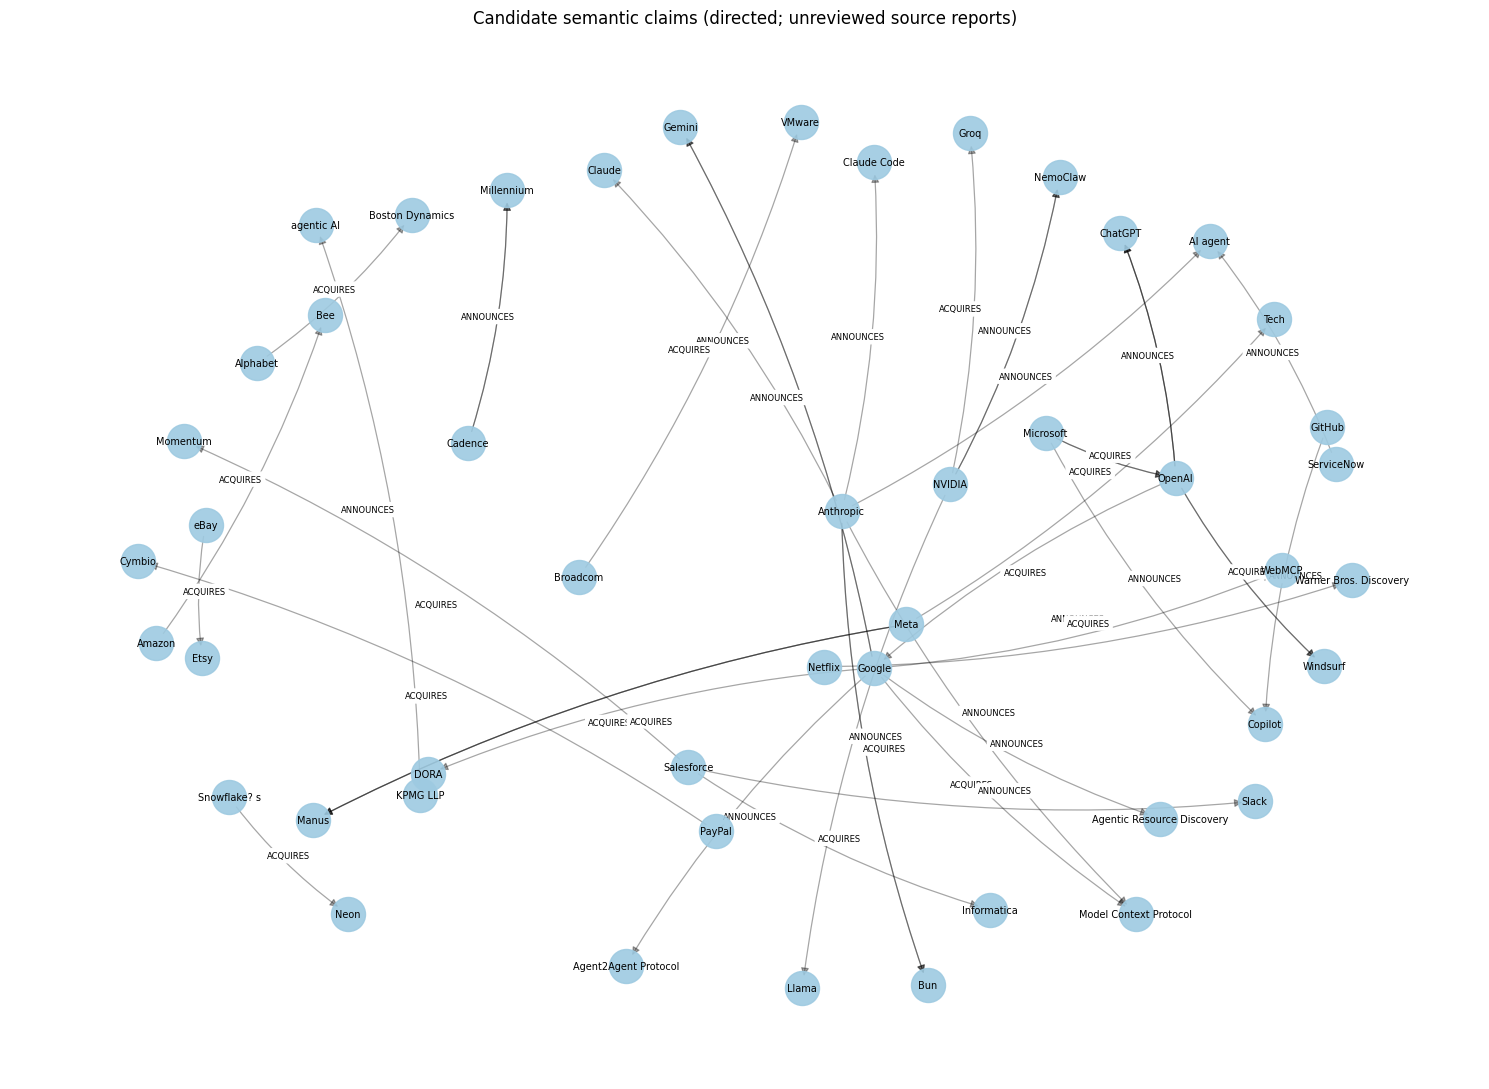

In [19]:
CLAIM_SCHEMA_VERSION = "agentic-claim-v1"
RELATION_DOMAIN_RANGE = {
    "USES": ({"ORGANIZATION", "PERSON", "AI_PRODUCT", "AI_MODEL", "FRAMEWORK", "PRODUCT", "PROTOCOL", "AI_TECHNOLOGY"},
             {"AI_PRODUCT", "AI_MODEL", "FRAMEWORK", "PRODUCT", "PROTOCOL", "AI_TECHNOLOGY"}),
    "INTEGRATES_WITH": ({"ORGANIZATION", "PERSON", "AI_PRODUCT", "AI_MODEL", "FRAMEWORK", "PRODUCT", "PROTOCOL", "AI_TECHNOLOGY"},
                        {"ORGANIZATION", "AI_PRODUCT", "AI_MODEL", "FRAMEWORK", "PRODUCT", "PROTOCOL", "AI_TECHNOLOGY"}),
    "DEVELOPS": ({"ORGANIZATION"}, {"AI_PRODUCT", "AI_MODEL", "FRAMEWORK", "PRODUCT", "PROTOCOL", "AI_TECHNOLOGY"}),
    "BUILDS_ON": ({"AI_PRODUCT", "AI_MODEL", "FRAMEWORK", "PRODUCT", "ORGANIZATION"},
                  {"AI_PRODUCT", "AI_MODEL", "FRAMEWORK", "PRODUCT", "PROTOCOL", "AI_TECHNOLOGY"}),
    "RELEASES": ({"ORGANIZATION"}, {"AI_PRODUCT", "AI_MODEL", "FRAMEWORK", "PRODUCT", "PROTOCOL", "AI_TECHNOLOGY"}),
    "ANNOUNCES": ({"ORGANIZATION"}, {"AI_PRODUCT", "AI_MODEL", "FRAMEWORK", "PRODUCT", "PROTOCOL", "AI_TECHNOLOGY"}),
    "PARTNERS_WITH": ({"ORGANIZATION"}, {"ORGANIZATION"}),
    "ACQUIRES": ({"ORGANIZATION"}, {"ORGANIZATION", "AI_PRODUCT", "PRODUCT"}),
    "POWERED_BY": ({"AI_PRODUCT", "AI_MODEL", "FRAMEWORK", "PRODUCT", "PROTOCOL", "AI_TECHNOLOGY"},
                   {"ORGANIZATION", "AI_PRODUCT", "AI_MODEL", "FRAMEWORK", "PRODUCT", "PROTOCOL", "AI_TECHNOLOGY"}),
}
ACTIVE_RELATION_PATTERNS = [
    ("BUILDS_ON", re.compile(r"\b(?:build(?:s|ing)?|built)\s+on(?:\s+top\s+of)?\b", re.IGNORECASE), False),
    ("PARTNERS_WITH", re.compile(r"\b(?:partner(?:s|ed|ing)?\s+with|team(?:s|ed)?\s+up\s+with|collaborat(?:e|es|ed|ing)\s+with)\b", re.IGNORECASE), False),
    ("INTEGRATES_WITH", re.compile(r"\b(?:integrat(?:e|es|ed|ing)\s+(?:with|into)|connect(?:s|ed|ing)?\s+(?:to|with))\b", re.IGNORECASE), False),
    ("ACQUIRES", re.compile(r"\b(?:acquir(?:e|es|ed|ing)|buys|bought)\b", re.IGNORECASE), False),
    ("RELEASES", re.compile(r"\b(?:releas(?:e|es|ed|ing)|launch(?:es|ed|ing)?|introduc(?:e|es|ed|ing)|unveil(?:s|ed|ing))\b", re.IGNORECASE), False),
    ("ANNOUNCES", re.compile(r"\bannounc(?:e|es|ed|ing)\b", re.IGNORECASE), False),
    ("DEVELOPS", re.compile(r"\b(?:develop(?:s|ed|ing)?|build(?:s|ing)?|built|creat(?:e|es|ed|ing)|design(?:s|ed|ing)|train(?:s|ed|ing))\b", re.IGNORECASE), False),
    ("USES", re.compile(r"\b(?:use[sd]?|using|utili[sz]e[sd]?|utili[sz]ing|adopt[sd]?|adopting|deploy[sd]?|deploying|leverage[sd]?|leveraging)\b", re.IGNORECASE), False),
    ("POWERED_BY", re.compile(r"\bpower(?:s|ed|ing)?\b", re.IGNORECASE), True),
]
PASSIVE_RELATION_PATTERNS = [
    ("USES", re.compile(r"\b(?:(?:is|are|was|were|has been|have been|had been)\s+)?(?:used|deployed)\s+by\b", re.IGNORECASE), True),
    ("DEVELOPS", re.compile(r"\b(?:(?:is|are|was|were|has been|have been|had been)\s+)?(?:developed|built|created|designed|trained)\s+by\b", re.IGNORECASE), True),
    ("RELEASES", re.compile(r"\b(?:(?:is|are|was|were|has been|have been|had been)\s+)?(?:released|launched|introduced|unveiled)\s+by\b", re.IGNORECASE), True),
    ("ANNOUNCES", re.compile(r"\b(?:(?:is|are|was|were|has been|have been|had been)\s+)?announced\s+by\b", re.IGNORECASE), True),
    ("ACQUIRES", re.compile(r"\b(?:(?:is|are|was|were|has been|have been|had been)\s+)?(?:acquired|bought)\s+by\b", re.IGNORECASE), True),
    ("POWERED_BY", re.compile(r"\b(?:(?:is|are|was|were|has been|have been|had been)\s+)?powered\s+by\b", re.IGNORECASE), False),
]
PLANNED_CUE = re.compile(r"\b(?:will|plan(?:s|ned)?\s+to|aim(?:s|ed)?\s+to|intend(?:s|ed)?\s+to|set\s+to|expected\s+to|in\s+(?:talks|discussions)\s+to|propos(?:e|es|ed)\s+to|interest\s+in)\b", re.IGNORECASE)
CONDITIONAL_CUE = re.compile(r"\b(?:could|may|might|would|potentially|consider(?:s|ed|ing)?)\b", re.IGNORECASE)
NEGATION_CUE = re.compile(r"\b(?:not|never|no\s+longer|cannot|can't|didn't|doesn't|don't|isn't|wasn't|weren't|won't)\b", re.IGNORECASE)
SENTENCE_SPLITTER = re.compile(r"(?<=[.!?])\s+|[\r\n]+")

ner_input_by_article = dict(zip(ner_article_ids, ner_inputs, strict=True))
for article_id, sentences in article_sentences.items():
    document = ner_input_by_article[article_id]
    search_from = 0
    for sentence in sentences:
        start = document.find(sentence["text"], search_from)
        if start < 0:
            raise ValueError(f"Cannot align NER sentence to source text for article_id={article_id}")
        sentence["start_char"] = start
        sentence["end_char"] = start + len(sentence["text"])
        search_from = sentence["end_char"]
        if any(mention["start_char"] < start or mention["end_char"] > sentence["end_char"]
               for mention in sentence["entities"]):
            raise ValueError(f"Entity mention falls outside its sentence span for article_id={article_id}")

article_metadata_by_id = agentic.set_index("article_id", drop=False)
claim_records = []
for article_id, sentences in article_sentences.items():
    source_row = article_metadata_by_id.loc[article_id]
    document = ner_input_by_article[article_id]
    for sentence in sentences:
        sentence_start, sentence_end = sentence["start_char"], sentence["end_char"]
        ordered = sorted(sentence["entities"], key=lambda item: (item["start_char"], -(item["end_char"] - item["start_char"])))
        disjoint_mentions = []
        for mention in ordered:
            if disjoint_mentions and mention["start_char"] < disjoint_mentions[-1]["end_char"]:
                continue
            disjoint_mentions.append(mention)
        for left, right in zip(disjoint_mentions, disjoint_mentions[1:]):
            if left["entity_id"] == right["entity_id"] or left["end_char"] > right["start_char"]:
                continue
            gap = document[left["end_char"]:right["start_char"]]
            if len(gap) > 80 or re.search(r"[,;:]|\b(?:and|but|or|while|whereas)\b", gap, re.IGNORECASE):
                continue
            matched = None
            for predicate, pattern, reverse in PASSIVE_RELATION_PATTERNS:
                match = pattern.search(gap)
                if match:
                    matched = (predicate, match, reverse)
                    break
            if matched is None:
                for predicate, pattern, reverse in ACTIVE_RELATION_PATTERNS:
                    match = pattern.search(gap)
                    if match is None:
                        continue
                    preceding = gap[:match.start()]
                    following = gap[match.end():]
                    if predicate in {"USES", "DEVELOPS", "RELEASES", "ANNOUNCES"} and re.search(
                        r"\b(?:is|are|was|were|been|being)\s+(?:\w+\s+){0,2}$", preceding, re.IGNORECASE
                    ):
                        continue
                    if predicate == "RELEASES" and re.match(r"\s+under\b", following, re.IGNORECASE):
                        continue
                    matched = (predicate, match, reverse)
                    break
            if matched is None:
                continue
            predicate, cue_match, reverse = matched
            if len(gap[:cue_match.start()].split()) > 2 or len(gap[cue_match.end():].split()) > 3:
                continue
            subject, object_ = (right, left) if reverse else (left, right)
            domain_types, range_types = RELATION_DOMAIN_RANGE[predicate]
            if subject["entity_type"] not in domain_types or object_["entity_type"] not in range_types:
                continue
            cue_start = left["end_char"] + cue_match.start()
            cue_end = left["end_char"] + cue_match.end()
            cue_context = document[max(sentence_start, cue_start - 35):min(sentence_end, cue_end + 35)]
            polarity = "negated" if NEGATION_CUE.search(gap) else "positive_or_unmarked"
            if polarity == "negated":
                modality = "negated"
            elif PLANNED_CUE.search(cue_context):
                modality = "planned_or_proposed"
            elif CONDITIONAL_CUE.search(cue_context):
                modality = "conditional_or_considered"
            else:
                modality = "unmarked"
            publication_date = pd.Timestamp(source_row["date"]).date().isoformat() if pd.notna(source_row["date"]) else None
            claim_id_seed = "|".join(map(str, [CLAIM_SCHEMA_VERSION, article_id, predicate,
                subject["entity_id"], object_["entity_id"], sentence_start, sentence_end,
                subject["start_char"], subject["end_char"], object_["start_char"], object_["end_char"]]))
            claim_id = hashlib.sha256(claim_id_seed.encode("utf-8")).hexdigest()[:24]
            claim_records.append({
                "claim_id": claim_id, "schema_version": CLAIM_SCHEMA_VERSION,
                "article_id": str(article_id), "source_id": str(article_id),
                "source_domain": str(source_row["source"]), "source_url": str(source_row["url"]),
                "source_title": str(source_row["title"]), "published_at": publication_date,
                "event_time": None, "event_time_status": "not_extracted",
                "subject_id": subject["entity_id"], "subject_surface": subject["surface_form"],
                "subject_type": subject["entity_type"], "subject_start_char": int(subject["start_char"]),
                "subject_end_char": int(subject["end_char"]), "predicate": predicate,
                "object_id": object_["entity_id"], "object_surface": object_["surface_form"],
                "object_type": object_["entity_type"], "object_start_char": int(object_["start_char"]),
                "object_end_char": int(object_["end_char"]), "relation_kind": "explicit_relation_candidate",
                "evidence_sentence_id": f"{article_id}:{sentence_start}:{sentence_end}",
                "evidence_text": sentence["text"], "evidence_start_char": int(sentence_start),
                "evidence_end_char": int(sentence_end), "relation_cue_text": cue_match.group(0),
                "relation_cue_start_char": int(cue_start), "relation_cue_end_char": int(cue_end),
                "polarity": polarity, "modality": modality,
                "temporal_status": modality if modality != "unmarked" else "event_time_unresolved",
                "extraction_method": "typed_lexical_template_v1", "confidence": None,
                "validation_status": "unreviewed_candidate",
            })

claim_columns = [
    "claim_id", "schema_version", "article_id", "source_id", "source_domain", "source_url", "source_title",
    "published_at", "event_time", "event_time_status", "subject_id", "subject_surface", "subject_type",
    "subject_start_char", "subject_end_char", "predicate", "object_id", "object_surface", "object_type",
    "object_start_char", "object_end_char", "relation_kind", "evidence_sentence_id", "evidence_text",
    "evidence_start_char", "evidence_end_char", "relation_cue_text", "relation_cue_start_char",
    "relation_cue_end_char", "polarity", "modality", "temporal_status", "extraction_method", "confidence",
    "validation_status",
]
explicit_claims = pd.DataFrame.from_records(claim_records, columns=claim_columns)
if not explicit_claims.empty:
    if explicit_claims["claim_id"].duplicated().any():
        raise AssertionError("Claim IDs must be unique.")
    if not explicit_claims["subject_id"].ne(explicit_claims["object_id"]).all():
        raise AssertionError("Self-relations are excluded from explicit claim candidates.")

entity_aliases = (entities.groupby(["entity_id", "canonical_name", "entity_type", "surface_form", "extraction_method"], dropna=False)
                  .agg(mention_count=("article_id", "size"), source_article_count=("article_id", "nunique"))
                  .reset_index())
entity_aliases["normalization_status"] = np.where(
    entity_aliases["extraction_method"].isin(["domain_alias_lexicon", "spacy_variant_linked_to_lexicon"]),
    "domain_alias_linked", "surface_form_identity_only_not_disambiguated")

relation_schema = pd.DataFrame([
    {"predicate": predicate, "domain_types": "|".join(sorted(domain)), "range_types": "|".join(sorted(range_)),
     "direction": "subject_to_object_as_stated_or_voice-normalized", "schema_version": CLAIM_SCHEMA_VERSION}
    for predicate, (domain, range_) in RELATION_DOMAIN_RANGE.items()
])
knowledge_graph_schema = {
    "schema_version": CLAIM_SCHEMA_VERSION,
    "entity_types": ["ORGANIZATION", "PERSON", "PRODUCT", "AI_PRODUCT", "AI_MODEL", "FRAMEWORK", "PROTOCOL", "AI_TECHNOLOGY"],
    "entity_mention_fields": ["article_id", "entity_id", "surface_form", "canonical_name", "entity_type", "start_char", "end_char", "extraction_method", "confidence"],
    "normalization_policy": "Curated domain aliases link to stable lexicon IDs; spaCy-only mentions retain surface-derived IDs without disambiguation; NIL linking is not implemented.",
    "predicates": {predicate: {"domain_types": sorted(domain), "range_types": sorted(range_),
                                "direction": "subject_to_object_as_stated_or_voice-normalized"}
                   for predicate, (domain, range_) in RELATION_DOMAIN_RANGE.items()},
    "claim_fields": claim_columns,
    "cooccurrence_relation": {"predicate": "MENTIONED_WITH", "relation_kind": "cooccurrence", "graph_type": "undirected Graph"},
    "semantic_claim_graph": {"graph_type": "directed MultiDiGraph", "edge_status": "unreviewed relation candidates"},
    "time_policy": "published_at is the dataset publication date; event_time remains null unless independently annotated.",
    "evidence_offset_basis": "title + newline + first 2,500 characters of text_clean",
    "confidence_policy": "Uncalibrated confidence is null; no confidence score is fabricated.",
}

relation_review_rows = []
for predicate, group in explicit_claims.groupby("predicate", sort=True):
    sample = group.sample(n=min(6, len(group)), random_state=SEED)
    for row in sample.itertuples(index=False):
        relation_review_rows.append({
            "claim_id": row.claim_id, "article_id": row.article_id, "predicate_predicted": row.predicate,
            "subject_predicted": row.subject_id, "object_predicted": row.object_id,
            "source_domain": row.source_domain, "source_url": row.source_url, "published_at": row.published_at,
            "evidence_text": row.evidence_text, "evidence_start_char": row.evidence_start_char,
            "evidence_end_char": row.evidence_end_char, "polarity_predicted": row.polarity,
            "modality_predicted": row.modality, "manual_label": "", "gold_predicate": "",
            "gold_subject_id": "", "gold_object_id": "", "reviewer_notes": "",
        })
relation_review = pd.DataFrame(relation_review_rows)

entity_review_rows = []
for (entity_type, extraction_method), group in entities.groupby(["entity_type", "extraction_method"], sort=True):
    sample = group.sample(n=min(4, len(group)), random_state=SEED)
    for row in sample.itertuples(index=False):
        article_id = row.article_id
        document = ner_input_by_article[article_id]
        start = max(0, int(row.start_char) - 90)
        end = min(len(document), int(row.end_char) + 90)
        entity_review_rows.append({
            "article_id": str(article_id), "entity_id_predicted": row.entity_id,
            "surface_form": row.surface_form, "canonical_name_predicted": row.canonical_name,
            "entity_type_predicted": row.entity_type, "start_char": int(row.start_char),
            "end_char": int(row.end_char), "extraction_method": row.extraction_method,
            "context_text": document[start:end], "manual_label": "", "gold_entity_type": "",
            "gold_canonical_name": "", "reviewer_notes": "",
        })
entity_review = pd.DataFrame(entity_review_rows)

semantic_graph = nx.MultiDiGraph(graph_semantics="unreviewed directed relation claim candidates", schema_version=CLAIM_SCHEMA_VERSION)
entity_node_summary = entities.groupby("entity_id").agg(
    label=("canonical_name", "first"), entity_type=("entity_type", "first"),
    mention_count=("entity_id", "size"), source_article_count=("article_id", "nunique"))
for entity_identifier, node in entity_node_summary.iterrows():
    semantic_graph.add_node(entity_identifier, label=str(node["label"]), entity_type=str(node["entity_type"]),
                            mention_count=int(node["mention_count"]), source_article_count=int(node["source_article_count"]))
for row in explicit_claims.itertuples(index=False):
    semantic_graph.add_edge(
        row.subject_id, row.object_id, key=row.claim_id, claim_id=row.claim_id,
        predicate=row.predicate, relation_kind=row.relation_kind, source_id=row.source_id,
        source_domain=row.source_domain, source_url=row.source_url, published_at=row.published_at or "",
        event_time="", event_time_status=row.event_time_status, modality=row.modality,
        polarity=row.polarity, temporal_status=row.temporal_status,
        evidence_sentence_id=row.evidence_sentence_id, evidence_text=row.evidence_text,
        evidence_start_char=int(row.evidence_start_char), evidence_end_char=int(row.evidence_end_char),
        relation_cue_text=row.relation_cue_text, relation_cue_start_char=int(row.relation_cue_start_char),
        relation_cue_end_char=int(row.relation_cue_end_char), extraction_method=row.extraction_method,
        validation_status=row.validation_status, schema_version=row.schema_version)

semantic_components = list(nx.weakly_connected_components(semantic_graph)) if semantic_graph.number_of_nodes() else []
semantic_centrality = nx.degree_centrality(semantic_graph) if semantic_graph.number_of_nodes() > 1 else {node: 0.0 for node in semantic_graph.nodes}
semantic_graph_summary = pd.DataFrame([{
    "nodes": semantic_graph.number_of_nodes(), "directed_claim_edges": semantic_graph.number_of_edges(),
    "unique_claims": len(explicit_claims), "source_articles": explicit_claims["article_id"].nunique() if not explicit_claims.empty else 0,
    "weakly_connected_components": len(semantic_components),
    "isolated_nodes": sum(1 for _, degree in semantic_graph.degree() if degree == 0),
    "graph_type": "directed MultiDiGraph", "edge_semantics": "unreviewed, evidence-linked relation candidates",
}])
print("Directed relation candidates by predicate:")
display(explicit_claims["predicate"].value_counts().rename_axis("predicate").to_frame("candidate_count"))
print("Directed claim graph summary:")
display(semantic_graph_summary)
if semantic_graph.number_of_nodes():
    centrality_rows = sorted(semantic_centrality.items(), key=lambda item: item[1], reverse=True)[:15]
    display(pd.DataFrame([{"entity_id": node, "label": semantic_graph.nodes[node]["label"],
                           "entity_type": semantic_graph.nodes[node]["entity_type"],
                           "directed_degree_centrality": score} for node, score in centrality_rows]))
print(f"Unlabeled entity review worksheet: {len(entity_review):,} examples; relation review worksheet: {len(relation_review):,} examples. Human quality metrics are withheld.")

if explicit_claims.empty:
    semantic_nodes_table = pd.DataFrame(columns=["entity_id", "label", "entity_type", "mention_count", "source_article_count"])
    semantic_edge_table = pd.DataFrame(columns=["source_entity_id", "target_entity_id", "claim_id", "predicate"])
else:
    semantic_nodes_table = pd.DataFrame([{"entity_id": node, **attrs} for node, attrs in semantic_graph.nodes(data=True)])
    semantic_edge_table = pd.DataFrame([
        {"source_entity_id": source, "target_entity_id": target, **attrs}
        for source, target, attrs in semantic_graph.edges(data=True)
    ])

if explicit_claims.empty:
    print("No typed lexical relation candidates matched the observed corpus; the semantic claim graph is empty.")
else:
    ranked_claims = explicit_claims.sort_values(["predicate", "claim_id"]).head(45)
    visual_graph = nx.MultiDiGraph()
    for row in ranked_claims.itertuples(index=False):
        visual_graph.add_node(row.subject_id, **semantic_graph.nodes[row.subject_id])
        visual_graph.add_node(row.object_id, **semantic_graph.nodes[row.object_id])
        visual_graph.add_edge(row.subject_id, row.object_id, predicate=row.predicate)
    positions = nx.spring_layout(nx.DiGraph(visual_graph), seed=SEED, k=0.9)
    plt.figure(figsize=(15, 11))
    nx.draw_networkx_nodes(visual_graph, positions, node_size=600, node_color="#9ecae1", alpha=.9)
    nx.draw_networkx_edges(visual_graph, positions, arrows=True, arrowsize=12, alpha=.35, width=.9,
                           connectionstyle="arc3,rad=0.08")
    labels = {node: semantic_graph.nodes[node]["label"].encode("ascii", "replace").decode("ascii")[:28]
              for node in visual_graph.nodes}
    nx.draw_networkx_labels(visual_graph, positions, labels=labels, font_size=7)
    nx.draw_networkx_edge_labels(visual_graph, positions,
                                 edge_labels={(u, v): data["predicate"] for u, v, data in visual_graph.edges(data=True)},
                                 font_size=6, rotate=False)
    plt.title("Candidate semantic claims (directed; unreviewed source reports)")
    plt.axis("off")
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / "semantic_claim_graph.png", dpi=170)
    plt.show()


### 7.1 LangExtract pilot: LLM-based structured extraction (brief p. 3)

**Why.** The brief asks for LangExtract or a comparable structured extraction approach to improve entity and relation extraction. The template extractor above is schema-constrained but lexical. This pilot applies LangExtract with an OpenAI model (`gpt-4o-mini`, temperature 0) to a small, fixed-seed sample and compares it with the pipeline.

**Design.**
- *Sample:* 50 selected articles (fixed seed): 25 where the template extractor found at least one candidate and 25 where it found none, so the comparison also shows what templates miss.
- *Input:* the same text the NER sees (title plus first 2,500 characters), so offsets are directly comparable. Each article is one chunk.
- *Schema-first:* the same entity types and the *same nine relation predicates* as section 7. The few-shot example is fictional on purpose.
- *Grounding validation:* LangExtract aligns every extraction to character offsets in the source. A relation is **accepted** only if its predicate is in the schema, its evidence span is aligned, and that span names both the subject and the object. Every rejected relation keeps its reason. Domain/range type consistency is recorded but does not reject.
- *Linking:* subject/object strings are linked to the domain lexicon where possible, with the same normalization as section 6.

**What this does and does not show.** Grounding validation shows an extraction is traceable to the source text; it does **not** show that the evidence states the relation. The comparison with templates measures *overlap*, not accuracy, because no human labels exist. All outputs are unreviewed candidates. The LLM can hallucinate, drift across model versions and cost money, so raw responses are cached locally (`outputs/llm_cache/`, git-ignored) and the notebook re-uses the cache instead of calling the API again. The API key is read from the git-ignored `.env`; it is never printed or stored in any output, and a structural check verifies that it does not appear in this notebook.

**Data sent to a third party.** Article text (public dataset) for the 50 pilot articles is sent to OpenAI when the cache is empty and a key is present. Without a key or cache, the pilot is skipped and requirement R11 stays PARTIAL.

In [20]:
import hashlib
import logging
import os
from concurrent.futures import ThreadPoolExecutor

from dotenv import dotenv_values

logging.getLogger("absl").setLevel(logging.ERROR)  # LangExtract warns once per call about few-shot alignment; not informative here

try:
    import langextract as lx
except ImportError:  # the pilot is skipped (and R11 stays PARTIAL) when LangExtract is not installed
    lx = None

LLM_MODEL_ID = "gpt-4o-mini"
LLM_PILOT_PER_STRATUM = 25
LLM_CACHE_PATH = ROOT / "outputs" / "llm_cache" / f"langextract_pilot_{LLM_MODEL_ID}.jsonl"
PREDICATE_DEFINITIONS = {
    "RELEASES": "subject launches, releases, ships or open-sources the object (a product, model, framework or protocol)",
    "ANNOUNCES": "subject announces, unveils or introduces the object",
    "DEVELOPS": "subject develops, builds, creates or maintains the object",
    "USES": "subject uses, adopts, relies on or deploys the object",
    "INTEGRATES_WITH": "subject integrates with, supports or connects to the object",
    "PARTNERS_WITH": "subject partners or collaborates with the object (an organization)",
    "ACQUIRES": "subject acquires or buys the object (an organization)",
    "BUILDS_ON": "subject is built on, based on or extends the object",
    "POWERED_BY": "subject is powered by or runs on the object",
}
assert set(PREDICATE_DEFINITIONS) == set(RELATION_DOMAIN_RANGE), "LLM schema must use exactly the notebook's relation schema"
LLM_PROMPT = (
    "Extract named entities and explicit, directed relations from a news or blog article about autonomous AI agents.\n"
    "Entity extractions: extraction_class 'entity'; extraction_text is the exact name as written; attributes: type, one of "
    "[ORGANIZATION, PERSON, AI_PRODUCT, AI_MODEL, FRAMEWORK, PROTOCOL, AI_TECHNOLOGY].\n"
    "Relation extractions: extraction_class 'relation'; extraction_text is the exact sentence or clause that states the relation; "
    "attributes: subject (exact entity text as written), predicate (one of " + ", ".join(PREDICATE_DEFINITIONS) + "), object (exact entity text as written).\n"
    "Predicate meanings: " + "; ".join(f"{name}: {meaning}" for name, meaning in PREDICATE_DEFINITIONS.items()) + ".\n"
    "Rules: only extract a relation if the text explicitly states it; do not infer from world knowledge; skip negated, hypothetical or "
    "speculative statements; keep the direction as stated (the subject acts on, or is related to, the object); use exact text from the article."
)
# Few-shot example text is fictional on purpose, so that it cannot be mistaken for a finding.
EXAMPLE_TEXT = ("Acme Labs released the FooKit framework last week. FooKit is built on the open Bar Protocol. FooKit works with Zed Cloud.")
llm_prompt_sha = hashlib.sha256((LLM_PROMPT + EXAMPLE_TEXT + LLM_MODEL_ID).encode()).hexdigest()[:16]

# Fixed-seed pilot sample: half the articles where the template extractor found candidates, half where it found none.
article_id_str = agentic["article_id"].astype(str)
has_template = article_id_str.isin(set(explicit_claims["article_id"].astype(str)))
pilot_articles = pd.concat([
    agentic[has_template].sample(n=min(LLM_PILOT_PER_STRATUM, int(has_template.sum())), random_state=SEED).assign(pilot_stratum="template_candidates_found"),
    agentic[~has_template].sample(n=min(LLM_PILOT_PER_STRATUM, int((~has_template).sum())), random_state=SEED).assign(pilot_stratum="no_template_candidate"),
]).sort_values("article_id").reset_index(drop=True)
pilot_text = {str(row.article_id): ner_input_by_article[row.article_id] for row in pilot_articles.itertuples()}

# Cache of raw LangExtract responses (gitignored; contains article text, never the API key).
cache = {}
if LLM_CACHE_PATH.is_file():
    for line in LLM_CACHE_PATH.read_text(encoding="utf-8").splitlines():
        record = json.loads(line)
        if record.get("prompt_sha") == llm_prompt_sha:
            cache[record["article_id"]] = record
llm_api_key = dotenv_values(ROOT / ".env").get("LANGEXTRACT_API_KEY") or os.environ.get("LANGEXTRACT_API_KEY")
missing_ids = [aid for aid in pilot_text if aid not in cache]
llm_api_calls, llm_api_failures = 0, []
if missing_ids and lx is not None and llm_api_key:
    examples = [lx.data.ExampleData(text=EXAMPLE_TEXT, extractions=[
        lx.data.Extraction(extraction_class="entity", extraction_text="Acme Labs", attributes={"type": "ORGANIZATION"}),
        lx.data.Extraction(extraction_class="entity", extraction_text="FooKit", attributes={"type": "FRAMEWORK"}),
        lx.data.Extraction(extraction_class="entity", extraction_text="Bar Protocol", attributes={"type": "PROTOCOL"}),
        lx.data.Extraction(extraction_class="entity", extraction_text="Zed Cloud", attributes={"type": "AI_PRODUCT"}),
        lx.data.Extraction(extraction_class="relation", extraction_text="Acme Labs released the FooKit framework last week.",
                           attributes={"subject": "Acme Labs", "predicate": "RELEASES", "object": "FooKit"}),
        lx.data.Extraction(extraction_class="relation", extraction_text="FooKit is built on the open Bar Protocol.",
                           attributes={"subject": "FooKit", "predicate": "BUILDS_ON", "object": "Bar Protocol"}),
        lx.data.Extraction(extraction_class="relation", extraction_text="FooKit works with Zed Cloud.",
                           attributes={"subject": "FooKit", "predicate": "INTEGRATES_WITH", "object": "Zed Cloud"}),
    ])]

    def call_langextract(article_id: str) -> dict:
        result = lx.extract(text_or_documents=pilot_text[article_id], prompt_description=LLM_PROMPT, examples=examples, model_id=LLM_MODEL_ID,
                            api_key=llm_api_key, temperature=0.0, fence_output=True, use_schema_constraints=False, max_char_buffer=3000, show_progress=False)
        return {"article_id": article_id, "prompt_sha": llm_prompt_sha, "model": LLM_MODEL_ID, "extractions": [
            {"extraction_class": item.extraction_class, "extraction_text": item.extraction_text, "attributes": dict(item.attributes or {}),
             "start": item.char_interval.start_pos if item.char_interval else None, "end": item.char_interval.end_pos if item.char_interval else None,
             "alignment": item.alignment_status.name if getattr(item, "alignment_status", None) else None} for item in result.extractions]}

    def safe_call(article_id: str):
        try:
            return call_langextract(article_id)
        except Exception as exc:  # keep the pilot going; failures are reported, never hidden
            return {"article_id": article_id, "error": f"{type(exc).__name__}: {str(exc)[:200]}".replace(llm_api_key, "<key>")}

    with ThreadPoolExecutor(max_workers=4) as pool:
        results = list(pool.map(safe_call, missing_ids))
    LLM_CACHE_PATH.parent.mkdir(parents=True, exist_ok=True)
    with LLM_CACHE_PATH.open("a", encoding="utf-8") as handle:
        for record in results:
            llm_api_calls += 1
            if "error" in record:
                llm_api_failures.append(record)
            else:
                cache[record["article_id"]] = record
                handle.write(json.dumps(record, ensure_ascii=False) + "\n")
llm_pilot_ran = len(cache) > 0
print(f"LangExtract pilot: model={LLM_MODEL_ID}, prompt hash={llm_prompt_sha}; {len(pilot_text)} pilot articles, {len(cache)} with responses "
      f"({llm_api_calls} API calls this run, {len(llm_api_failures)} failures; the rest came from the local cache).")
if llm_api_failures:
    print("Failures:", [(item["article_id"], item["error"]) for item in llm_api_failures][:5])
if not llm_pilot_ran:
    print("No LangExtract responses are available (package, key or cache missing): the pilot is skipped and requirement R11 stays PARTIAL.")

# --- Parsing, grounding validation and linking -------------------------------------------------------------------
def resolve_surface(surface: str):
    """Link a surface string to the domain lexicon when possible (same rules as the NER section)."""
    cleaned = " ".join(surface.split())
    return lookup_alias(cleaned) or LEXICON_KEY_MAP.get(name_key(cleaned))


def comparison_key(surface: str) -> str:
    resolved = resolve_surface(surface)
    return name_key(resolved[0]) if resolved else name_key(re.sub(r"^the\s+", "", surface, flags=re.IGNORECASE))


pipeline_keys = defaultdict(set)
for row in entities.itertuples(index=False):
    pipeline_keys[str(row.article_id)].update({name_key(row.canonical_name), name_key(row.surface_form)})
article_meta = agentic.assign(article_key=article_id_str).set_index("article_key")[["source", "date"]]
llm_entity_rows, llm_relation_rows = [], []
for article_id, record in cache.items():
    if article_id not in pilot_text:
        continue
    text = pilot_text[article_id]
    typed_entities = {}
    for item in record["extractions"]:
        if item["extraction_class"] == "entity":
            entity_type = str(item["attributes"].get("type", "")).upper()
            typed_entities[name_key(item["extraction_text"])] = entity_type
            llm_entity_rows.append({"article_id": article_id, "text": item["extraction_text"], "llm_type": entity_type, "start_char": item["start"], "end_char": item["end"],
                                    "alignment": item["alignment"], "found_by_pipeline_ner": bool({name_key(item["extraction_text"]), comparison_key(item["extraction_text"])} & pipeline_keys[article_id])})
    for item in record["extractions"]:
        if item["extraction_class"] != "relation":
            continue
        subject_text, predicate, object_text = (str(item["attributes"].get(key, "")).strip() for key in ("subject", "predicate", "object"))
        predicate = predicate.upper()
        start, end = item["start"], item["end"]
        reasons = []
        if predicate not in PREDICATE_DEFINITIONS:
            reasons.append("predicate_not_in_schema")
        if start is None or end is None:
            reasons.append("evidence_not_aligned_to_source")
        else:
            evidence_span = text[start:end]
            if subject_text.casefold() not in evidence_span.casefold():
                reasons.append("subject_not_named_in_evidence")
            if object_text.casefold() not in evidence_span.casefold():
                reasons.append("object_not_named_in_evidence")
        if not subject_text or not object_text or comparison_key(subject_text) == comparison_key(object_text):
            reasons.append("empty_or_self_relation")
        subject_link, object_link = resolve_surface(subject_text), resolve_surface(object_text)
        subject_type = subject_link[1] if subject_link else typed_entities.get(name_key(subject_text))
        object_type = object_link[1] if object_link else typed_entities.get(name_key(object_text))
        gate = None
        if predicate in RELATION_DOMAIN_RANGE and subject_type and object_type:
            gate = bool(subject_type in RELATION_DOMAIN_RANGE[predicate][0] and object_type in RELATION_DOMAIN_RANGE[predicate][1])
        llm_relation_rows.append({
            "llm_relation_id": hashlib.sha1(f"{article_id}|{predicate}|{subject_text}|{object_text}|{start}".encode()).hexdigest()[:20],
            "article_id": article_id, "source_domain": article_meta.loc[article_id, "source"], "published_at": str(article_meta.loc[article_id, "date"])[:10],
            "subject_text": subject_text, "predicate": predicate, "object_text": object_text,
            "subject_id": entity_id(subject_link[0], subject_link[1]) if subject_link else None, "object_id": entity_id(object_link[0], object_link[1]) if object_link else None,
            "subject_llm_or_lexicon_type": subject_type, "object_llm_or_lexicon_type": object_type, "domain_range_consistent": gate,
            "evidence_text": text[start:end] if start is not None and end is not None else None, "evidence_start_char": start, "evidence_end_char": end,
            "alignment": item["alignment"], "validation_status": "unreviewed_candidate", "extraction_method": f"langextract_openai_{LLM_MODEL_ID}",
            "grounding_status": "accepted" if not reasons else "rejected", "rejection_reasons": "|".join(reasons),
        })
llm_entities = pd.DataFrame(llm_entity_rows, columns=["article_id", "text", "llm_type", "start_char", "end_char", "alignment", "found_by_pipeline_ner"])
llm_relations = pd.DataFrame(llm_relation_rows, columns=[
    "llm_relation_id", "article_id", "source_domain", "published_at", "subject_text", "predicate", "object_text", "subject_id", "object_id",
    "subject_llm_or_lexicon_type", "object_llm_or_lexicon_type", "domain_range_consistent", "evidence_text", "evidence_start_char", "evidence_end_char",
    "alignment", "validation_status", "extraction_method", "grounding_status", "rejection_reasons"])
llm_accepted = llm_relations[llm_relations["grounding_status"].eq("accepted")].reset_index(drop=True)

# --- Comparison with the template candidates on the same articles (overlap, not accuracy) -----------------------
pilot_ids = set(cache) & set(pilot_text)
template_pilot = explicit_claims[explicit_claims["article_id"].astype(str).isin(pilot_ids)].copy()
template_pilot["subject_key"] = template_pilot["subject_surface"].map(comparison_key)
template_pilot["object_key"] = template_pilot["object_surface"].map(comparison_key)
llm_accepted = llm_accepted.assign(subject_key=llm_accepted["subject_text"].map(comparison_key), object_key=llm_accepted["object_text"].map(comparison_key))
llm_triples = set(zip(llm_accepted["article_id"], llm_accepted["subject_key"], llm_accepted["predicate"], llm_accepted["object_key"]))
llm_pairs = {(article, frozenset((subject, obj))) for article, subject, obj in zip(llm_accepted["article_id"], llm_accepted["subject_key"], llm_accepted["object_key"])}
template_pilot["llm_agreement"] = [
    "same_pair_predicate_and_direction" if (str(a), s, p, o) in llm_triples else
    "same_pair_other_predicate_or_direction" if (str(a), frozenset((s, o))) in llm_pairs else "template_only"
    for a, s, p, o in zip(template_pilot["article_id"], template_pilot["subject_key"], template_pilot["predicate"], template_pilot["object_key"])]
template_pairs = {(str(a), frozenset((s, o))) for a, s, o in zip(template_pilot["article_id"], template_pilot["subject_key"], template_pilot["object_key"])}
llm_accepted["template_agreement"] = [
    "also_template_candidate" if (a, frozenset((s, o))) in template_pairs else "llm_only"
    for a, s, o in zip(llm_accepted["article_id"], llm_accepted["subject_key"], llm_accepted["object_key"])]
pipeline_entity_keys_in_pilot = {(article, key) for article in pilot_ids for key in {name_key(c) for c in entities.loc[entities["article_id"].astype(str).eq(article), "canonical_name"]}}
llm_entity_keys_in_pilot = {(row.article_id, comparison_key(row.text)) for row in llm_entities.itertuples()}
pilot_summary = pd.DataFrame([
    {"metric": "pilot articles with responses", "value": len(pilot_ids)},
    {"metric": "LLM entity extractions", "value": len(llm_entities)},
    {"metric": "LLM entities exactly aligned to source text", "value": int(llm_entities["alignment"].eq("MATCH_EXACT").sum())},
    {"metric": "LLM entities also found by the NER pipeline", "value": int(llm_entities["found_by_pipeline_ner"].sum())},
    {"metric": "LLM entities not found by the NER pipeline", "value": int((~llm_entities["found_by_pipeline_ner"]).sum())},
    {"metric": "pipeline entities (distinct names) not extracted by the LLM", "value": len(pipeline_entity_keys_in_pilot - llm_entity_keys_in_pilot)},
    {"metric": "LLM relation extractions (all)", "value": len(llm_relations)},
    {"metric": "LLM relations accepted by grounding validation", "value": len(llm_accepted)},
    {"metric": "LLM relations rejected by grounding validation", "value": len(llm_relations) - len(llm_accepted)},
    {"metric": "accepted LLM relations violating the predicate domain/range types", "value": int(llm_accepted["domain_range_consistent"].eq(False).sum())},
    {"metric": "template candidates on pilot articles", "value": len(template_pilot)},
    {"metric": "template candidates: same pair, predicate and direction as an accepted LLM relation", "value": int(template_pilot["llm_agreement"].eq("same_pair_predicate_and_direction").sum())},
    {"metric": "template candidates: same pair but different predicate/direction", "value": int(template_pilot["llm_agreement"].eq("same_pair_other_predicate_or_direction").sum())},
    {"metric": "template candidates not extracted by the LLM", "value": int(template_pilot["llm_agreement"].eq("template_only").sum())},
    {"metric": "accepted LLM relations whose pair is also a template candidate", "value": int(llm_accepted["template_agreement"].eq("also_template_candidate").sum())},
    {"metric": "accepted LLM relations found only by the LLM", "value": int(llm_accepted["template_agreement"].eq("llm_only").sum())},
    {"metric": "accepted LLM relations in articles where the template extractor found none", "value": int(llm_accepted["article_id"].isin(set(pilot_articles.loc[pilot_articles["pilot_stratum"].eq("no_template_candidate"), "article_id"].astype(str))).sum())},
])
if llm_pilot_ran:
    display(pilot_summary)
    print("Rejection reasons:", llm_relations.loc[llm_relations["grounding_status"].eq("rejected"), "rejection_reasons"].str.split("|").explode().value_counts().to_dict())
    print("Accepted LLM relations by predicate:", llm_accepted["predicate"].value_counts().to_dict())
    display(llm_accepted.sample(min(8, len(llm_accepted)), random_state=SEED)[["predicate", "subject_text", "object_text", "template_agreement", "evidence_text"]].assign(
        evidence_text=lambda frame: frame["evidence_text"].str.slice(0, 150)).reset_index(drop=True))
llm_entities.to_csv(TABLE_DIR / "llm_entity_pilot.csv", index=False)
llm_relations.to_csv(TABLE_DIR / "llm_relation_pilot.csv", index=False)
pilot_summary.to_csv(TABLE_DIR / "llm_pilot_summary.csv", index=False)
template_pilot.drop(columns=["subject_key", "object_key"]).to_csv(TABLE_DIR / "llm_vs_template_candidates.csv", index=False)
llm_relation_review = llm_accepted[["llm_relation_id", "article_id", "predicate", "subject_text", "object_text", "source_domain", "published_at", "evidence_text", "evidence_start_char", "evidence_end_char"]].assign(
    manual_label="", gold_predicate="", reviewer_notes="")
if not (EVALUATION_DIR / "llm_relation_review.csv").is_file() or not llm_pilot_ran:
    llm_relation_review.to_csv(EVALUATION_DIR / "llm_relation_review.csv", index=False)
llm_pilot_info = {"ran": llm_pilot_ran, "provider": "OpenAI via LangExtract", "model": LLM_MODEL_ID, "temperature": 0.0, "langextract_version": (__import__("importlib.metadata", fromlist=["version"]).version("langextract") if lx else None),
                  "prompt_sha": llm_prompt_sha, "pilot_articles": len(pilot_ids), "sampling": f"fixed seed {SEED}; {LLM_PILOT_PER_STRATUM} with and {LLM_PILOT_PER_STRATUM} without template candidates",
                  "input": "title + first 2,500 characters (same as the NER input)", "api_calls_this_run": llm_api_calls, "api_failures_this_run": len(llm_api_failures),
                  "validation": "grounding only (aligned span names both entities, predicate in schema); accuracy not measured", "human_review": "none"}

LangExtract pilot: model=gpt-4o-mini, prompt hash=cf18eb7b68acff57; 50 pilot articles, 50 with responses (50 API calls this run, 0 failures; the rest came from the local cache).


,metric,value
0,pilot articles with responses,50
1,LLM entity extractions,423
2,LLM entities exactly aligned to source text,341
3,LLM entities also found by the NER pipeline,211
4,LLM entities not found by the NER pipeline,212
5,pipeline entities (distinct names) not extract...,198
6,LLM relation extractions (all),65
7,LLM relations accepted by grounding validation,41
8,LLM relations rejected by grounding validation,24
9,accepted LLM relations violating the predicate...,4


Rejection reasons: {'object_not_named_in_evidence': 14, 'subject_not_named_in_evidence': 11, 'evidence_not_aligned_to_source': 3}
Accepted LLM relations by predicate: {'ANNOUNCES': 11, 'USES': 10, 'DEVELOPS': 8, 'RELEASES': 4, 'PARTNERS_WITH': 4, 'BUILDS_ON': 2, 'POWERED_BY': 1, 'ACQUIRES': 1}


,predicate,subject_text,object_text,template_agreement,evidence_text
0,ACQUIRES,Salesforce,Slack,also_template_candidate,Salesforce acquired Slack in 2021
1,POWERED_BY,AI,this rule,llm_only,"AI amplifies this rule, not excuses it."
2,BUILDS_ON,CloudMatrix 384,GB200,llm_only,Huawei’ s CloudMatrix 384 system of 384 chips ...
3,PARTNERS_WITH,Google Cloud and Nokia,Nokia Assurance Center,llm_only,Google Cloud and Nokia announced an expanded p...
4,ANNOUNCES,Cadence,Millennium M2000,llm_only,Cadence announced its Millennium M2000 platfor...
5,RELEASES,Anthropic,Claude 3.5 Computer Use,llm_only,release of Claude 3.5 Computer Use by Anthropi...
6,USES,"TSMC, Cadence, KLA, Siemens and Synopsys",NVIDIA CUDA-X and NVIDIA Blackwell,llm_only,"TSMC, Cadence, KLA, Siemens and Synopsys are a..."
7,ANNOUNCES,IBM,competing platforms,llm_only,"Google, Microsoft, IBM, and other technology p..."


## 8. Co-occurrence graph, graph metrics and directed claim graph

**Schema first.** The graph schema (entity types, predicate domain/range, graph types, provenance fields, temporal and confidence policies) is defined in `outputs/tables/knowledge_graph_schema.json` (written in section 7) before any graph is built, as the brief requires (p. 3).

**Four different things are kept apart.**
1. *Entity inventory* — all normalized entity IDs; these are the nodes of both GraphML files.
2. *Co-occurrence links* (`MENTIONED_WITH`) — undirected, article-level, same-sentence co-mentions. They show that two entities are reported together, nothing more.
3. *Directed semantic relation candidates* — typed, directed, evidence-linked candidates from lexical templates (section 7). They are **unreviewed candidates**, not verified facts.
4. *Validated relations* — none: no human review has been performed.
Most inventory nodes are isolated in the directed claim graph (only entities involved in a candidate have edges); this is reported rather than hidden.

**Metrics, sensitivity and emergence.** The first cell below summarizes the whole co-occurrence graph. The next-but-one cell reports the layers above; the effect of a minimum-support threshold on graph size, components, clustering and hub stability; degree, weighted degree, PageRank, clustering and approximate betweenness on a predeclared core graph (≥ 5 supporting articles); a publisher-dominance flag per entity; and **emerging entities and co-mention pairs** — those whose rate per 1,000 selected articles rose most between the first and last six months (the brief asks the graph analysis to reveal "influential entities and emerging relationships"). Emergence is measured on reporting frequency, normalized by each window's volume; it does not show that a real-world relationship is new. Centrality describes this corpus-derived co-reporting structure, not real-world importance, and rankings depend on extraction and media-coverage biases. A 35-entity weighted adjacency matrix and heatmap are exported as `outputs/tables/entity_cooccurrence_matrix.csv` and `outputs/figures/entity_cooccurrence_matrix.png`; cell values count distinct supporting articles, not relation truth.

,nodes,article_level_edges,connected_components_including_isolates,isolated_nodes,graph_type,edge_semantics
0,8183,31817,1001,892,undirected Graph,same-sentence article co-occurrence; not factu...


,entity_id,label,entity_type,degree_centrality,mention_count
0,ai_technology:ai-agent,AI agent,AI_TECHNOLOGY,0.200807,9893
1,organization:google,Google,ORGANIZATION,0.162308,6441
2,ai_technology:agentic-ai,agentic AI,AI_TECHNOLOGY,0.112564,4068
3,organization:microsoft,Microsoft,ORGANIZATION,0.099609,3287
4,ai_technology:large-language-model,large language model,AI_TECHNOLOGY,0.099364,5790
5,organization:nvidia,NVIDIA,ORGANIZATION,0.097409,3576
6,organization:openai,OpenAI,ORGANIZATION,0.095942,2924
7,ai_technology:api,API,AI_TECHNOLOGY,0.082376,5153
8,ai_model:gemini,Gemini,AI_MODEL,0.075409,3119
9,organization:anthropic,Anthropic,ORGANIZATION,0.061599,1777


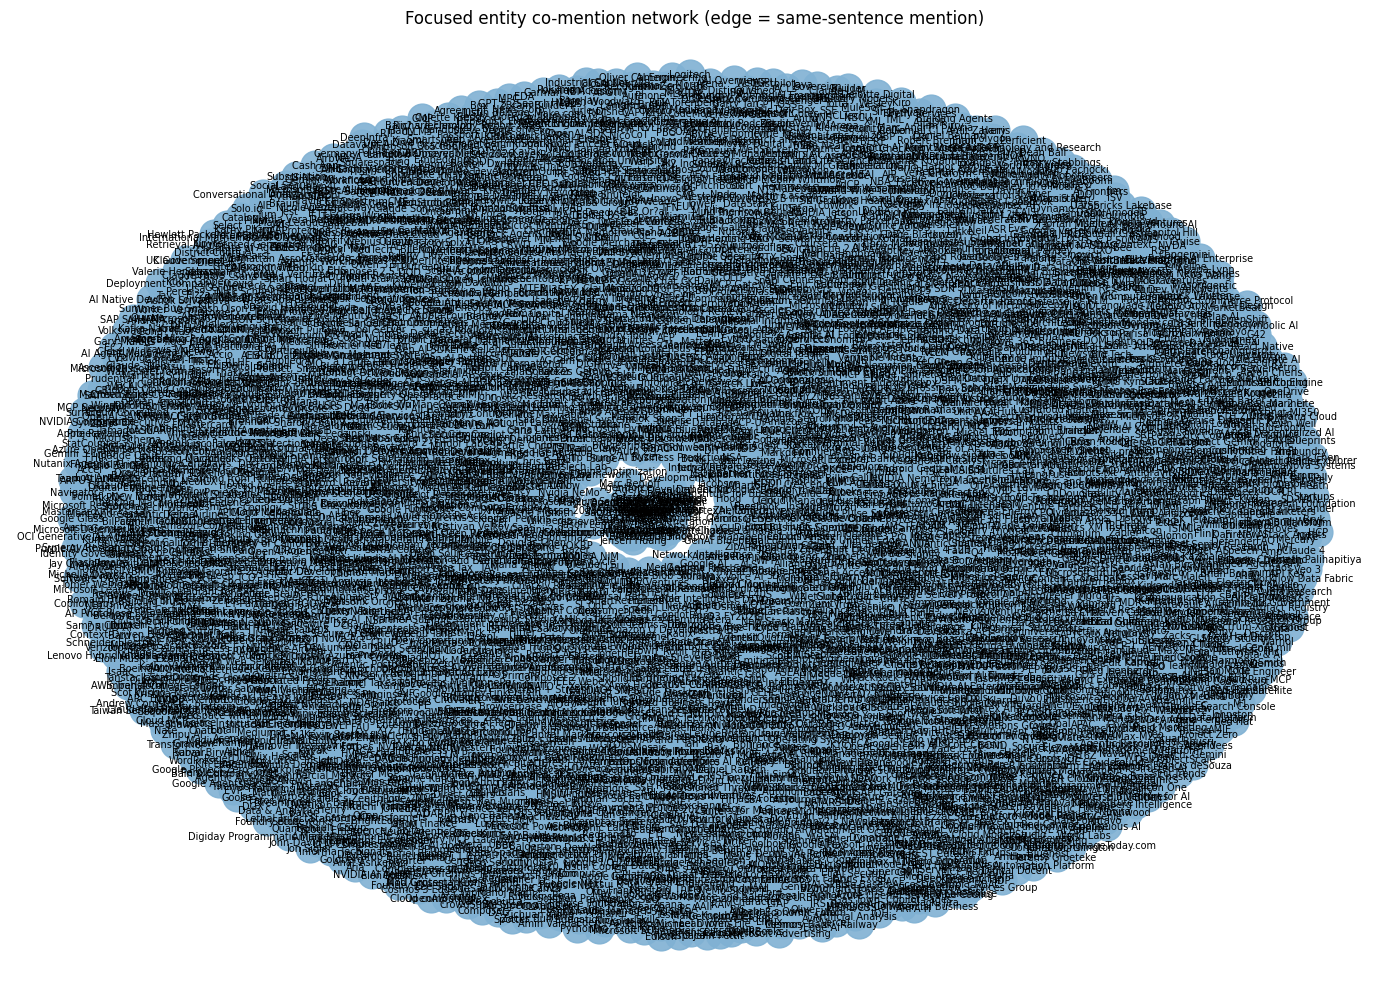

Interpretation: high degree identifies entities linked to many other extracted entities in these articles; it is not a measure of real-world importance or verified collaboration.


In [21]:
graph = nx.Graph()
if not entities.empty:
    node_summary = entities.groupby("entity_id").agg(
        label=("canonical_name", "first"), entity_type=("entity_type", "first"),
        mention_count=("entity_id", "size"), source_article_count=("article_id", "nunique"),
    )
    for identifier, row in node_summary.iterrows():
        graph.add_node(identifier, label=row["label"], entity_type=row["entity_type"],
                       mention_count=int(row["mention_count"]), source_article_count=int(row["source_article_count"]))
if not relations.empty:
    for (subject_id, object_id), group in relations.groupby(["subject_id", "object_id"], sort=False):
        graph.add_edge(
            subject_id, object_id, predicate="MENTIONED_WITH", relation_kind="cooccurrence",
            support_count=int(group["article_id"].nunique()), article_ids=json.dumps(sorted(group["article_id"].unique().tolist())),
            evidence_examples=json.dumps(group["evidence_text"].drop_duplicates().head(3).tolist(), ensure_ascii=False),
            extraction_method="same_sentence_entity_cooccurrence",
        )
if not set(relations["subject_id"].unique()).union(relations["object_id"].unique()).issubset(graph.nodes) if not relations.empty else False:
    raise ValueError("Graph edge references an entity absent from the node table.")
components = list(nx.connected_components(nx.Graph(graph))) if graph.number_of_nodes() else []
degree_centrality = nx.degree_centrality(nx.Graph(graph)) if graph.number_of_nodes() > 1 else {node: 0.0 for node in graph.nodes}
graph_summary = pd.DataFrame([{
    "nodes": graph.number_of_nodes(), "article_level_edges": graph.number_of_edges(),
    "connected_components_including_isolates": len(components),
    "isolated_nodes": sum(1 for _, degree in graph.degree() if degree == 0),
    "graph_type": "undirected Graph", "edge_semantics": "same-sentence article co-occurrence; not factual relation",
}])
display(graph_summary)
if graph.number_of_nodes():
    centrality_rows = sorted(degree_centrality.items(), key=lambda item: item[1], reverse=True)[:20]
    centrality = pd.DataFrame([{"entity_id": node, "label": graph.nodes[node]["label"],
                                "entity_type": graph.nodes[node]["entity_type"], "degree_centrality": value,
                                "mention_count": graph.nodes[node]["mention_count"]} for node, value in centrality_rows])
    display(centrality)
    core_ids = [node for node, _ in centrality_rows[:12]]
    neighborhood = set(core_ids)
    for node in core_ids:
        neighborhood.update(graph.neighbors(node))
    view_graph = graph.subgraph(neighborhood).copy()
    if view_graph.number_of_edges() > 160:
        keep_edges = sorted(view_graph.edges(data=True), key=lambda edge: edge[2].get("support_count", 1), reverse=True)[:160]
        focused = nx.Graph()
        focused.add_nodes_from(view_graph.nodes(data=True))
        focused.add_edges_from(keep_edges)
        view_graph = focused
    plt.figure(figsize=(14, 10))
    positions = nx.spring_layout(nx.Graph(view_graph), seed=SEED, k=0.8)
    labels = {node: graph.nodes[node]["label"].encode("ascii", "replace").decode("ascii") for node in view_graph.nodes}
    nx.draw_networkx_nodes(view_graph, positions, node_size=430, node_color="#80b1d3", alpha=.9)
    nx.draw_networkx_edges(view_graph, positions, alpha=.22, width=.7)
    nx.draw_networkx_labels(view_graph, positions, labels=labels, font_size=7)
    plt.title("Focused entity co-mention network (edge = same-sentence mention)")
    plt.axis("off")
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / "focused_knowledge_graph.png", dpi=180)
    plt.show()
    print("Interpretation: high degree identifies entities linked to many other extracted entities in these articles; it is not a measure of real-world importance or verified collaboration.")

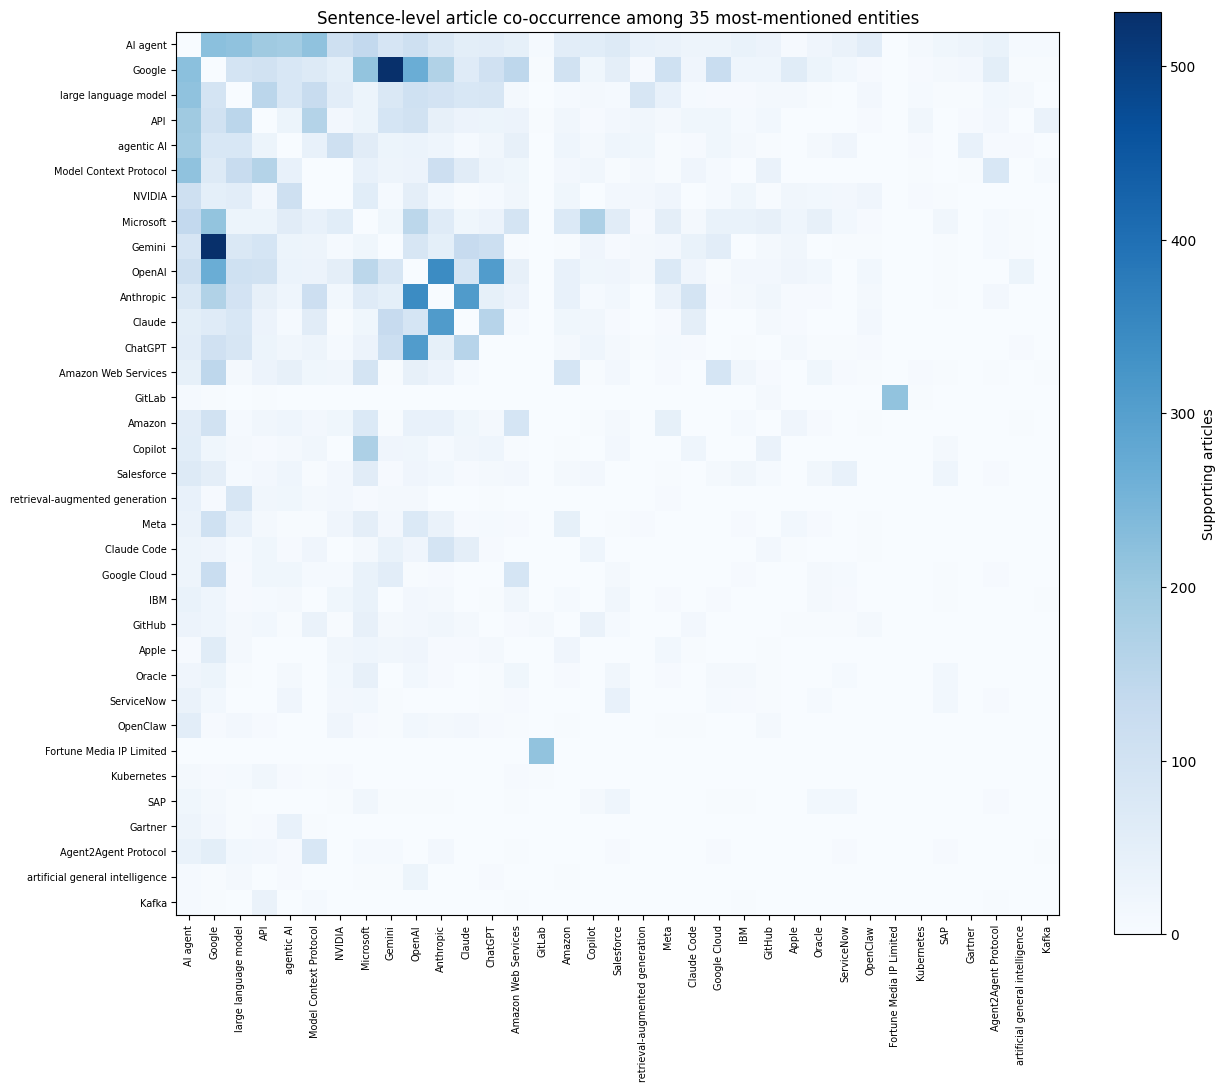

Co-occurrence matrix: 35 x 35; cells count distinct supporting articles from the undirected MENTIONED_WITH graph.


In [22]:
cooccurrence_top_ids = (entities.groupby("entity_id").size().sort_values(ascending=False).head(35).index.tolist())
cooccurrence_labels = {identifier: graph.nodes[identifier]["label"] for identifier in cooccurrence_top_ids}
cooccurrence_matrix = pd.DataFrame(0, index=cooccurrence_top_ids, columns=cooccurrence_top_ids, dtype=np.int64)
for source_id, target_id, attrs in graph.edges(data=True):
    if source_id in cooccurrence_matrix.index and target_id in cooccurrence_matrix.columns:
        support = int(attrs["support_count"])
        cooccurrence_matrix.loc[source_id, target_id] = support
        cooccurrence_matrix.loc[target_id, source_id] = support
cooccurrence_matrix.index.name = "entity_id"
cooccurrence_matrix.to_csv(TABLE_DIR / "entity_cooccurrence_matrix.csv")
fig, ax = plt.subplots(figsize=(13, 11))
image = ax.imshow(cooccurrence_matrix.to_numpy(), cmap="Blues", interpolation="nearest")
labels = [cooccurrence_labels[identifier] for identifier in cooccurrence_top_ids]
ax.set_xticks(range(len(labels)), labels=labels, rotation=90, fontsize=7)
ax.set_yticks(range(len(labels)), labels=labels, fontsize=7)
ax.set_title("Sentence-level article co-occurrence among 35 most-mentioned entities")
fig.colorbar(image, ax=ax, label="Supporting articles")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "entity_cooccurrence_matrix.png", dpi=170)
plt.show()
print(f"Co-occurrence matrix: {len(cooccurrence_matrix)} x {len(cooccurrence_matrix.columns)}; cells count distinct supporting articles from the undirected MENTIONED_WITH graph.")

Publisher-dominated entities (>= 90% of their articles from one publisher, >= 30 articles): 38 of 250 entities with >= 30 articles; 17 of the 100 most-mentioned.


,canonical_name,entity_type,articles,top_publisher,top_publisher_share
27,Fortune Media IP Limited,ORGANIZATION,214,builtin,1.000
31,SaaStr,ORGANIZATION,165,saastr,0.964
33,Jason Lemkin,PERSON,162,saastr,0.957
47,VentureBeat,ORGANIZATION,121,venturebeat,0.967
56,Microsoft Edge,ORGANIZATION,103,learn.microsoft,0.961
58,TrueFoundry,ORGANIZATION,99,truefoundry,0.949
60,Gartner Hype Cycle,ORGANIZATION,96,truefoundry,0.979
63,MCPs & Agents,ORGANIZATION,94,truefoundry,1.000
64,VAR & VAD,ORGANIZATION,94,truefoundry,1.000
66,ERP/GL,ORGANIZATION,91,workday,1.000


,layer,nodes,edges,status
0,Entity inventory (all normalized entity IDs; n...,8183,NaN,extracted entities (unvalidated NER + lexicon)
1,Co-occurrence graph: nodes with >=1 co-occurre...,7291,31817.0,article-level same-sentence co-mentions; not r...
2,Co-occurrence graph: isolated nodes,892,0.0,entity never shares a sentence with another ex...
3,Directed semantic candidates: nodes with >=1 c...,235,496.0,unreviewed lexical-template candidates
4,Directed semantic candidates: isolated nodes (...,7948,0.0,no candidate extracted
5,Human-validated relations,0,0.0,none: no human review performed


277 of 277 distinct candidate entity pairs are also co-occurrence edges (a candidate is a same-sentence pair with a relation cue).


,min_supporting_articles,nodes_with_edges,edges,density,connected_components,largest_component_share_of_nodes,average_clustering,top10_jaccard_vs_threshold_1
0,1,7291,31817,0.0012,109,0.9665,0.5052,1.0000
1,2,3729,8360,0.0012,277,0.8166,0.4006,1.0000
2,3,1557,3454,0.0029,123,0.8022,0.3916,1.0000
3,5,680,1529,0.0066,42,0.8529,0.3746,1.0000
4,10,267,583,0.0164,19,0.8390,0.3901,0.8182
5,20,117,252,0.0371,10,0.8376,0.3593,0.8182


...

Core co-occurrence graph (>= 5 supporting articles): 680 nodes, 1,529 edges, average clustering 0.375, transitivity 0.147.


,entity_id,label,entity_type,degree,weighted_degree_supporting_articles,pagerank_weighted,clustering_coefficient,betweenness_approx_k300,mention_count,source_article_count,top_publisher,top_publisher_share,publisher_dominated
0,organization:google,Google,ORGANIZATION,159,4327,0.0631,0.0459,0.1863,6441,2061,cloud.google,0.1557,False
1,ai_technology:ai-agent,AI agent,AI_TECHNOLOGY,135,3246,0.0461,0.0663,0.1558,9893,4459,dev,0.0895,False
2,organization:nvidia,NVIDIA,ORGANIZATION,115,1809,0.0391,0.0452,0.1683,3576,756,blogs.nvidia,0.2394,False
3,organization:microsoft,Microsoft,ORGANIZATION,102,2266,0.0349,0.0870,0.1205,3287,1077,crn,0.1300,False
4,ai_model:gemini,Gemini,AI_MODEL,89,2175,0.0299,0.0937,0.0516,3119,980,cloud.google,0.2163,False
5,organization:openai,OpenAI,ORGANIZATION,80,2686,0.0359,0.1307,0.0642,2924,1267,thenewstack,0.0750,False
6,ai_technology:api,API,AI_TECHNOLOGY,72,1564,0.0220,0.1416,0.0587,5153,1721,dev,0.1371,False
7,ai_technology:large-language-model,large language model,AI_TECHNOLOGY,61,1960,0.0248,0.2071,0.0286,5790,2261,thenewstack,0.0862,False
8,organization:anthropic,Anthropic,ORGANIZATION,57,1900,0.0244,0.2231,0.0404,1777,881,thenewstack,0.1135,False
9,ai_technology:agentic-ai,agentic AI,AI_TECHNOLOGY,52,1143,0.0165,0.2187,0.0434,4068,1887,crn,0.0790,False


Window sizes (selected articles): first 1,439 (2024-09..2025-02), last 4,890 (2026-03..2026-08); only pairs/entities with >= 15 supporting articles in the last window are ranked.
Excluded from the primary ranking as publisher-dominated: 12 of 142 pairs and 21 of 229 entities; 6 of the unfiltered top-10 pairs were publisher-dominated.


,pair,support_first,support_last,rate_first_per_1000_articles,rate_last_per_1000_articles,rate_change_per_1000_articles
0,AI agent + Model Context Protocol,0,124,0.00,25.36,25.36
1,API + Model Context Protocol,1,89,0.69,18.20,17.51
2,AI agent + API,8,95,5.56,19.43,13.87
3,Anthropic + OpenAI,29,164,20.15,33.54,13.38
4,Claude Code + Anthropic,1,62,0.69,12.68,11.98
5,large language model + Model Context Protocol,1,56,0.69,11.45,10.76
6,API + Google,4,61,2.78,12.47,9.69
7,Claude + ChatGPT,11,84,7.64,17.18,9.53
8,AI agent + OpenClaw,0,44,0.00,9.00,9.00
9,Gemini + Google,55,230,38.22,47.03,8.81


,entity,support_first,support_last,rate_first_per_1000_articles,rate_last_per_1000_articles,rate_change_per_1000_articles
0,AI agent,448,1987,311.33,406.34,95.01
1,Model Context Protocol,1,457,0.69,93.46,92.76
2,API,140,852,97.29,174.23,76.94
3,Claude,51,460,35.44,94.07,58.63
4,Google,176,866,122.31,177.10,54.79
5,Gemini,75,503,52.12,102.86,50.74
6,Claude Code,3,247,2.08,50.51,48.43
7,GitLab,2,229,1.39,46.83,45.44
8,Anthropic,72,430,50.03,87.93,37.90
9,GitHub,16,202,11.12,41.31,30.19


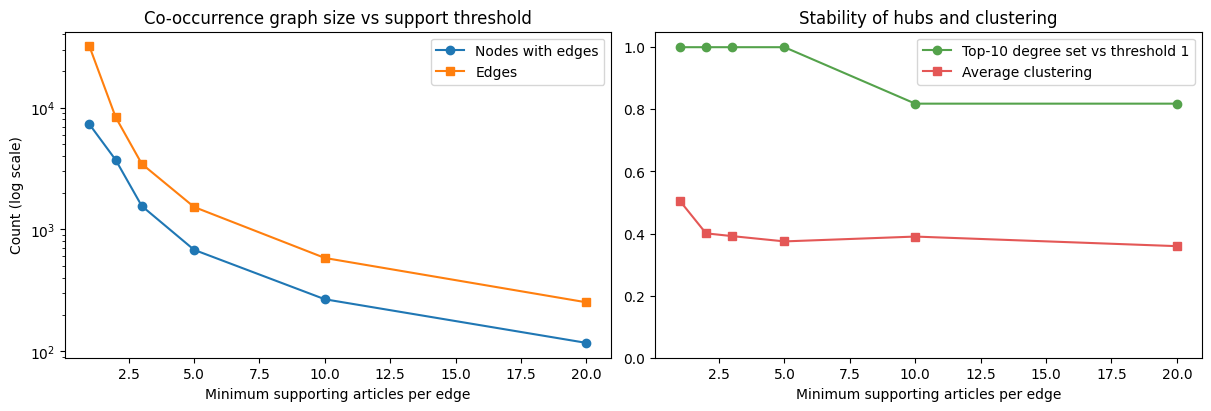

Interpretation: thresholds trade coverage against noise; they change which entities look central, so centrality rankings are reported with their threshold. High degree means frequent same-sentence co-mention with many entities in this corpus, not real-world importance, partnership, or verified relations. The directed candidates remain unreviewed and are not part of these metrics.


In [23]:
label_of = {node: data["label"] for node, data in graph.nodes(data=True)}
edge_support = [(u, v, int(data["support_count"])) for u, v, data in graph.edges(data=True)]

# Publisher dominance per entity: an entity whose articles come almost entirely from one publisher is often site furniture,
# a publisher self-reference or a vendor blog theme rather than a topic covered across outlets. It is flagged, not removed.
PUBLISHER_DOMINANCE_SHARE, PUBLISHER_DOMINANCE_MIN_ARTICLES = 0.90, 30
entity_sources = (entities.assign(source=entities["article_id"].map(agentic.set_index("article_id")["source"]))
                  .drop_duplicates(["entity_id", "article_id"]))
entity_publisher_concentration = entity_sources.groupby("entity_id").agg(
    articles=("article_id", "nunique"), publishers=("source", "nunique"),
    top_publisher=("source", lambda sources: sources.value_counts().index[0]),
    top_publisher_share=("source", lambda sources: float(sources.value_counts(normalize=True).iloc[0]))).reset_index()
entity_publisher_concentration["canonical_name"] = entity_publisher_concentration["entity_id"].map(label_of)
entity_publisher_concentration["entity_type"] = entity_publisher_concentration["entity_id"].map(lambda node: graph.nodes[node]["entity_type"])
entity_publisher_concentration["publisher_dominated"] = (entity_publisher_concentration["top_publisher_share"].ge(PUBLISHER_DOMINANCE_SHARE)
                                                         & entity_publisher_concentration["articles"].ge(PUBLISHER_DOMINANCE_MIN_ARTICLES))
entity_publisher_concentration = entity_publisher_concentration.sort_values(["articles", "entity_id"], ascending=[False, True]).reset_index(drop=True)
entity_publisher_concentration.to_csv(TABLE_DIR / "entity_publisher_concentration.csv", index=False)
print(f"Publisher-dominated entities (>= {PUBLISHER_DOMINANCE_SHARE:.0%} of their articles from one publisher, >= {PUBLISHER_DOMINANCE_MIN_ARTICLES} articles): "
      f"{int(entity_publisher_concentration['publisher_dominated'].sum()):,} of {int(entity_publisher_concentration['articles'].ge(PUBLISHER_DOMINANCE_MIN_ARTICLES).sum()):,} entities with >= {PUBLISHER_DOMINANCE_MIN_ARTICLES} articles; "
      f"{int(entity_publisher_concentration.head(100)['publisher_dominated'].sum())} of the 100 most-mentioned.")
display(entity_publisher_concentration[entity_publisher_concentration["publisher_dominated"]].head(10)[["canonical_name", "entity_type", "articles", "top_publisher", "top_publisher_share"]].round(3))

# 1. Layers: what each graph population actually is (inventory vs connected vs candidate claims vs validated).
connected_nodes = {node for node, degree in graph.degree() if degree > 0}
claim_nodes = set(explicit_claims["subject_id"]) | set(explicit_claims["object_id"]) if not explicit_claims.empty else set()
claim_pairs = {frozenset((row.subject_id, row.object_id)) for row in explicit_claims.itertuples(index=False)}
claim_pairs_also_cooccurring = sum(graph.has_edge(*tuple(pair)) for pair in claim_pairs)
graph_layers = pd.DataFrame([
    {"layer": "Entity inventory (all normalized entity IDs; nodes of both GraphML files)", "nodes": graph.number_of_nodes(), "edges": None, "status": "extracted entities (unvalidated NER + lexicon)"},
    {"layer": "Co-occurrence graph: nodes with >=1 co-occurrence edge", "nodes": len(connected_nodes), "edges": graph.number_of_edges(), "status": "article-level same-sentence co-mentions; not relations"},
    {"layer": "Co-occurrence graph: isolated nodes", "nodes": graph.number_of_nodes() - len(connected_nodes), "edges": 0, "status": "entity never shares a sentence with another extracted entity"},
    {"layer": "Directed semantic candidates: nodes with >=1 candidate edge", "nodes": len(claim_nodes), "edges": len(explicit_claims), "status": "unreviewed lexical-template candidates"},
    {"layer": "Directed semantic candidates: isolated nodes (inventory entities with no candidate)", "nodes": graph.number_of_nodes() - len(claim_nodes), "edges": 0, "status": "no candidate extracted"},
    {"layer": "Human-validated relations", "nodes": 0, "edges": 0, "status": "none: no human review performed"},
])
graph_layers.to_csv(TABLE_DIR / "graph_layers_summary.csv", index=False)
display(graph_layers)
print(f"{claim_pairs_also_cooccurring:,} of {len(claim_pairs):,} distinct candidate entity pairs are also co-occurrence edges (a candidate is a same-sentence pair with a relation cue).")

# 2. Threshold sensitivity of the co-occurrence graph (minimum number of supporting articles per edge).
THRESHOLDS = (1, 2, 3, 5, 10, 20)


def graph_at_threshold(threshold: int) -> nx.Graph:
    sub = nx.Graph()
    sub.add_weighted_edges_from(((u, v, s) for u, v, s in edge_support if s >= threshold), weight="support_count")
    return sub


sensitivity_rows, top_sets = [], {}
for threshold in THRESHOLDS:
    sub = graph_at_threshold(threshold)
    components = list(nx.connected_components(sub))
    centrality = nx.degree_centrality(sub)
    top10 = [node for node, _ in sorted(centrality.items(), key=lambda item: (-item[1], item[0]))[:10]]
    top_sets[threshold] = set(top10)
    sensitivity_rows.append({
        "min_supporting_articles": threshold, "nodes_with_edges": sub.number_of_nodes(), "edges": sub.number_of_edges(),
        "density": nx.density(sub), "connected_components": len(components),
        "largest_component_share_of_nodes": max((len(c) for c in components), default=0) / max(sub.number_of_nodes(), 1),
        "average_clustering": nx.average_clustering(sub) if sub.number_of_nodes() else float("nan"),
        "top10_degree_entities": "; ".join(label_of[node] for node in top10),
    })
graph_sensitivity = pd.DataFrame(sensitivity_rows)
graph_sensitivity["top10_jaccard_vs_threshold_1"] = [len(top_sets[t] & top_sets[1]) / len(top_sets[t] | top_sets[1]) for t in THRESHOLDS]
graph_sensitivity.to_csv(TABLE_DIR / "graph_threshold_sensitivity.csv", index=False)
display(graph_sensitivity.drop(columns="top10_degree_entities").round(4))
for row in graph_sensitivity.itertuples(index=False):
    print(f"  threshold >= {row.min_supporting_articles:>2}: top-10 by degree = {row.top10_degree_entities}")

# 3. Centrality and clustering on the core graph (predeclared threshold: >= 5 supporting articles).
CORE_THRESHOLD = 5
core_graph = graph_at_threshold(CORE_THRESHOLD)
core_pagerank = nx.pagerank(core_graph, weight="support_count")
core_clustering = nx.clustering(core_graph)
core_betweenness = nx.betweenness_centrality(core_graph, k=min(300, core_graph.number_of_nodes()), seed=SEED)
graph_node_metrics = pd.DataFrame({
    "entity_id": list(core_graph.nodes),
    "label": [label_of[node] for node in core_graph.nodes],
    "entity_type": [graph.nodes[node]["entity_type"] for node in core_graph.nodes],
    "degree": [core_graph.degree(node) for node in core_graph.nodes],
    "weighted_degree_supporting_articles": [core_graph.degree(node, weight="support_count") for node in core_graph.nodes],
    "pagerank_weighted": [core_pagerank[node] for node in core_graph.nodes],
    "clustering_coefficient": [core_clustering[node] for node in core_graph.nodes],
    "betweenness_approx_k300": [core_betweenness[node] for node in core_graph.nodes],
    "mention_count": [graph.nodes[node]["mention_count"] for node in core_graph.nodes],
    "source_article_count": [graph.nodes[node]["source_article_count"] for node in core_graph.nodes],
}).merge(entity_publisher_concentration[["entity_id", "top_publisher", "top_publisher_share", "publisher_dominated"]], on="entity_id", how="left"
).sort_values(["degree", "entity_id"], ascending=[False, True]).reset_index(drop=True)
graph_node_metrics.to_csv(TABLE_DIR / "graph_node_metrics.csv", index=False)
print(f"Core co-occurrence graph (>= {CORE_THRESHOLD} supporting articles): {core_graph.number_of_nodes():,} nodes, {core_graph.number_of_edges():,} edges, average clustering {nx.average_clustering(core_graph):.3f}, transitivity {nx.transitivity(core_graph):.3f}.")
display(graph_node_metrics.head(15).round(4))

# 4. Emerging entities and co-mention pairs: first vs last six months, normalized by each window's selected-article volume
#    (so overall growth of coverage is not mistaken for emergence). These are changes in how often entities/pairs are reported,
#    not new real-world relationships.
window_article_ids = {name: set(agentic.loc[agentic["month"].isin(window), "article_id"]) for name, window in (("first", first_window), ("last", last_window))}
window_sizes = {name: len(ids) for name, ids in window_article_ids.items()}
MIN_LAST_WINDOW_SUPPORT = 15


def windowed_support(frame: pd.DataFrame, keys: list[str]) -> pd.DataFrame:
    counts = {name: frame[frame["article_id"].isin(ids)].groupby(keys)["article_id"].nunique() for name, ids in window_article_ids.items()}
    table = pd.DataFrame({"support_first": counts["first"], "support_last": counts["last"]}).fillna(0).astype(int)
    table["rate_first_per_1000_articles"] = 1000 * table["support_first"] / window_sizes["first"]
    table["rate_last_per_1000_articles"] = 1000 * table["support_last"] / window_sizes["last"]
    table["rate_change_per_1000_articles"] = table["rate_last_per_1000_articles"] - table["rate_first_per_1000_articles"]
    return table[table["support_last"].ge(MIN_LAST_WINDOW_SUPPORT)].sort_values("rate_change_per_1000_articles", ascending=False)


emerging_pairs = windowed_support(relations, ["subject_id", "object_id"]).reset_index()
emerging_pairs.insert(0, "pair", [f"{label_of[a]} + {label_of[b]}" for a, b in zip(emerging_pairs["subject_id"], emerging_pairs["object_id"])])
emerging_entities = windowed_support(entities, ["entity_id"]).reset_index()
emerging_entities.insert(0, "entity", emerging_entities["entity_id"].map(label_of))
# Publisher-dominated entities (see above) produce spurious "emergence" when one publisher starts or stops a recurring template, so the
# primary ranking excludes them; the unfiltered tables are exported too, with the flag, for transparency.
dominated_ids = set(entity_publisher_concentration.loc[entity_publisher_concentration["publisher_dominated"], "entity_id"])
emerging_pairs["involves_publisher_dominated_entity"] = emerging_pairs["subject_id"].isin(dominated_ids) | emerging_pairs["object_id"].isin(dominated_ids)
emerging_entities["publisher_dominated"] = emerging_entities["entity_id"].isin(dominated_ids)
emerging_pairs_ranked = emerging_pairs[~emerging_pairs["involves_publisher_dominated_entity"]].reset_index(drop=True)
emerging_entities_ranked = emerging_entities[~emerging_entities["publisher_dominated"]].reset_index(drop=True)
emerging_pairs_ranked.head(50).to_csv(TABLE_DIR / "graph_emerging_pairs.csv", index=False)
emerging_entities_ranked.head(50).to_csv(TABLE_DIR / "graph_emerging_entities.csv", index=False)
emerging_pairs.head(50).to_csv(TABLE_DIR / "graph_emerging_pairs_unfiltered.csv", index=False)
emerging_entities.head(50).to_csv(TABLE_DIR / "graph_emerging_entities_unfiltered.csv", index=False)
print(f"Window sizes (selected articles): first {window_sizes['first']:,} ({first_window[0]}..{first_window[-1]}), last {window_sizes['last']:,} ({last_window[0]}..{last_window[-1]}); only pairs/entities with >= {MIN_LAST_WINDOW_SUPPORT} supporting articles in the last window are ranked.")
print(f"Excluded from the primary ranking as publisher-dominated: {int(emerging_pairs['involves_publisher_dominated_entity'].sum())} of {len(emerging_pairs)} pairs and {int(emerging_entities['publisher_dominated'].sum())} of {len(emerging_entities)} entities; "
      f"{int(emerging_pairs.head(10)['involves_publisher_dominated_entity'].sum())} of the unfiltered top-10 pairs were publisher-dominated.")
display(emerging_pairs_ranked.head(10)[["pair", "support_first", "support_last", "rate_first_per_1000_articles", "rate_last_per_1000_articles", "rate_change_per_1000_articles"]].round(2))
display(emerging_entities_ranked.head(10)[["entity", "support_first", "support_last", "rate_first_per_1000_articles", "rate_last_per_1000_articles", "rate_change_per_1000_articles"]].round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].plot(graph_sensitivity["min_supporting_articles"], graph_sensitivity["nodes_with_edges"], marker="o", label="Nodes with edges")
axes[0].plot(graph_sensitivity["min_supporting_articles"], graph_sensitivity["edges"], marker="s", label="Edges")
axes[0].set(title="Co-occurrence graph size vs support threshold", xlabel="Minimum supporting articles per edge", ylabel="Count (log scale)", yscale="log")
axes[0].legend()
axes[1].plot(graph_sensitivity["min_supporting_articles"], graph_sensitivity["top10_jaccard_vs_threshold_1"], marker="o", color="#54a24b", label="Top-10 degree set vs threshold 1")
axes[1].plot(graph_sensitivity["min_supporting_articles"], graph_sensitivity["average_clustering"], marker="s", color="#e45756", label="Average clustering")
axes[1].set(title="Stability of hubs and clustering", xlabel="Minimum supporting articles per edge", ylim=(0, 1.05))
axes[1].legend()
fig.savefig(FIGURE_DIR / "graph_threshold_sensitivity.png", dpi=160)
plt.show()
print("Interpretation: thresholds trade coverage against noise; they change which entities look central, so centrality rankings are reported with their threshold. High degree means frequent same-sentence co-mention with many entities in this corpus, not real-world importance, partnership, or verified relations. The directed candidates remain unreviewed and are not part of these metrics.")

## 9. Evaluation and validation

**What is evaluated here.** Executable checks cover article/entity/claim schemas, entity-name normalization invariants, exact entity and evidence offsets, predicate domain/range constraints, source provenance, graph direction and endpoints, topic-stability and temporal-denominator outputs, and artifact reloads. They prove internal consistency, not linguistic correctness.

**What is *not* evaluated: human-labelled quality.** Fixed-seed annotation worksheets are provided for article selection (`stage1_review.csv`, 40 rows), entity spans and normalization (`entity_review.csv`, 56 rows) and directed relation candidates (`relation_review.csv`, 51 rows). They are intentionally unlabelled and **no precision, recall, F1 or agreement figure is reported**. Reviewing them is an *optional* quality improvement: the professor's brief for Stage 1 does not require human annotation. Without it, every article-selection decision, entity and relation candidate is an unvalidated model output, and this limitation applies to all findings below. The step-by-step review procedure, label vocabularies and the exact metric formulas are in `outputs/evaluations/REVIEW_GUIDE.md`.

**Label vocabularies (summary).** `stage1_review.csv`: `relevant`, `not_relevant`, `uncertain`. `entity_review.csv`: `correct`, `wrong_span`, `wrong_type`, `wrong_link`, `uncertain` (plus gold type/name where applicable). `relation_review.csv`: `supported`, `unsupported`, `wrong_direction`, `wrong_predicate`, `uncertain` (plus gold subject/object/predicate and event time when the source supports them). Candidate precision is computed only from completed labels; recall cannot be estimated from candidate-only samples without a separately reviewed negative/source sample. Event time stays null unless an annotator supplies evidence; the publication date is never substituted for it.

In [24]:
def adopt_human_labels(generated: pd.DataFrame, filename: str) -> tuple[pd.DataFrame, int]:
    """Keep a worksheet the reviewer has started labelling as the source of truth (it is never overwritten by a re-run)."""
    path = EVALUATION_DIR / filename
    if not path.is_file():
        return generated, 0
    existing = pd.read_csv(path, keep_default_na=False)
    labelled = int(existing["manual_label"].astype(str).str.strip().ne("").sum()) if "manual_label" in existing.columns else 0
    return (existing, labelled) if labelled else (generated, 0)


selection_review, n_selection_labelled = adopt_human_labels(selection_review, "stage1_review.csv")
entity_review, n_entity_labelled = adopt_human_labels(entity_review, "entity_review.csv")
relation_review, n_relation_labelled = adopt_human_labels(relation_review, "relation_review.csv")
human_label_counts = {"selection": n_selection_labelled, "entity": n_entity_labelled, "relation": n_relation_labelled}
print("Human-labelled worksheet rows found:", human_label_counts)
if not any(human_label_counts.values()):
    print("No human labels exist: all worksheets are the freshly generated, unlabelled samples, and no precision/recall is reported.")
else:
    print("Existing labelled worksheets are used as the source of truth and are not overwritten; metrics below are computed only from those labels.")

Human-labelled worksheet rows found: {'selection': 0, 'entity': 0, 'relation': 0}
No human labels exist: all worksheets are the freshly generated, unlabelled samples, and no precision/recall is reported.


In [25]:
evaluation_checks = []
def record_check(name: str, passed: bool, detail: str) -> None:
    evaluation_checks.append({"check": name, "status": "Passed" if passed else "Failed", "detail": detail})


record_check("unique cleaned article IDs", articles["article_id"].is_unique, f"{len(articles):,} rows")
record_check("unique selected article IDs", agentic["article_id"].is_unique, f"{len(agentic):,} rows")
record_check("selected rows satisfy frozen rule", bool(agentic["is_agentic_web"].all()), SUBSET_RULE_VERSION)
record_check("entity article provenance", bool(entities["article_id"].isin(set(agentic["article_id"])).all()) if not entities.empty else True,
             f"{entities['article_id'].nunique() if not entities.empty else 0:,} articles represented")
record_check("generic spaCy labels filtered", not bool((entities["extraction_method"].eq("spacy_en_core_web_sm") & entities["canonical_name"].str.casefold().isin(generic_ner_names)).any()) if not entities.empty else True,
             "Generic AI/ML terms are not retained as spaCy people or organizations")
record_check("entity offsets valid for truncated NER input", bool((entities["start_char"] >= 0).all() and (entities["end_char"] > entities["start_char"]).all()) if not entities.empty else True,
             f"{len(entities):,} mention spans")
record_check("relation predicates explicitly co-occurrence", bool(relations["predicate"].eq("MENTIONED_WITH").all() and relations["relation_kind"].eq("cooccurrence").all()) if not relations.empty else True,
             f"{len(relations):,} article-level relation records")
record_check("relation evidence and article provenance present", bool(relations["evidence_text"].notna().all() and relations["article_id"].isin(set(agentic["article_id"])).all()) if not relations.empty else True,
             "Every edge evidence sentence is linked to a selected article")
record_check("topic assignments in configured range", bool(agentic["topic_id"].between(0, N_TOPICS - 1).all()), f"NMF K={N_TOPICS}")
record_check("typed relation domain/range constraints", bool(all(
    row.subject_type in RELATION_DOMAIN_RANGE[row.predicate][0]
    and row.object_type in RELATION_DOMAIN_RANGE[row.predicate][1]
    for row in explicit_claims.itertuples(index=False))), f"{len(explicit_claims):,} directed candidates")
record_check("claim source/date/evidence provenance", bool(
    explicit_claims[["source_id", "source_domain", "source_url", "published_at", "evidence_text", "evidence_sentence_id"]].notna().all().all()
    and explicit_claims["article_id"].isin(set(agentic["article_id"].astype(str))).all()) if not explicit_claims.empty else True,
    "Claims link to source article IDs, publication dates, URLs, and exact sentence evidence")
record_check("claim character spans align with evidence", bool(all(
    ner_input_by_article[row.article_id][row.evidence_start_char:row.evidence_end_char] == row.evidence_text
    and row.evidence_start_char <= row.relation_cue_start_char < row.relation_cue_end_char <= row.evidence_end_char
    for row in explicit_claims.itertuples(index=False))), f"{len(explicit_claims):,} evidence spans")
record_check("event time is explicitly unextracted", bool(explicit_claims["event_time"].isna().all()) if not explicit_claims.empty else True,
    "Publication time is preserved; event time is not inferred")
record_check("semantic claim graph preserves direction and provenance", semantic_graph.is_directed()
    and semantic_graph.number_of_edges() == len(explicit_claims), f"{semantic_graph.number_of_edges():,} directed claim edges")
record_check("entity co-occurrence matrix is symmetric with zero diagonal",
    cooccurrence_matrix.shape[0] == cooccurrence_matrix.shape[1]
    and np.array_equal(cooccurrence_matrix.to_numpy(), cooccurrence_matrix.to_numpy().T)
    and bool(np.all(np.diag(cooccurrence_matrix.to_numpy()) == 0)),
    f"{cooccurrence_matrix.shape[0]} top-mentioned entities")
evaluation_table = pd.DataFrame(evaluation_checks)
display(evaluation_table)
if evaluation_table["status"].eq("Failed").any():
    raise AssertionError("One or more Stage 1 structural/provenance checks failed.")

reviewed = selection_review[selection_review["manual_label"].isin(["relevant", "not_relevant", "uncertain"])].copy()
if reviewed.empty:
    selection_metrics = {"status": "Needs review", "n_reviewed": 0,
                         "note": "No manual labels were supplied; precision/recall are not reported."}
else:
    scored = reviewed[reviewed["manual_label"].isin(["relevant", "not_relevant"])].copy()
    # The worksheet is a stratified sample (<= 8 rows per stratum), so pooled sample precision/recall would be biased.
    # Estimates are therefore weighted by each stratum's population size, with Wilson 95% intervals per stratum.

    def wilson_interval(successes: int, trials: int, z: float = 1.96) -> tuple[float, float]:
        if trials == 0:
            return (float("nan"), float("nan"))
        proportion = successes / trials
        denominator = 1 + z ** 2 / trials
        center = (proportion + z ** 2 / (2 * trials)) / denominator
        half_width = z * np.sqrt(proportion * (1 - proportion) / trials + z ** 2 / (4 * trials ** 2)) / denominator
        return (float(center - half_width), float(center + half_width))

    stratum_rows = []
    for stratum, group in scored.groupby("audit_stratum"):
        relevant_count = int(group["manual_label"].eq("relevant").sum())
        low, high = wilson_interval(relevant_count, len(group))
        stratum_rows.append({"audit_stratum": stratum, "selected_by_rule": bool(group["is_agentic_web_rule"].astype(bool).iloc[0]),
                             "population": int(len(audit_strata[stratum])), "labelled": int(len(group)), "relevant": relevant_count,
                             "relevant_rate": relevant_count / len(group), "wilson95_low": low, "wilson95_high": high})
    selection_strata = pd.DataFrame(stratum_rows)
    selection_metrics = {"status": "Computed from supplied manual labels (stratum-weighted)", "n_reviewed": int(len(scored)),
                         "uncertain_excluded": int(reviewed["manual_label"].eq("uncertain").sum()),
                         "strata_labelled": selection_strata["audit_stratum"].tolist(), "precision": None, "recall": None,
                         "note": "Precision and recall are estimated only when every relevant stratum has at least one labelled row; intervals are wide."}
    selected_strata, missed_strata = selection_strata[selection_strata["selected_by_rule"]], selection_strata[~selection_strata["selected_by_rule"]]
    if len(selected_strata) == 3:
        true_positive_estimate = float((selected_strata["population"] * selected_strata["relevant_rate"]).sum())
        selection_metrics["precision"] = true_positive_estimate / float(selected_strata["population"].sum())
        if len(missed_strata) == 2:
            missed_estimate = float((missed_strata["population"] * missed_strata["relevant_rate"]).sum())
            selection_metrics["recall"] = true_positive_estimate / (true_positive_estimate + missed_estimate)
    display(selection_strata.round(3))
print("Selection evaluation:", selection_metrics)
reviewed_entities = entity_review[entity_review["manual_label"].isin(["correct", "wrong_span", "wrong_type", "wrong_link", "uncertain"])].copy()
entity_review_scored = reviewed_entities[reviewed_entities["manual_label"].ne("uncertain")]
entity_metrics = {"status": "Needs review", "n_reviewed": len(entity_review_scored),
                  "precision": (entity_review_scored["manual_label"].eq("correct").mean() if len(entity_review_scored) else None),
                  "recall": None, "note": "Recall is not estimated from a candidate-only mention sample."}
reviewed_claims = relation_review[relation_review["manual_label"].isin(["supported", "unsupported", "wrong_direction", "wrong_predicate", "uncertain"])].copy()
claim_review_scored = reviewed_claims[reviewed_claims["manual_label"].ne("uncertain")]
relation_metrics = {"status": "Needs review", "n_reviewed": len(claim_review_scored),
                    "precision": (claim_review_scored["manual_label"].eq("supported").mean() if len(claim_review_scored) else None),
                    "recall": None, "note": "No judgments supplied; recall is not estimable from candidate-only review."}
print("Entity candidate evaluation:", entity_metrics)
print("Directed relation candidate evaluation:", relation_metrics)

,check,status,detail
0,unique cleaned article IDs,Passed,"47,443 rows"
1,unique selected article IDs,Passed,"11,867 rows"
2,selected rows satisfy frozen rule,Passed,agentic-web-lexicon-v2
3,entity article provenance,Passed,"11,397 articles represented"
4,generic spaCy labels filtered,Passed,Generic AI/ML terms are not retained as spaCy ...
5,entity offsets valid for truncated NER input,Passed,"137,715 mention spans"
6,relation predicates explicitly co-occurrence,Passed,"64,971 article-level relation records"
7,relation evidence and article provenance present,Passed,Every edge evidence sentence is linked to a se...
8,topic assignments in configured range,Passed,NMF K=3
9,typed relation domain/range constraints,Passed,496 directed candidates


Selection evaluation: {'status': 'Needs review', 'n_reviewed': 0, 'note': 'No manual labels were supplied; precision/recall are not reported.'}
Entity candidate evaluation: {'status': 'Needs review', 'n_reviewed': 0, 'precision': None, 'recall': None, 'note': 'Recall is not estimated from a candidate-only mention sample.'}
Directed relation candidate evaluation: {'status': 'Needs review', 'n_reviewed': 0, 'precision': None, 'recall': None, 'note': 'No judgments supplied; recall is not estimable from candidate-only review.'}


In [26]:
def has_edge_noise(name: str) -> bool:
    """True when a name still carries a leading 'the', a possessive, or trailing punctuation/trademark signs."""
    return bool(re.match(r"^the\s", name, re.IGNORECASE) or re.search(r"['’]s?$|[,;:®™]$", name))


if not entities.empty:
    spacy_derived = entities[entities["extraction_method"].isin([SPACY_METHOD, LEXICON_VARIANT_METHOD])].drop_duplicates("entity_id")
    record_check("spaCy-derived entity names have no leading 'the', possessive or trailing punctuation",
                 not spacy_derived["canonical_name"].map(has_edge_noise).any(), f"{len(spacy_derived):,} spaCy-derived entity IDs")
    spacy_only_mentions_df = entities[entities["extraction_method"].eq(SPACY_METHOD)]
    record_check("one normalized spaCy name maps to exactly one entity ID",
                 bool((spacy_only_mentions_df.groupby(spacy_only_mentions_df["canonical_name"].map(name_key))["entity_id"].nunique() <= 1).all()),
                 f"{spacy_only_mentions_df['entity_id'].nunique():,} spaCy-only IDs")
    record_check("entity spans equal the NER source text (spaCy and lexicon spans)",
                 all(ner_input_by_article[article][start:end] == surface for article, start, end, surface in
                     zip(entities["article_id"], entities["start_char"], entities["end_char"], entities["surface_form"])),
                 f"{len(entities):,} mention spans compared with the exact NER input")
    record_check("distinct products/business units stay distinct (no AWS->Amazon, DeepMind->Google, GitHub Copilot->Copilot merge)",
                 not (((entities["surface_form"].eq("AWS")) & entities["canonical_name"].eq("Amazon"))
                      | (entities["surface_form"].eq("GitHub Copilot") & entities["canonical_name"].eq("Copilot"))
                      | (entities["surface_form"].eq("DeepMind") & entities["canonical_name"].eq("Google"))).any(),
                 "Lexicon keeps parent and product/unit entities separate")
record_check("protected words are not lemmatized in the topic view",
             bool(topic_lemma_map.loc[topic_lemma_map["term"].isin(["data", "metadata", "analytics"]), "changed"].eq(False).all()),
             "e.g. 'data' is not mapped to 'datum'")
record_check("topic stability grid completed with fixed seeds",
             len(topic_stability) == len(STABILITY_GRID) * STABILITY_REPLICATES and topic_stability["seed"].is_unique,
             f"{len(topic_stability)} replicate fits")
record_check("monthly topic counts reconcile with selected-article denominators",
             int(month_table["agentic_articles"].sum()) == len(agentic) and bool(month_table["agentic_articles"].gt(0).all()),
             f"{len(month_table)} months, {len(agentic):,} selected articles")
record_check("graph layers are consistent (claim nodes are inventory nodes; no validated relations)",
             claim_nodes.issubset(set(graph.nodes)) and int(graph_layers.iloc[-1]["edges"]) == 0
             and bool(explicit_claims["validation_status"].eq("unreviewed_candidate").all() if not explicit_claims.empty else True),
             f"{len(claim_nodes):,} entities in candidate claims; all {len(explicit_claims):,} candidates unreviewed")
record_check("emerging pairs are co-occurrence edges with window-normalized rates; publisher-dominated entities excluded from the ranking",
             all(graph.has_edge(a, b) for a, b in zip(emerging_pairs_ranked["subject_id"].head(50), emerging_pairs_ranked["object_id"].head(50)))
             and bool(emerging_pairs_ranked["support_last"].ge(MIN_LAST_WINDOW_SUPPORT).all()) and set(window_sizes) == {"first", "last"}
             and not emerging_pairs_ranked["involves_publisher_dominated_entity"].any() and not emerging_entities_ranked["publisher_dominated"].any(),
             f"{len(emerging_pairs_ranked):,} ranked pairs ({len(emerging_pairs):,} before the exclusion); windows of {window_sizes['first']:,} and {window_sizes['last']:,} selected articles")
record_check("LLM pilot: accepted relations have exact source offsets, an allowed predicate, and name both entities in the evidence",
             (not llm_pilot_ran) or all(
                 pilot_text[str(row.article_id)][int(row.evidence_start_char):int(row.evidence_end_char)] == row.evidence_text
                 and row.predicate in RELATION_DOMAIN_RANGE
                 and row.subject_text.casefold() in row.evidence_text.casefold() and row.object_text.casefold() in row.evidence_text.casefold()
                 for row in llm_accepted.itertuples()),
             f"{len(llm_accepted):,} accepted of {len(llm_relations):,} LLM relation extractions on {len(pilot_ids)} pilot articles")
record_check("LLM pilot: every LLM relation is an unreviewed candidate (no validation claimed)",
             bool(llm_relations["validation_status"].eq("unreviewed_candidate").all()) if len(llm_relations) else True, "validation_status = unreviewed_candidate")
notebook_text = (ROOT / "notebooks" / "stage1_analysis.ipynb").read_text(encoding="utf-8")
exported_llm_text = "".join((TABLE_DIR / name).read_text(encoding="utf-8") for name in ("llm_entity_pilot.csv", "llm_relation_pilot.csv", "llm_pilot_summary.csv", "llm_vs_template_candidates.csv"))
record_check("API key does not appear in the notebook or in exported LLM tables",
             not llm_api_key or (llm_api_key not in notebook_text and llm_api_key not in exported_llm_text), "key never printed, stored or exported")
# Needles are assembled from parts so that this cell's own source cannot satisfy (or violate) the check.
required_phrases = ["sole student " + "contributor", "drafted the code " + "for Stage 1", "Leon " + "Bytyqi"]
forbidden_phrases = ["To be completed by the " + "student group", "was not included in the " + "project files"]
record_check("required statements present: individual contribution and explicit 'drafted the code' AI disclosure; no placeholder or stale text",
             all(phrase in notebook_text for phrase in required_phrases) and not any(phrase in notebook_text for phrase in forbidden_phrases),
             "Checks the saved notebook text, including its markdown")
evaluation_table = pd.DataFrame(evaluation_checks)
display(evaluation_table)
if evaluation_table["status"].eq("Failed").any():
    raise AssertionError("One or more Stage 1 structural/provenance checks failed.")

,check,status,detail
0,unique cleaned article IDs,Passed,"47,443 rows"
1,unique selected article IDs,Passed,"11,867 rows"
2,selected rows satisfy frozen rule,Passed,agentic-web-lexicon-v2
3,entity article provenance,Passed,"11,397 articles represented"
4,generic spaCy labels filtered,Passed,Generic AI/ML terms are not retained as spaCy ...
5,entity offsets valid for truncated NER input,Passed,"137,715 mention spans"
6,relation predicates explicitly co-occurrence,Passed,"64,971 article-level relation records"
7,relation evidence and article provenance present,Passed,Every edge evidence sentence is linked to a se...
8,topic assignments in configured range,Passed,NMF K=3
9,typed relation domain/range constraints,Passed,496 directed candidates


## 10. Reusable artifacts and round-trip checks

Artifacts use stable relative paths. The article tables contain article text, so review dataset and article copyright/redistribution conditions before distributing them. CSVs retain explicit article IDs and evidence. GraphML stores typed nodes and edges, article provenance and JSON-encoded evidence arrays; the schema/data dictionary is `outputs/tables/knowledge_graph_schema.json` (with `relation_schema.csv`). The metadata JSON (`data/processed/stage1_metadata.json`) records source identity, file/version evidence, retrieval time, field mapping, filtering and cleaning decisions, seeds, package versions, topic-stability and normalization summaries, and the authorship/AI disclosure.

For Stage 3: `entities.csv` (mention-level, with offsets), `entity_aliases.csv`, `relations.csv` (co-occurrence only), `relation_claims.csv` and `claim_evidence_passages.csv` (**unreviewed candidates**), both GraphML files, `topic_assignments.csv`, and the monthly topic tables. `outputs/evaluations/*_review.csv` are blank human-review worksheets, not gold labels; `REVIEW_GUIDE.md` explains how to fill them in. Every exported table is reloaded below and compared with the in-memory object.

In [27]:
articles = articles.merge(agentic[["article_id", "topic_id", "topic_weight"]], on="article_id", how="left", validate="one_to_one")
article_export_columns = ["article_id", "title", "date", "source", "url", "tags", "text_raw", "text_clean",
                          "is_agentic_web", "subset_rule_version", "selection_reason", "title_phrase_hits",
                          "body_phrase_hits", "agent_related_tag", "topic_id", "topic_weight"]
articles[article_export_columns[:-2]].to_parquet(PROCESSED_DIR / "articles_clean.parquet", index=False)
agentic[article_export_columns].to_parquet(PROCESSED_DIR / "agentic_subset.parquet", index=False)
article_metadata_columns = ["article_id", "title", "date", "source", "url", "is_agentic_web",
                             "subset_rule_version", "selection_reason", "title_phrase_hits", "body_phrase_hits",
                             "agent_related_tag", "topic_id", "topic_weight"]
articles[article_metadata_columns].to_csv(TABLE_DIR / "article_metadata.csv", index=False)
entities.to_csv(TABLE_DIR / "entities.csv", index=False)
relations.to_csv(TABLE_DIR / "relations.csv", index=False)
explicit_claims.to_csv(TABLE_DIR / "relation_claims.csv", index=False)
entity_aliases.to_csv(TABLE_DIR / "entity_aliases.csv", index=False)
relation_schema.to_csv(TABLE_DIR / "relation_schema.csv", index=False)
(TABLE_DIR / "knowledge_graph_schema.json").write_text(json.dumps(knowledge_graph_schema, indent=2, ensure_ascii=False), encoding="utf-8")
relation_review.to_csv(EVALUATION_DIR / "relation_review.csv", index=False)
entity_review.to_csv(EVALUATION_DIR / "entity_review.csv", index=False)
claim_evidence_columns = ["claim_id", "article_id", "source_id", "source_domain", "source_url", "published_at",
                          "evidence_sentence_id", "evidence_text", "evidence_start_char", "evidence_end_char"]
explicit_claims[claim_evidence_columns].to_csv(TABLE_DIR / "claim_evidence_passages.csv", index=False)
semantic_graph_summary.to_csv(TABLE_DIR / "semantic_graph_summary.csv", index=False)
semantic_nodes_table.to_csv(TABLE_DIR / "semantic_graph_nodes.csv", index=False)
semantic_edge_table.to_csv(TABLE_DIR / "semantic_graph_edges.csv", index=False)
nx.write_graphml(semantic_graph, GRAPH_DIR / "agentic_semantic_claims.graphml")
selection_review.to_csv(EVALUATION_DIR / "stage1_review.csv", index=False)
evaluation_table.to_csv(EVALUATION_DIR / "stage1_structural_checks.csv", index=False)
node_table = pd.DataFrame([
    {"entity_id": node, **attrs} for node, attrs in graph.nodes(data=True)
])
edge_table = pd.DataFrame([
    {"source": source, "target": target, **attrs}
    for source, target, attrs in graph.edges(data=True)
])
node_table.to_csv(TABLE_DIR / "graph_nodes.csv", index=False)
edge_table.to_csv(TABLE_DIR / "graph_edges.csv", index=False)
nx.write_graphml(graph, GRAPH_DIR / "agentic_web.graphml")
metadata = {
    "dataset_ref": DATASET_REF, "kaggle_dataset_version": KAGGLE_VERSION,
    "kaggle_version_metadata": "Version inferred from the KaggleHub versioned cache path; public Kaggle dataset metadata reported version 2, updated 2026-09-16 at retrieval.",
    "dataset_filename": source_file.name, "dataset_license_reported": "MIT",
    "retrieved_at_utc": datetime.now(timezone.utc).isoformat(),
    "source_files": file_inventory.to_dict(orient="records"), "dataset_cache_location": "KaggleHub-managed cache; local absolute path intentionally omitted",
    "dataset_metadata_url": "https://www.kaggle.com/datasets/jannalipenkova/ai-media-dataset",
    "source_columns": source_columns, "column_mapping": column_map, "article_id_basis": article_id_basis,
    "language_distribution": "Unavailable: source schema contains no language field; no language detector was run.",
    "analysis_date_start_inclusive": str(DATE_START.date()),
    "analysis_date_end_inclusive": str((DATE_END_EXCLUSIVE - pd.Timedelta(days=1)).date()),
    "raw_rows": int(len(raw_df)), "clean_rows": int(len(articles)), "agentic_subset_rows": int(len(agentic)),
    "invalid_dates_removed": invalid_date_count, "outside_window_rows_excluded": outside_window_count,
    "missing_text_rows": missing_text_count, "exact_duplicate_clean_text_removed": duplicate_text_count,
    "duplicate_url_occurrences_reported": duplicate_url_count, "text_parse_fallbacks": parse_fallback_count,
    "selection_rule_version": SUBSET_RULE_VERSION,
    "selection_rule": "curated Agentic Web phrase in title OR body (at least one hit); agent-related tags are metadata only",
    "selection_evaluation": selection_metrics,
    "topic_model": {"method": "TF-IDF + NMF", "n_topics": N_TOPICS, "seed": SEED,
                    "repeated_sentence_document_frequency_threshold": boilerplate_sentence_threshold,
                    "repeated_sentence_forms_removed_from_topic_view": len(boilerplate_sentences),
                    "mean_top12_npmi": selected_npmi, "candidate_diagnostics": topic_diagnostics.to_dict(orient="records")},
    "ner_model": "spaCy en_core_web_sm", "ner_max_characters": 2500,
    "ner_truncated_articles": ner_input_truncated_count,
    "relation_semantics": "MENTIONED_WITH co-occurrence is separate from unreviewed directed lexical-template claim candidates; neither is treated as validated real-world fact.",
    "semantic_claim_extraction": {
        "schema_version": CLAIM_SCHEMA_VERSION, "method": "typed lexical templates over adjacent same-sentence entity mentions",
        "claim_count": int(len(explicit_claims)), "predicate_counts": explicit_claims["predicate"].value_counts().to_dict(),
        "source_article_count": int(explicit_claims["article_id"].nunique()) if not explicit_claims.empty else 0,
        "publication_date_field": "published_at", "event_time": "not extracted; null in every candidate",
        "manual_review": "unreviewed candidates; blank annotations in outputs/evaluations/relation_review.csv",
        "review_sample_size": int(len(relation_review)), "evidence_offset_basis": "title + newline + first 2,500 characters of text_clean",
        "graph_type": "directed NetworkX MultiDiGraph", "graph_file": "outputs/graph/agentic_semantic_claims.graphml",
        "graph_reload_checks": "performed in notebook artifact round-trip cell",
    },
    "entity_resolution_status": "Domain lexicon aliases are linked to canonical IDs; spaCy-only mentions retain surface-form IDs and are not disambiguated or assigned NIL.",
    "confidence_policy": "Entity/relation confidence is left null because neither spaCy entity scores nor calibrated relation probabilities are available.",
    "graph_type": "undirected NetworkX Graph for co-occurrence; separate directed MultiDiGraph for unreviewed semantic claim candidates",
    "seed": SEED, "python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
    "scikit_learn": sklearn.__version__, "scipy": scipy.__version__, "networkx": nx.__version__, "spacy": spacy.__version__,
    "notebook": "notebooks/stage1_analysis.ipynb",
}
metadata_path = PROCESSED_DIR / "stage1_metadata.json"
metadata_path.write_text(json.dumps(metadata, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
print("Wrote artifacts:")
for path in sorted([*PROCESSED_DIR.glob("*"), *TABLE_DIR.glob("*"), *FIGURE_DIR.glob("*"), *GRAPH_DIR.glob("*"), *EVALUATION_DIR.glob("*")]):
    if path.is_file():
        print(f"{path.relative_to(ROOT)}  {path.stat().st_size:,} bytes")

articles_reloaded = pd.read_parquet(PROCESSED_DIR / "articles_clean.parquet")
agentic_reloaded = pd.read_parquet(PROCESSED_DIR / "agentic_subset.parquet")
entities_reloaded = pd.read_csv(TABLE_DIR / "entities.csv")
relations_reloaded = pd.read_csv(TABLE_DIR / "relations.csv")
claims_reloaded = pd.read_csv(TABLE_DIR / "relation_claims.csv")
graph_reloaded = nx.read_graphml(GRAPH_DIR / "agentic_web.graphml")
semantic_graph_reloaded = nx.read_graphml(GRAPH_DIR / "agentic_semantic_claims.graphml")
kg_schema_reloaded = json.loads((TABLE_DIR / "knowledge_graph_schema.json").read_text(encoding="utf-8"))
cooccurrence_matrix_reloaded = pd.read_csv(TABLE_DIR / "entity_cooccurrence_matrix.csv", index_col=0)
topic_monthly_reloaded = pd.read_csv(TABLE_DIR / "topic_monthly_prevalence.csv", index_col=0)
metadata_reloaded = json.loads(metadata_path.read_text(encoding="utf-8"))
round_trip_checks = {
    "articles_clean_rows_match": len(articles_reloaded) == len(articles),
    "agentic_subset_rows_match": len(agentic_reloaded) == len(agentic),
    "entity_records_match": len(entities_reloaded) == len(entities),
    "relation_records_match": len(relations_reloaded) == len(relations),
    "semantic_claims_match": len(claims_reloaded) == len(explicit_claims),
    "semantic_graph_node_count_match": semantic_graph_reloaded.number_of_nodes() == semantic_graph.number_of_nodes(),
    "semantic_graph_edge_count_match": semantic_graph_reloaded.number_of_edges() == semantic_graph.number_of_edges(),
    "claim_edge_schema_valid": set(semantic_edge_table.columns).issuperset({"source_entity_id", "target_entity_id", "claim_id", "predicate", "evidence_text", "source_id", "published_at"}),
    "knowledge_graph_schema_round_trip": set(kg_schema_reloaded["predicates"]) == set(RELATION_DOMAIN_RANGE),
    "cooccurrence_matrix_round_trip": cooccurrence_matrix_reloaded.equals(cooccurrence_matrix),
    "topic_monthly_table_round_trip": len(topic_monthly_reloaded) == len(topic_monthly_share),
    "graph_node_count_match": graph_reloaded.number_of_nodes() == graph.number_of_nodes(),
    "graph_edge_count_match": graph_reloaded.number_of_edges() == graph.number_of_edges(),
    "graph_edge_table_schema_valid": set(edge_table.columns) == {"source", "target", "predicate", "relation_kind", "support_count", "article_ids", "evidence_examples", "extraction_method"},
    "metadata_dataset_ref_match": metadata_reloaded["dataset_ref"] == DATASET_REF,
}
print("Artifact round-trip checks:", round_trip_checks)
if not all(round_trip_checks.values()):
    raise AssertionError("One or more exported artifact reload checks failed.")

Wrote artifacts:
data/processed/agentic_subset.parquet  138,139,172 bytes
data/processed/articles_clean.parquet  546,150,603 bytes
data/processed/stage1_metadata.json  4,786 bytes
outputs/evaluations/REVIEW_GUIDE.md  6,927 bytes
outputs/evaluations/entity_review.csv  15,882 bytes
outputs/evaluations/llm_relation_review.csv  8,937 bytes
outputs/evaluations/relation_review.csv  22,777 bytes
outputs/evaluations/stage1_compliance_audit.csv  5,594 bytes
outputs/evaluations/stage1_review.csv  28,662 bytes
outputs/evaluations/stage1_structural_checks.csv  3,054 bytes
outputs/figures/entity_cooccurrence_matrix.png  202,628 bytes
outputs/figures/focused_knowledge_graph.png  5,510,410 bytes
outputs/figures/frequent_terms.png  75,634 bytes
outputs/figures/graph_threshold_sensitivity.png  96,749 bytes
outputs/figures/monthly_coverage.png  182,102 bytes
outputs/figures/semantic_claim_graph.png  519,411 bytes
outputs/figures/top_sources.png  67,048 bytes
outputs/figures/topic_monthly_counts_and_shar

Artifact round-trip checks: {'articles_clean_rows_match': True, 'agentic_subset_rows_match': True, 'entity_records_match': True, 'relation_records_match': True, 'semantic_claims_match': True, 'semantic_graph_node_count_match': True, 'semantic_graph_edge_count_match': True, 'claim_edge_schema_valid': True, 'knowledge_graph_schema_round_trip': True, 'cooccurrence_matrix_round_trip': True, 'topic_monthly_table_round_trip': True, 'graph_node_count_match': True, 'graph_edge_count_match': True, 'graph_edge_table_schema_valid': True, 'metadata_dataset_ref_match': True}


In [28]:
extra_tables = {
    "topic_term_lemma_map.csv": len(topic_lemma_map), "topic_stability_summary.csv": len(topic_stability_summary),
    "topic_stability_replicates.csv": len(topic_stability), "topic_monthly_counts.csv": len(month_table),
    "topic_temporal_trends.csv": len(topic_temporal_trends), "topic_representative_articles.csv": len(topic_representative_articles),
    "topic_source_concentration.csv": len(topic_source_concentration), "bulk_ingest_publisher_months.csv": len(bulk_cells),
    "entity_normalization_report.csv": len(entity_normalization_report), "graph_layers_summary.csv": len(graph_layers),
    "graph_threshold_sensitivity.csv": len(graph_sensitivity), "graph_node_metrics.csv": len(graph_node_metrics),
    "graph_emerging_pairs.csv": min(len(emerging_pairs_ranked), 50), "graph_emerging_entities.csv": min(len(emerging_entities_ranked), 50),
    "graph_emerging_pairs_unfiltered.csv": min(len(emerging_pairs), 50), "graph_emerging_entities_unfiltered.csv": min(len(emerging_entities), 50),
    "entity_publisher_concentration.csv": len(entity_publisher_concentration),
    "llm_entity_pilot.csv": len(llm_entities), "llm_relation_pilot.csv": len(llm_relations), "llm_pilot_summary.csv": len(pilot_summary),
    "llm_vs_template_candidates.csv": len(template_pilot),
}
for table_name, expected_rows in extra_tables.items():
    round_trip_checks[f"{table_name}_round_trip"] = len(pd.read_csv(TABLE_DIR / table_name)) == expected_rows
REQUIRED_FIGURES = ["monthly_coverage.png", "top_sources.png", "frequent_terms.png", "topic_monthly_prevalence.png",
                    "topic_monthly_counts_and_shares.png", "topic_stability.png", "entity_cooccurrence_matrix.png",
                    "focused_knowledge_graph.png", "semantic_claim_graph.png", "graph_threshold_sensitivity.png"]
round_trip_checks["required_figures_present_and_nonempty"] = all((FIGURE_DIR / name).is_file() and (FIGURE_DIR / name).stat().st_size > 10_000 for name in REQUIRED_FIGURES)
round_trip_checks["review_worksheets_present_with_label_columns"] = all(
    (EVALUATION_DIR / name).is_file() and "manual_label" in pd.read_csv(EVALUATION_DIR / name).columns
    for name in ("stage1_review.csv", "entity_review.csv", "relation_review.csv"))
print("Additional artifact round-trip checks:", {key: value for key, value in round_trip_checks.items() if key in {f"{n}_round_trip" for n in extra_tables} | {"required_figures_present_and_nonempty", "review_worksheets_present_with_label_columns"}})
if not all(round_trip_checks.values()):
    raise AssertionError("One or more exported artifact reload checks failed.")

metadata["topic_model"].update({
    "representation": topic_representation_info,
    "selected_n_topics_rationale": "K=3 most reproducible across resamples (see topic_stability_summary.csv); NPMI alone would favour larger K",
    "stability": {"replicates_per_k": STABILITY_REPLICATES, "sample_size": STABILITY_SAMPLE_SIZE, "grid": list(STABILITY_GRID),
                  "summary": topic_stability_summary.round(4).to_dict(orient="records"), "surface_vs_lemma_view_assignment_ari": round(representation_ari, 4)},
    "temporal": {"windows": {"first": first_window, "last": last_window}, "low_denominator_threshold": LOW_DENOMINATOR_THRESHOLD,
                 "bulk_ingest_rule": {"min_articles": BULK_MIN_ARTICLES, "min_month_share": BULK_MIN_MONTH_SHARE}},
})
metadata["entity_normalization"] = {"rules": entity_normalization_report[["rule", "mentions_affected"]].to_dict(orient="records"),
                                    "lexicon_entities": len(DOMAIN_ALIASES), "case_sensitive_acronyms": sorted(ALIAS_LOOKUP_EXACT)}
metadata["graph_analysis"] = {"core_threshold_supporting_articles": CORE_THRESHOLD, "threshold_grid": list(THRESHOLDS),
                              "layers": graph_layers.to_dict(orient="records")}
metadata["llm_extraction_pilot"] = {**llm_pilot_info, "summary": dict(zip(pilot_summary["metric"], pilot_summary["value"].astype(int)))}
metadata["authorship_and_ai_disclosure"] = {
    "student": "Leon Bytyqi", "submission": "individual (permitted; confirmed by the student)",
    "ai_disclosure": "GitHub Copilot and AI language models drafted the code for Stage 1; the student directed the project and is responsible for reviewing results, interpreting findings and documenting limitations; AI tools were also used for debugging and documentation.",
    "human_validation_performed": "none beyond executed structural checks" if not any(human_label_counts.values()) else f"human-labelled worksheet rows: {human_label_counts}",
}
metadata_path.write_text(json.dumps(metadata, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
print("Metadata extended with topic stability, normalization, graph-analysis and authorship/disclosure records.")

Additional artifact round-trip checks: {'topic_term_lemma_map.csv_round_trip': True, 'topic_stability_summary.csv_round_trip': True, 'topic_stability_replicates.csv_round_trip': True, 'topic_monthly_counts.csv_round_trip': True, 'topic_temporal_trends.csv_round_trip': True, 'topic_representative_articles.csv_round_trip': True, 'topic_source_concentration.csv_round_trip': True, 'bulk_ingest_publisher_months.csv_round_trip': True, 'entity_normalization_report.csv_round_trip': True, 'graph_layers_summary.csv_round_trip': True, 'graph_threshold_sensitivity.csv_round_trip': True, 'graph_node_metrics.csv_round_trip': True, 'graph_emerging_pairs.csv_round_trip': True, 'graph_emerging_entities.csv_round_trip': True, 'graph_emerging_pairs_unfiltered.csv_round_trip': True, 'graph_emerging_entities_unfiltered.csv_round_trip': True, 'entity_publisher_concentration.csv_round_trip': True, 'llm_entity_pilot.csv_round_trip': True, 'llm_relation_pilot.csv_round_trip': True, 'llm_pilot_summary.csv_round

Metadata extended with topic stability, normalization, graph-analysis and authorship/disclosure records.


## 11. Results, discussion and compliance audit

**11.1 Answers to the research questions.** Each answer separates three evidence levels: **[Empirical]** numbers computed from this dataset in the cells above; **[Interpretation]** reading of those numbers (hypotheses); **[Not established]** what the data cannot show. Every figure below is generated by the next cell from the executed results, not typed in.

**Limits that apply to every answer.** The selected subset comes from a lexical rule that has not been validated by human review; NER and relation candidates are unvalidated model outputs; the dataset is a set of outlets whose composition changes over time; and media coverage is not technology adoption.

In [29]:
def pooled_share(window: list[str]) -> float:
    return float(monthly.loc[window, "agentic_articles"].sum() / monthly.loc[window, "all_articles"].sum())


rho_share, _ = spearmanr(np.arange(len(monthly)), monthly["agentic_share"])
peak_count_month, peak_share_month = monthly["agentic_articles"].idxmax(), monthly["agentic_share"].idxmax()
print("RQ1 — How do volume and relative share of Agentic Web coverage change, Sep 2024 – Aug 2026?")
print(f"  [Empirical] {len(agentic):,} of {len(articles):,} cleaned articles ({len(agentic) / len(articles):.1%}) satisfy the selection rule. "
      f"Pooled over the first six months ({first_window[0]}..{first_window[-1]}) the selected share is {pooled_share(first_window):.1%}; over the last six ({last_window[0]}..{last_window[-1]}) it is {pooled_share(last_window):.1%}. "
      f"Monthly selected counts peak in {peak_count_month} ({int(monthly.loc[peak_count_month, 'agentic_articles']):,} articles); the monthly share peaks in {peak_share_month} ({monthly.loc[peak_share_month, 'agentic_share']:.1%}); Spearman rho of share vs month = {rho_share:.2f} (descriptive, 24 autocorrelated points).")
print("  [Interpretation] Relative to the dataset, rule-selected Agentic Web coverage grew over the period. The share, not the count, is the appropriate evidence because the whole corpus also changes in size.")
print("  [Not established] Adoption or real-world activity; the share depends on the unvalidated lexical rule, and publisher composition changes over time (single publishers can dominate a month: see section 5.3).")

source_shares = agentic["source"].value_counts(normalize=True)
print(f"\nRQ2 — Which publishers, organizations and named AI technologies are prominent?")
print(f"  [Empirical] The selected articles come from {agentic['source'].nunique():,} publishers; the five most frequent are "
      + ", ".join(f"{source} ({share:.1%})" for source, share in source_shares.head(5).items()) + ". Most-mentioned normalized entities (articles mentioning them) by type:")
entity_article_counts = entity_publisher_concentration.rename(columns={"canonical_name": "entity"})
top_entities_by_type = (entity_article_counts.sort_values(["entity_type", "articles", "entity"], ascending=[True, False, True]).groupby("entity_type").head(5))
display(top_entities_by_type[["entity_type", "entity", "articles", "publishers", "top_publisher_share", "publisher_dominated"]].round(3).reset_index(drop=True))
print(f"  [Empirical] {int(entity_publisher_concentration.head(100)['publisher_dominated'].sum())} of the 100 most-mentioned entities are publisher-dominated (>= {PUBLISHER_DOMINANCE_SHARE:.0%} of their articles from one publisher), "
      "so part of the long tail reflects individual publishers' recurring text rather than cross-outlet coverage.")
print("  [Interpretation] Frequently co-reported names indicate which actors the dataset's outlets write about when covering agents.")
print("  [Not established] Real-world importance. Lexicon-matched entities have systematically higher recall than spaCy-only entities, so lexicon types are over-represented; spaCy's ORG/PERSON/PRODUCT types are unreliable for technologies (for example Docker, Kafka or Stripe often typed PERSON); the lead-truncated NER input and the absence of human NER review further limit the ranking.")

TOPIC_LABELS = {0: "enterprise adoption, operations and solutions", 1: "agent engineering, tools and protocols", 2: "quoted commentary and company/market news"}
print("\nRQ3 — What lexical themes occur, and how does their share change over time?")
for topic in topic_ids:
    row = trend.loc[topic]
    print(f"  [Empirical] Topic {topic} ({TOPIC_LABELS[topic]}): {topic_prevalence.loc[topic, 'share']:.1%} of selected articles overall; share of selected {row['share_of_selected_first_6_months']:.1%} -> {row['share_of_selected_last_6_months']:.1%} "
          f"({row['change_share_of_selected_pp']:+.1f} pp; {row['change_share_of_selected_excl_bulk_pp']:+.1f} pp excluding bulk-ingest publisher-months); share of all articles {row['change_share_of_all_pp']:+.1f} pp.")
print("  [Interpretation] Coverage appears to shift toward developer-facing agent engineering; enterprise-use content lost share mainly through dilution (its share of ALL articles did not fall). Labels are interpretive; K=3 was the most reproducible solution (ARI "
      f"{topic_stability_summary.set_index('n_topics').loc[3, 'mean_assignment_ari']:.2f}).")
print("  [Not established] That topics are valid categories or that the shift reflects technology maturity rather than publisher mix.")

top_pairs = sorted(edge_support, key=lambda item: (-item[2], label_of[item[0]], label_of[item[1]]))[:8]
print("\nRQ4 — Which entities are reported together, and which directed relation candidates can be extracted?")
print(f"  [Empirical] {int(graph_layers.iloc[1]['nodes']):,} of {graph.number_of_nodes():,} entities share a sentence with at least one other entity ({graph.number_of_edges():,} co-occurrence edges); {int(graph_layers.iloc[2]['nodes']):,} are isolated. "
      f"The most frequently co-mentioned pairs (supporting articles): " + "; ".join(f"{label_of[u]} + {label_of[v]} ({s})" for u, v, s in top_pairs) + ".")
print(f"  [Empirical] The core graph (>= {CORE_THRESHOLD} supporting articles) has {core_graph.number_of_nodes():,} nodes and {core_graph.number_of_edges():,} edges. The overlap of the top-10 degree entities with the threshold-1 graph is "
      + ", ".join(f"{row.top10_jaccard_vs_threshold_1:.2f} at >= {row.min_supporting_articles}" for row in graph_sensitivity.itertuples()) + " supporting articles (Jaccard), so hub rankings move with the threshold.")
print("  [Empirical] Co-mentions with the largest rise in rate per 1,000 selected articles (first vs last six months; >= "
      f"{MIN_LAST_WINDOW_SUPPORT} supporting articles in the last window; publisher-dominated entities excluded): " + "; ".join(
          f"{row.pair} ({row.rate_first_per_1000_articles:.1f} -> {row.rate_last_per_1000_articles:.1f})" for row in emerging_pairs_ranked.head(5).itertuples()) + ".")
print("  [Interpretation] These are pairs reported together increasingly often relative to coverage volume, i.e. candidate 'emerging' associations in the media record; they are not new real-world relationships.")
print(f"  [Empirical] {len(explicit_claims):,} directed relation candidates from {explicit_claims['article_id'].nunique():,} articles, by predicate: {explicit_claims['predicate'].value_counts().to_dict()}.")
if llm_pilot_ran:
    pilot_values = dict(zip(pilot_summary["metric"], pilot_summary["value"]))
    print(f"  [Empirical] LangExtract pilot ({LLM_MODEL_ID}, {len(pilot_ids)} articles): {int(pilot_values['LLM relations accepted by grounding validation'])} of {int(pilot_values['LLM relation extractions (all)'])} relation extractions passed grounding validation; "
          f"on the same articles the template extractor produced {int(pilot_values['template candidates on pilot articles'])} candidates, of which {int(pilot_values['template candidates: same pair, predicate and direction as an accepted LLM relation'])} match an accepted LLM relation exactly "
          f"and {int(pilot_values['template candidates not extracted by the LLM'])} were not extracted by the LLM; {int(pilot_values['accepted LLM relations found only by the LLM'])} accepted LLM relations are LLM-only.")
    print("  [Interpretation] The two methods find different relations; overlap is not accuracy.")
    print("  [Not established] Which method is more accurate: neither output has been human-reviewed.")
display(explicit_claims[["predicate", "subject_surface", "object_surface", "source_domain", "published_at", "evidence_text"]].sample(5, random_state=SEED).assign(
    evidence_text=lambda frame: frame["evidence_text"].str.slice(0, 160)).reset_index(drop=True))
print("  [Interpretation] Co-mention shows entities appear in the same sentence; a candidate adds a lexical cue and a direction. Neither shows that a relationship exists.")
print("  [Not established] Any relation as fact: no candidate has been human-reviewed, event time is not extracted (publication date is not event time), and no precision is measured.")
print("\nEvaluation status (article selection):", selection_metrics)

RQ1 — How do volume and relative share of Agentic Web coverage change, Sep 2024 – Aug 2026?
  [Empirical] 11,867 of 47,443 cleaned articles (25.0%) satisfy the selection rule. Pooled over the first six months (2024-09..2025-02) the selected share is 13.6%; over the last six (2026-03..2026-08) it is 36.6%. Monthly selected counts peak in 2026-05 (1,218 articles); the monthly share peaks in 2026-06 (41.1%); Spearman rho of share vs month = 0.89 (descriptive, 24 autocorrelated points).
  [Interpretation] Relative to the dataset, rule-selected Agentic Web coverage grew over the period. The share, not the count, is the appropriate evidence because the whole corpus also changes in size.
  [Not established] Adoption or real-world activity; the share depends on the unvalidated lexical rule, and publisher composition changes over time (single publishers can dominate a month: see section 5.3).

RQ2 — Which publishers, organizations and named AI technologies are prominent?
  [Empirical] The selec

,entity_type,entity,articles,publishers,top_publisher_share,publisher_dominated
0,AI_MODEL,Gemini,980,115,0.216,False
1,AI_MODEL,Claude,796,120,0.185,False
2,AI_MODEL,Llama,116,45,0.129,False
3,AI_MODEL,GPT-4,105,45,0.124,False
4,AI_PRODUCT,ChatGPT,967,146,0.064,False
5,AI_PRODUCT,Copilot,414,86,0.101,False
6,AI_PRODUCT,Claude Code,346,62,0.277,False
7,AI_PRODUCT,GitHub Copilot,219,44,0.183,False
8,AI_PRODUCT,Agentforce,104,35,0.240,False
9,AI_TECHNOLOGY,AI agent,4459,209,0.089,False


  [Empirical] 17 of the 100 most-mentioned entities are publisher-dominated (>= 90% of their articles from one publisher), so part of the long tail reflects individual publishers' recurring text rather than cross-outlet coverage.
  [Interpretation] Frequently co-reported names indicate which actors the dataset's outlets write about when covering agents.
  [Not established] Real-world importance. Lexicon-matched entities have systematically higher recall than spaCy-only entities, so lexicon types are over-represented; spaCy's ORG/PERSON/PRODUCT types are unreliable for technologies (for example Docker, Kafka or Stripe often typed PERSON); the lead-truncated NER input and the absence of human NER review further limit the ranking.

RQ3 — What lexical themes occur, and how does their share change over time?
  [Empirical] Topic 0 (enterprise adoption, operations and solutions): 33.3% of selected articles overall; share of selected 48.8% -> 23.4% (-25.4 pp; -15.1 pp excluding bulk-ingest pub

,predicate,subject_surface,object_surface,source_domain,published_at,evidence_text
0,RELEASES,Nvidia,NemoClaw,fintechweekly,2026-03-18,"Nvidia launched NemoClaw at GTC 2026, giving e..."
1,ANNOUNCES,Google,Agent2Agent,deeplearning,2025-04-11,DeepCoder and GitHub) Google announced Agent2A...
2,RELEASES,Anthropic,Model Context Protocol,hiddenlayer,2026-02-06,When Anthropic introduced the Model Context Pr...
3,USES,LLMs,RAG,nextplatform,2025-01-09,"To maximize their effectiveness, LLMs that use..."
4,PARTNERS_WITH,PayPal,Microsoft,practicalecommerce,2026-01-14,PayPal is partnering with Microsoft in support...


  [Interpretation] Co-mention shows entities appear in the same sentence; a candidate adds a lexical cue and a direction. Neither shows that a relationship exists.
  [Not established] Any relation as fact: no candidate has been human-reviewed, event time is not extracted (publication date is not event time), and no precision is measured.

Evaluation status (article selection): {'status': 'Needs review', 'n_reviewed': 0, 'note': 'No manual labels were supplied; precision/recall are not reported.'}


In [30]:
def check_passed(*names: str) -> bool:
    return bool(evaluation_table.loc[evaluation_table["check"].isin(names), "status"].eq("Passed").all())


def file_ok(directory: Path, *names: str) -> bool:
    return all((directory / name).is_file() and (directory / name).stat().st_size > 0 for name in names)


PASS, PARTIAL, FAIL, NOT_VERIFIED, NOT_APPLICABLE = "PASS", "PARTIAL", "FAIL", "NOT VERIFIED", "NOT APPLICABLE"
MANDATORY, CONDITIONAL, OPTIONAL = "Mandatory", "Conditional", "Optional"
compliance_rows = [
    # (id, requirement, class, source, notebook section, status, evidence/remaining issue)
    ("R1", "Use the AI Media Dataset", MANDATORY, "Brief p.2", "1", PASS, f"KaggleHub {DATASET_REF} v{KAGGLE_VERSION}; {len(raw_df):,} rows; {len(source_columns)} columns; {source_file.name}"),
    ("R2", "One topic track, used consistently for the graph (Agentic Web)", MANDATORY, "Brief p.2", "3, 6-8", PASS, f"{len(agentic):,} rule-selected articles; graph built on that subset"),
    ("R3", "Graph evidence traceable to the AI Media Dataset", MANDATORY, "Brief p.2", "7-8, 10", PASS if check_passed("claim source/date/evidence provenance", "relation evidence and article provenance present") else FAIL, "Article/source IDs, URLs, publication dates and exact evidence offsets on every claim and edge"),
    ("R4", "Clean data: duplicates, missing values, normalize text", MANDATORY, "Brief p.2", "2", PASS, f"{duplicate_text_count} exact duplicate texts removed; {invalid_date_count} invalid dates; {missing_text_count} missing texts; {len(articles):,} final records"),
    ("R5", "Tokenization, lemmatization, stop-word removal where appropriate", CONDITIONAL, "Brief p.2", "5", PASS, f"Topic view: tokenization, stop words, vocabulary-level lemmatization ({topic_representation_info['terms_changed_by_lemmatization']:,} terms merged to lemmas); NER/stored text deliberately not lemmatized"),
    ("R6", "Consistent representation incl. acronyms/abbreviations", MANDATORY, "Brief p.2", "5, 6", PASS if check_passed("spaCy-derived entity names have no leading 'the', possessive or trailing punctuation", "one normalized spaCy name maps to exactly one entity ID") else FAIL, "Acronym canonicalization in the topic view; alias lexicon (A2A, ADK, RAG, LLM, AGI, MCP...); spaCy name/type normalization (see entity_normalization_report.csv). No exhaustive acronym audit; bare 'Copilot' stays ambiguous"),
    ("R7", "Temporal analysis, Sep 2024 - Aug 2026", MANDATORY, "Brief p.2", "4, 5.3", PASS if file_ok(TABLE_DIR, "monthly_coverage.csv", "topic_monthly_counts.csv") else FAIL, "Monthly counts/shares with explicit denominators; window comparison; bulk-ingest robustness"),
    ("R8", "Sentiment or stance analysis where meaningful", CONDITIONAL, "Brief p.3", "4.1", NOT_APPLICABLE, "Not performed; written justification (sentiment is not stance; no validation labels; not needed for the research questions). Decision awaits the student's confirmation"),
    ("R9", "Clear visualizations (bar charts, time series, term/topic trajectories)", MANDATORY, "Brief p.3", "4-8", PASS if round_trip_checks["required_figures_present_and_nonempty"] else FAIL, f"{len(REQUIRED_FIGURES)} figures saved under outputs/figures"),
    ("R10", "Pretrained NER for organizations, technologies, models, standards, products, people", MANDATORY, "Brief p.3", "6", PASS, f"spaCy {nlp.meta.get('name')} + domain lexicon; {len(entities):,} mentions with article provenance; no human NER evaluation"),
    ("R11", "LangExtract or a comparable structured extraction approach for entities and relations", MANDATORY, "Brief p.3", "7, 7.1",
     PASS if llm_pilot_ran and check_passed("LLM pilot: accepted relations have exact source offsets, an allowed predicate, and name both entities in the evidence") else PARTIAL,
     (f"LangExtract (OpenAI {LLM_MODEL_ID}) applied to a {len(pilot_ids)}-article fixed-seed pilot: {len(llm_accepted)} of {len(llm_relations)} relation extractions passed source-grounding validation and are compared with the template candidates ({len(explicit_claims):,} on the full subset). Pilot only: no human labels exist, so the accuracy of neither method is measured and no improvement over templates is claimed"
      if llm_pilot_ran else f"Only the lexical-template extractor ran ({len(explicit_claims):,} unreviewed candidates); the LangExtract pilot did not run (package, key or cache missing)")),
    ("R12", "Entity co-occurrence matrix", MANDATORY, "Brief p.3", "8", PASS if file_ok(TABLE_DIR, "entity_cooccurrence_matrix.csv") and file_ok(FIGURE_DIR, "entity_cooccurrence_matrix.png") else FAIL, "Symmetric 35 x 35 article-support matrix and heatmap"),
    ("R13", "Compact topic-specific schema before graph construction", MANDATORY, "Brief p.3", "7-8", PASS if file_ok(TABLE_DIR, "knowledge_graph_schema.json", "relation_schema.csv") else FAIL, "Entity types, predicate domain/range, graph types, provenance, temporal and confidence policies"),
    ("R14", "Graph with entities as nodes and co-mention or extracted-relation edges", MANDATORY, "Brief p.3", "8", PASS if round_trip_checks["graph_node_count_match"] and round_trip_checks["semantic_graph_edge_count_match"] else FAIL, f"Co-occurrence: {graph.number_of_nodes():,} nodes/{graph.number_of_edges():,} edges; directed candidates: {len(explicit_claims):,} edges (unreviewed)"),
    ("R15", "Network metrics (centrality, clustering) to reveal influential entities and emerging relationships", MANDATORY, "Brief p.3", "8", PASS if file_ok(TABLE_DIR, "graph_node_metrics.csv", "graph_threshold_sensitivity.csv", "graph_emerging_pairs.csv", "graph_emerging_entities.csv") else FAIL, "Degree, weighted degree, PageRank, clustering, approximate betweenness (core graph), threshold sensitivity, and normalized first-vs-last-six-month emergence of entities and co-mention pairs"),
    ("R16", "Visualize the graph (NetworkX/Graphviz)", MANDATORY, "Brief p.3", "8", PASS if file_ok(FIGURE_DIR, "focused_knowledge_graph.png", "semantic_claim_graph.png") else FAIL, "Focused co-occurrence and directed-candidate subgraph figures"),
    ("R17", "Store graph and schema for Stage 3 reuse", MANDATORY, "Brief p.3", "10", PASS if all(round_trip_checks.get(key, False) for key in ("graph_node_count_match", "semantic_graph_edge_count_match", "knowledge_graph_schema_round_trip")) else FAIL, "Two GraphML files, node/edge CSVs and schema JSON reloaded and compared"),
    ("R18", "Topic model (LDA, NMF, Top2Vec, BERTopic as examples)", MANDATORY, "Brief p.3", "5", PASS, f"TF-IDF/NMF K={N_TOPICS}; NPMI {selected_npmi:.3f}; stability over {STABILITY_REPLICATES} resamples per K"),
    ("R19", "Hierarchical or dynamic topic analysis where useful", CONDITIONAL, "Brief p.3", "5.1, 5.3", PARTIAL, "Evolution analysed with fixed topics by month and window, and subtopic splitting inspected via K=4/6; no hierarchical or dynamic topic model fitted (judged unnecessary, not tested)"),
    ("R20", "Interpret topic distributions over time for the track", MANDATORY, "Brief p.3", "5.2-5.4", PASS if all(topic_claim_checks.values()) else FAIL, "Interpretation text verified against executed results by assertion"),
    ("R21", "Document key insights and notable developments", MANDATORY, "Brief pp.2-3", "11.1", PASS, "Research-question answers generated from executed results with evidence levels"),
    ("R22", "Notebook with cleaning/preprocessing, annotations, explanations, visualized results", MANDATORY, "Brief pp.3, 5", "all", PASS if check_passed("required statements present: individual contribution and explicit 'drafted the code' AI disclosure; no placeholder or stale text") else FAIL, f"{len(evaluation_table)} executable checks"),
    ("R23", "Each member indicates their contribution", MANDATORY, "Brief p.5", "Introduction", PASS, "Individual submission by Leon Bytyqi (confirmed by the student); statement does not claim human validation"),
    ("R24", "Disclose AI coding tools by name and use", MANDATORY, "Brief p.5", "Introduction", PASS, "GitHub Copilot and AI language models 'drafted the code'; student responsibilities stated separately"),
    ("R25", "Submit the notebook per ILIAS deadlines/guidance", MANDATORY, "Brief p.5", "-", NOT_VERIFIED, "Cannot be verified from the workspace"),
    ("O1", "Human-reviewed article-selection precision/recall", OPTIONAL, "Quality improvement", "9", NOT_VERIFIED if not n_selection_labelled else PARTIAL, f"{n_selection_labelled} of {len(selection_review)} worksheet rows labelled; " + ("no metrics reported" if not n_selection_labelled else f"see selection evaluation: {selection_metrics}")),
    ("O2", "Human-reviewed NER and relation precision", OPTIONAL, "Quality improvement", "9", NOT_VERIFIED if not (n_entity_labelled or n_relation_labelled) else PARTIAL, f"{n_entity_labelled} of {len(entity_review):,} entity and {n_relation_labelled} of {len(relation_review):,} relation rows labelled" + ("; no metrics reported" if not (n_entity_labelled or n_relation_labelled) else "; see the evaluation cell")),
    ("O3", "Event-time extraction for relation candidates", OPTIONAL, "Quality improvement", "7", NOT_VERIFIED, "Event time is null; modality/polarity are lexical heuristics"),
    ("O4", "Human review of the LangExtract pilot relations", OPTIONAL, "Quality improvement", "7.1", NOT_VERIFIED, f"{len(llm_relation_review)} accepted LLM relations in outputs/evaluations/llm_relation_review.csv are unlabelled; no accuracy reported"),
    ("G1", "Stage 2 / Stage 3 / Streamlit excluded", MANDATORY, "Scope guardrail", "-", PASS, "No later-stage notebook or application created"),
]
compliance = pd.DataFrame(compliance_rows, columns=["id", "requirement", "classification", "source", "notebook_section", "status", "evidence_or_remaining_issue"])
display(compliance[["id", "requirement", "classification", "status"]])
compliance.to_csv(EVALUATION_DIR / "stage1_compliance_audit.csv", index=False)
metadata["compliance_audit"] = compliance.to_dict(orient="records")
metadata_path.write_text(json.dumps(metadata, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
mandatory_open = compliance[compliance["classification"].eq(MANDATORY) & ~compliance["status"].eq(PASS)]
print("Mandatory requirements not yet PASS:", mandatory_open[["id", "status"]].to_dict(orient="records"))
print("Status counts:", compliance["status"].value_counts().to_dict())
print("Stage 1 is not described as fully compliant while a mandatory row is not PASS. R25 depends on the student's submission. Optional human review is unperformed and no quality metric is claimed. Do not begin Stage 2 without approval.")

,id,requirement,classification,status
0,R1,Use the AI Media Dataset,Mandatory,PASS
1,R2,"One topic track, used consistently for the gra...",Mandatory,PASS
2,R3,Graph evidence traceable to the AI Media Dataset,Mandatory,PASS
3,R4,"Clean data: duplicates, missing values, normal...",Mandatory,PASS
4,R5,"Tokenization, lemmatization, stop-word removal...",Conditional,PASS
5,R6,Consistent representation incl. acronyms/abbre...,Mandatory,PASS
6,R7,"Temporal analysis, Sep 2024 - Aug 2026",Mandatory,PASS
7,R8,Sentiment or stance analysis where meaningful,Conditional,NOT APPLICABLE
8,R9,"Clear visualizations (bar charts, time series,...",Mandatory,PASS
9,R10,"Pretrained NER for organizations, technologies...",Mandatory,PASS


Mandatory requirements not yet PASS: [{'id': 'R25', 'status': 'NOT VERIFIED'}]
Status counts: {'PASS': 23, 'NOT VERIFIED': 5, 'NOT APPLICABLE': 1, 'PARTIAL': 1}
Stage 1 is not described as fully compliant while a mandatory row is not PASS. R25 depends on the student's submission. Optional human review is unperformed and no quality metric is claimed. Do not begin Stage 2 without approval.
